**Checkpoint de 10 posições:** usamos legacy/checkpoints/HardPos/gpt_model_HardPos.pt. No treino, a janela tem 10 PS; entram 9 na rede, e o décimo é o alvo da última previsão. O histórico desta análise usa 7 PS antes do par origem-destino.

# PS central: saltos próximos e distantes nos dois sentidos

Selecionamos o PS com centro médio mais próximo de (0,5; 0,5) entre os observados ao menos dez vezes. Escolhemos destinos em seis distâncias e oito direções. Para cada PS periférico p, comparamos os pares **centro → p** e **p → centro**. Assim o mesmo deslocamento é testado com destinos diferentes e com destino central fixo. A entrada tem somente dois PS válidos, origem e destino. Primeiro testamos sem padding e depois nas posições finais dos 9 tokens de entrada, com padding mascarado no início. A atenção continua causal.

A distância entre os centros dos PS, dividida pelo intervalo mediano de 0,15 s, é uma pseudovelocidade ilustrativa. O modelo não recebe os centros nem o tempo. Uma ativação que cresce apenas quando o destino muda pode indicar localização; se cresce também no sentido inverso, há evidência mais forte de sensibilidade ao par origem–destino. Mesmo assim, saltos longos estão fora das transições observadas no treino.

In [1]:
%matplotlib inline
from pathlib import Path
import json, math, pickle
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from IPython.display import display

root=Path('.')
df=pd.read_parquet(root/'bert_trainset_squared_25.gzip')
with (root/'ps_to_psid.pkl').open('rb') as f: mapping=pickle.load(f)
ids=df.position_state.map(mapping).to_numpy()
assert np.isfinite(ids).all()
ids=ids.astype(np.int64)
xy=np.stack(df.pos.to_numpy()).astype(float)
times=df.t.to_numpy(float)
centers=(pd.DataFrame({'ps_id':ids,'x':xy[:,0],'y':xy[:,1]})
         .groupby('ps_id',as_index=False).agg(x=('x','mean'),y=('y','mean'),visits=('x','size')))
centers['dist_to_middle']=np.hypot(centers.x-.5,centers.y-.5)
central=centers[centers.visits>=10].sort_values('dist_to_middle').iloc[0]
central_id=int(central.ps_id)
central_xy=central[['x','y']].to_numpy(float)
reference_dt=float(np.median(np.diff(times)))
center_array=np.full((ids.max()+1,2),np.nan)
center_array[centers.ps_id.to_numpy(int)]=centers[['x','y']].to_numpy(float)
real_step=np.linalg.norm(center_array[ids[1:]]-center_array[ids[:-1]],axis=1)
print('PS central:',central_id,'centro:',np.round(central_xy,4),'observações:',int(central.visits))
print('Maior passo real entre centros:',round(float(real_step.max()),4),'| intervalo de referência:',round(reference_dt,3),'s')
from project_support.csv_runs import notebook_csv_path


PS central: 137 centro: [0.5193 0.4841] observações: 10
Maior passo real entre centros: 0.129 | intervalo de referência: 0.15 s


Desvio radial máximo: 0.0349


,min,median,max
ring,,,
0,0.016,0.036,0.063
1,0.068,0.080,0.089
2,0.147,0.159,0.163
3,0.263,0.275,0.295
4,0.383,0.403,0.415
5,0.445,0.476,0.487


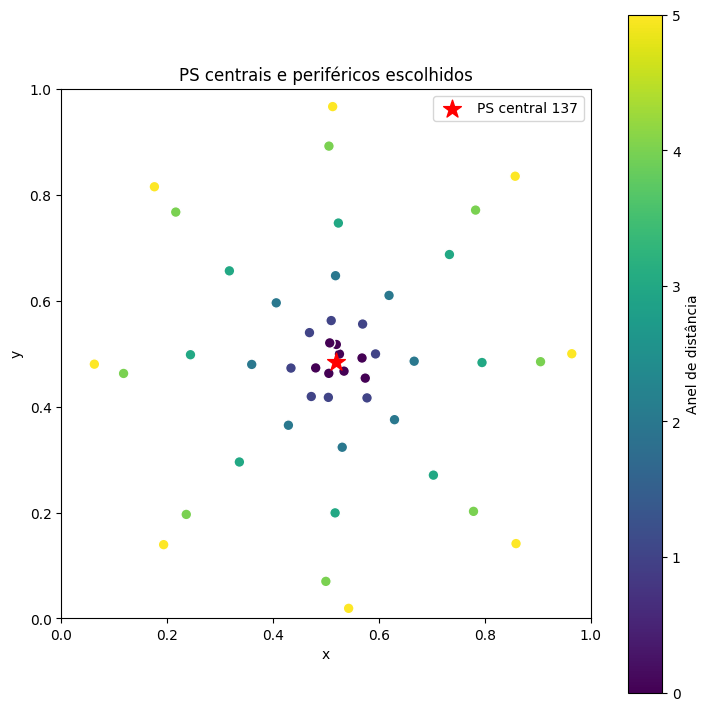

In [2]:
radii=[.03,.08,.16,.28,.40,.48]
sector_count=8
pool=centers[centers.ps_id!=central_id].copy()
pool_xy=pool[['x','y']].to_numpy(float)
pool_ids=pool.ps_id.to_numpy(int)
used=set()
chosen=[]
for ring_id,radius in enumerate(radii):
    for sector in range(sector_count):
        angle=2*np.pi*sector/sector_count
        desired=central_xy+radius*np.array([np.cos(angle),np.sin(angle)])
        error=np.linalg.norm(pool_xy-desired,axis=1)
        ranking=np.argsort(error)
        index=next(int(i) for i in ranking if int(pool_ids[i]) not in used)
        ps_id=int(pool_ids[index]); used.add(ps_id)
        actual_radius=float(np.linalg.norm(pool_xy[index]-central_xy))
        chosen.append((ring_id,sector,radius,ps_id,float(pool_xy[index,0]),float(pool_xy[index,1]),actual_radius))
chosen=pd.DataFrame(chosen,columns=['ring','sector','target_radius','peripheral_ps_id','x','y','distance'])
assert chosen.peripheral_ps_id.nunique()==len(chosen)==len(radii)*sector_count
print('Desvio radial máximo:',round(float((chosen.distance-chosen.target_radius).abs().max()),4))
display(chosen.groupby('ring').distance.agg(['min','median','max']).round(3))

records=[]; pairs=[]
for row in chosen.itertuples(index=False):
    for direction,source,dest in [('centro_para_fora',central_id,row.peripheral_ps_id),
                                  ('fora_para_centro',row.peripheral_ps_id,central_id)]:
        pairs.append([source,dest])
        records.append((row.ring,row.sector,row.target_radius,row.peripheral_ps_id,
                        direction,source,dest,row.distance,row.distance/reference_dt))
inputs=torch.tensor(pairs,dtype=torch.long)
meta=pd.DataFrame(records,columns=['ring','sector','target_radius','peripheral_ps_id',
                                   'direction','source_ps_id','dest_ps_id','distance','pseudo_speed'])
assert inputs.shape==(len(radii)*sector_count*2,2)
assert (meta.loc[meta.direction=='fora_para_centro','dest_ps_id']==central_id).all()
fig,ax=plt.subplots(figsize=(7,7),constrained_layout=True)
scatter=ax.scatter(chosen.x,chosen.y,c=chosen.ring,cmap='viridis',s=60,edgecolor='white')
ax.scatter([central_xy[0]],[central_xy[1]],c='red',s=180,marker='*',label=f'PS central {central_id}')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='x',ylabel='y',title='PS centrais e periféricos escolhidos')
ax.set_aspect('equal'); ax.legend()
fig.colorbar(scatter,ax=ax,label='Anel de distância')
(root/'imgs').mkdir(exist_ok=True)
fig.savefig(root/'imgs/hardpos_pares_centro_contexto10_mapa.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

In [3]:
training_nb=json.loads((root/'navitran_vizz_reboot_gpt_squared_25_span.ipynb').read_text(encoding='utf-8'))
for cell_no in (21,23): exec(''.join(training_nb['cells'][cell_no]['source']),globals())
pad_id=int(ids.max())+1
model=TrajectoryBERT_HardPos(pad_id+1,embed_size=16,num_layers=1,num_heads=1,
                             hidden_dim=32,dropout=.2,pad_token_id=pad_id,max_len=10,causal=True)
model.load_state_dict(torch.load(root/'legacy/checkpoints/HardPos/gpt_model_HardPos.pt',map_location='cpu',weights_only=True))
model.eval()
torch.set_num_threads(min(4,torch.get_num_threads()))
layer=model.encoder.layers[0]

@torch.inference_mode()
def extract(batch):
    emb=model.embedding(batch)
    pos=model.position_embedding(emb)
    q,k,v=F.linear(pos,layer.self_attn.in_proj_weight,layer.self_attn.in_proj_bias).chunk(3,-1)
    attn,_=layer.self_attn(pos,pos,pos,attn_mask=model._causal_mask(batch.shape[1],batch.device),need_weights=False)
    residual=pos+layer.dropout1(attn)
    norm1=layer.norm1(residual)
    ff1=layer.linear1(norm1)
    ff_act=layer.activation(ff1)
    ff2=layer.linear2(layer.dropout(ff_act))
    encoder=layer.norm2(norm1+layer.dropout2(ff2))
    representations={'token_embedding':emb,'attention_output':attn,
                     'attention_norm':norm1,'ff_activation':ff_act,'encoder_output':encoder}
    probabilities=torch.softmax(model.fc_out(encoder[:,0]),dim=-1).gather(1,batch[:,1:2]).squeeze(1)
    return {name:a[:,1].numpy() for name,a in representations.items()},probabilities.numpy(),encoder

blocks={}; probability=[]
for offset in range(0,len(inputs),32):
    batch=inputs[offset:offset+32]
    reps,p,encoder=extract(batch)
    if offset==0:
        with torch.inference_mode():
            direct=model(batch)
            torch.testing.assert_close(model.fc_out(encoder[:,-1]),direct[:,-1],atol=1e-5,rtol=1e-5)
            direct_p=torch.softmax(direct[:,0],dim=-1).gather(1,batch[:,1:2]).squeeze(1)
            torch.testing.assert_close(torch.from_numpy(p),direct_p,atol=1e-6,rtol=1e-6)
    probability.append(p)
    for name,a in reps.items(): blocks.setdefault(name,[]).append(a)
features={}
for name,chunks in blocks.items():
    matrix=np.concatenate(chunks)
    for j in range(matrix.shape[1]): features[f'{name}__d{j:02d}']=matrix[:,j]
results=pd.concat([meta,pd.DataFrame(features)],axis=1)
results['p_destination_given_source']=np.concatenate(probability)
results['surprisal_nats']=-np.log(results.p_destination_given_source.clip(lower=1e-30))
results.to_parquet(root/'legacy/analysis/HardPos_pares_cruzados_centro_contexto10.parquet',index=False)
print('Pares:',len(results),'| dimensões internas:',len(features))

Pares: 96 | dimensões internas: 96


/home/mgteus/workspace/navitrans/.nav/lib/python3.10/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


## Mesmos dois PS nas posições finais do contexto de treino

O primeiro teste usa dois tokens nas posições 0 e 1. Para verificar a sensibilidade à posição absoluta, repetimos os mesmos pares nas posições 7 e 8, equivalentes a 7 tokens de padding no início com máscara de atenção. Não há outros PS no input. Como o encoder possui uma camada, calcular apenas os dois tokens válidos nessas posições produz a mesma ativação final que o modelo com padding inicial; verificamos essa equivalência numericamente.

In [4]:
results_pos01=results.copy()

@torch.inference_mode()
def extract_at_end_positions(batch):
    emb=model.embedding(batch)
    pos=emb+model.position_embedding.pe[7:9].unsqueeze(0)
    q,k,v=F.linear(pos,layer.self_attn.in_proj_weight,layer.self_attn.in_proj_bias).chunk(3,-1)
    attn,_=layer.self_attn(pos,pos,pos,attn_mask=model._causal_mask(2,batch.device),need_weights=False)
    norm1=layer.norm1(pos+layer.dropout1(attn))
    ff_act=layer.activation(layer.linear1(norm1))
    encoder=layer.norm2(norm1+layer.dropout2(layer.linear2(layer.dropout(ff_act))))
    reps={'token_embedding':emb,'attention_output':attn,
          'attention_norm':norm1,'ff_activation':ff_act,'encoder_output':encoder}
    p=torch.softmax(model.fc_out(encoder[:,0]),dim=-1).gather(1,batch[:,1:2]).squeeze(1)
    return {name:a[:,1].numpy() for name,a in reps.items()},p.numpy(),encoder

new_blocks={}; new_probs=[]
for offset in range(0,len(inputs),32):
    pair=inputs[offset:offset+32]
    reps,p,encoder=extract_at_end_positions(pair)
    if offset==0:
        padded=torch.full((len(pair),9),pad_id,dtype=torch.long)
        padded[:,-2:]=pair
        attention_mask=(padded!=pad_id).long()
        with torch.inference_mode():
            direct=model(padded,attention_mask=attention_mask)
            torch.testing.assert_close(model.fc_out(encoder[:,-1]),direct[:,-1],atol=1e-5,rtol=1e-5)
            p_direct=torch.softmax(direct[:,-2],dim=-1).gather(1,pair[:,1:2]).squeeze(1)
            torch.testing.assert_close(torch.from_numpy(p),p_direct,atol=1e-6,rtol=1e-6)
    new_probs.append(p)
    for name,a in reps.items(): new_blocks.setdefault(name,[]).append(a)
new_features={}
for name,chunks in new_blocks.items():
    matrix=np.concatenate(chunks)
    for j in range(matrix.shape[1]): new_features[f'{name}__d{j:02d}']=matrix[:,j]
results=pd.concat([meta,pd.DataFrame(new_features)],axis=1)
results['p_destination_given_source']=np.concatenate(new_probs)
results['surprisal_nats']=-np.log(results.p_destination_given_source.clip(lower=1e-30))
results.to_parquet(root/'legacy/analysis/HardPos_pares_cruzados_centro_contexto10_leftpad.parquet',index=False)
print('Equivalência com padding inicial confirmada; pares:',len(results))
print('ff_activation__d06 ativa no teste sem padding:',int((results_pos01['ff_activation__d06']>0).sum()),
      'e nas posições finais:',int((results['ff_activation__d06']>0).sum()))

Equivalência com padding inicial confirmada; pares: 96
ff_activation__d06 ativa no teste sem padding: 3 e nas posições finais: 4


## O modelo reconhece a diferença de distância?

A probabilidade do destino é calculada após ver apenas o PS de origem. Um salto improvável no sentido centro → fora pode continuar improvável no sentido inverso. A ativação de uma dimensão, porém, pode responder diferentemente aos dois sentidos. O embedding do token final funciona como controle: no sentido fora → centro, ele é idêntico em todos os pares, porque o último PS está fixo.

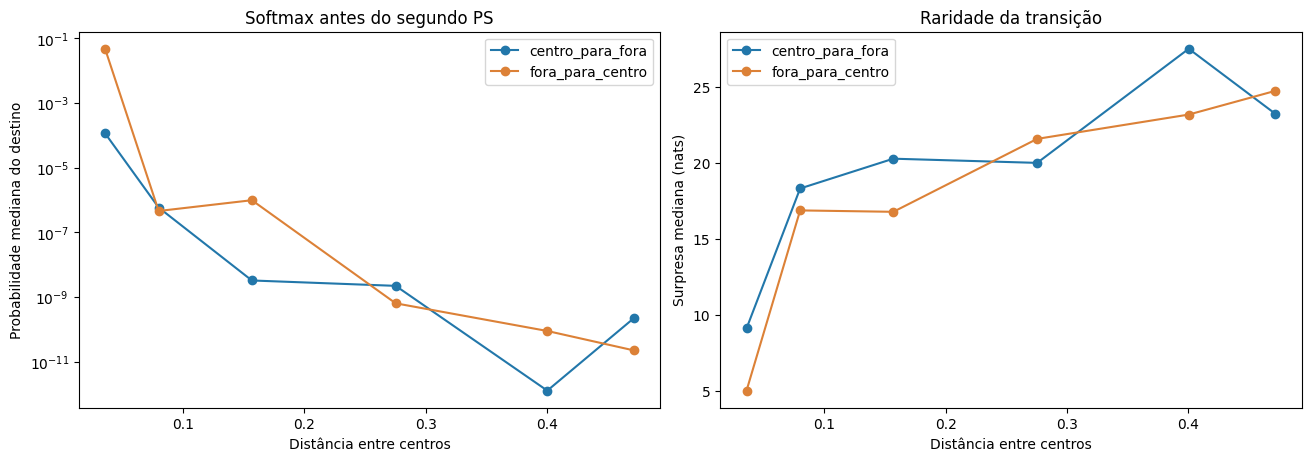

distance  pseudo_speed  p_destination_given_source
direction        ring                                                    
centro_para_fora 0      0.03575       0.23833                     0.00012
                 1      0.07964       0.53091                     0.00000
                 2      0.15947       1.06313                     0.00000
                 3      0.27548       1.83651                     0.00000
                 4      0.40296       2.68643                     0.00000
                 5      0.47576       3.17175                     0.00000
fora_para_centro 0      0.03575       0.23833                     0.04771
                 1      0.07964       0.53091                     0.00000
                 2      0.15947       1.06313                     0.00000
                 3      0.27548       1.83651                     0.00000
                 4      0.40296       2.68643                     0.00000
                 5      0.47576       3.17175                     0.00000

In [5]:
order=['centro_para_fora','fora_para_centro']
fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for direction,color in zip(order,['#2277aa','#dc8137']):
    part=results[results.direction==direction]
    grouped=part.groupby('ring').agg(distance=('distance','mean'),
                                     probability=('p_destination_given_source','median'),
                                     surprise=('surprisal_nats','median'))
    axes[0].plot(grouped.distance,grouped.probability,marker='o',color=color,label=direction)
    axes[1].plot(grouped.distance,grouped.surprise,marker='o',color=color,label=direction)
axes[0].set_yscale('log')
axes[0].set(xlabel='Distância entre centros',ylabel='Probabilidade mediana do destino',title='Softmax antes do segundo PS')
axes[1].set(xlabel='Distância entre centros',ylabel='Surpresa mediana (nats)',title='Raridade da transição')
for ax in axes: ax.legend()
fig.savefig(root/'imgs/hardpos_pares_centro_contexto10_softmax.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)
display(results.groupby(['direction','ring'])[['distance','pseudo_speed','p_destination_given_source']].median().round(5))

## Ativações em ambos os sentidos

Calculamos a correlação de Spearman de cada dimensão com a distância nos dois sentidos. Para uma resposta compartilhada, exigimos o mesmo sinal nas duas correlações. Metade dos setores angulares seleciona a candidata; a outra metade verifica se a relação se repete em direções não usadas na escolha. Também mostramos a unidade ff_activation__d06, que respondeu aos saltos extremos no experimento anterior.

Unidades escolhidas: ['ff_activation__d06', 'ff_activation__d17', 'encoder_output__d11']


direction                        centro_para_fora  fora_para_centro
feature             sectors                                        
encoder_output__d11 selecao                 0.157             0.217
                    todos                   0.207             0.163
                    verificacao             0.228             0.090
ff_activation__d06  selecao                 0.105               NaN
                    todos                   0.096               NaN
                    verificacao             0.097               NaN
ff_activation__d17  selecao                -0.136            -0.104
                    todos                  -0.273            -0.046
                    verificacao            -0.386            -0.030

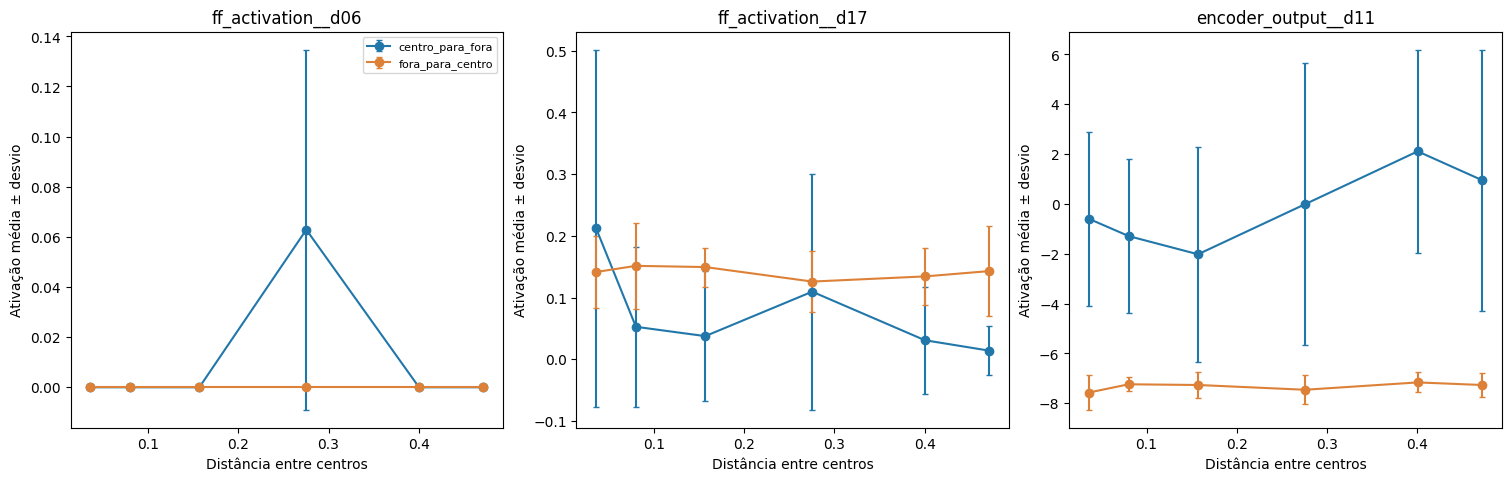

In [6]:
feature_cols=list(features)
rows=[]
for feature in feature_cols:
    for sector_set,sectors in [('selecao',[0,2,4,6]),('verificacao',[1,3,5,7]),('todos',list(range(8)))]:
        for direction in order:
            part=results[(results.direction==direction)&(results.sector.isin(sectors))]
            a=part[feature].to_numpy(float)
            rho=float(spearmanr(part.distance,a).statistic) if np.std(a)>1e-10 else np.nan
            rows.append((feature,feature.rsplit('__d',1)[0],sector_set,direction,rho))
scores=pd.DataFrame(rows,columns=['feature','stage','sectors','direction','rho'])
scores.to_csv(notebook_csv_path('HardPos_pares_cruzados_centro_contexto10', 'HardPos_pares_cruzados_scores.csv'),index=False)
selection=scores[scores.sectors=='selecao'].pivot(index=['feature','stage'],columns='direction',values='rho').reset_index()
a=selection.centro_para_fora.to_numpy(float)
b=selection.fora_para_centro.to_numpy(float)
selection['shared_score']=np.where(np.sign(a)==np.sign(b),np.minimum(np.abs(a),np.abs(b)),0)
selection['shared_score']=selection.shared_score.fillna(0)
ff_best=(selection[selection.stage=='ff_activation'].sort_values('shared_score',ascending=False).iloc[0].feature)
encoder_best=(selection[selection.stage=='encoder_output'].sort_values('shared_score',ascending=False).iloc[0].feature)
shown=list(dict.fromkeys(['ff_activation__d06',ff_best,encoder_best]))
print('Unidades escolhidas:',shown)
display(scores[scores.feature.isin(shown)].pivot(index=['feature','sectors'],columns='direction',values='rho').round(3))

fig,axes=plt.subplots(1,len(shown),figsize=(5*len(shown),4.7),constrained_layout=True)
axes=np.atleast_1d(axes)
for ax,feature in zip(axes,shown):
    for direction,color in zip(order,['#2277aa','#dc8137']):
        part=results[results.direction==direction]
        grouped=part.groupby('ring').agg(distance=('distance','mean'),activation=(feature,'mean'),
                                         variation=(feature,'std'))
        ax.errorbar(grouped.distance,grouped.activation,yerr=grouped.variation,
                    marker='o',capsize=2,color=color,label=direction)
    ax.set(xlabel='Distância entre centros',ylabel='Ativação média ± desvio',title=feature)
axes[0].legend(fontsize=8)
fig.savefig(root/'imgs/hardpos_pares_centro_contexto10_ativacoes.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

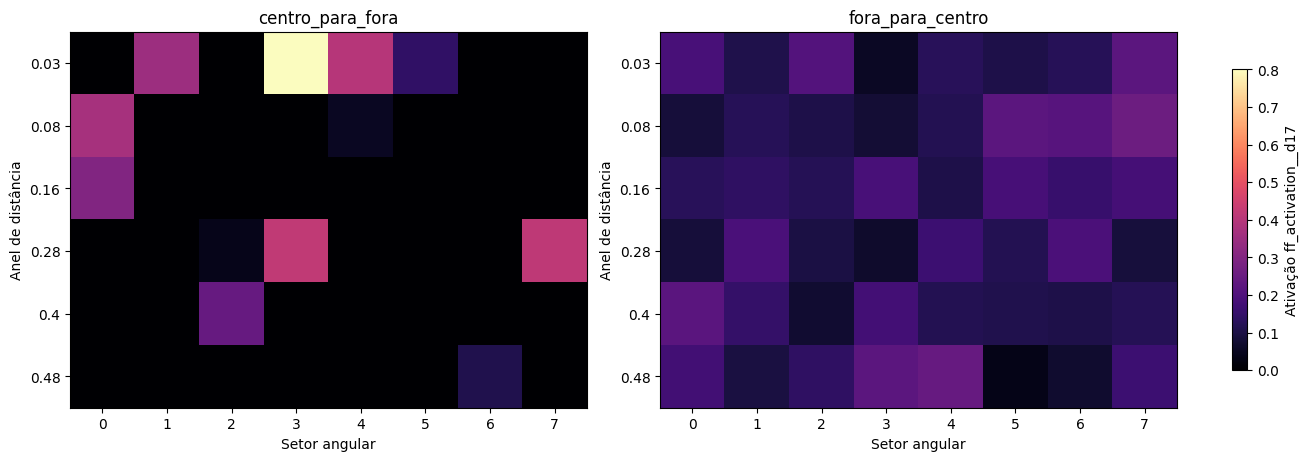

ff_activation__d06 verificação: centro_para_fora rho=+0.097, fora_para_centro rho=+nan
ff_activation__d17 verificação: centro_para_fora rho=-0.386, fora_para_centro rho=-0.030
encoder_output__d11 verificação: centro_para_fora rho=+0.228, fora_para_centro rho=+0.090


In [7]:
# Mapa de ativação por distância e direção para a unidade do feedforward selecionada.
unit=ff_best
fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for ax,direction in zip(axes,order):
    part=results[results.direction==direction]
    matrix=part.pivot(index='ring',columns='sector',values=unit).to_numpy(float)
    im=ax.imshow(matrix,aspect='auto',cmap='magma',vmin=0,vmax=max(results[unit].max(),1e-6))
    ax.set(xlabel='Setor angular',ylabel='Anel de distância',title=direction)
    ax.set_xticks(range(8)); ax.set_yticks(range(len(radii)),[str(r) for r in radii])
fig.colorbar(im,ax=axes,label='Ativação '+unit,shrink=.8)
fig.savefig(root/'imgs/hardpos_pares_centro_contexto10_unidade_mapa.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

# Avaliação direta: a resposta da unidade anterior em ambos os sentidos.
for feature in shown:
    part=scores[(scores.feature==feature)&(scores.sectors=='verificacao')]
    print(feature,'verificação:',', '.join(f'{row.direction} rho={row.rho:+.3f}' for row in part.itertuples()))

## Repetição com histórico real de 7 PS

Os pares isolados têm comprimento menor que a entrada de 9 tokens usada no treino. Repetimos o experimento nas ocorrências reais do PS central: preservamos os 7 PS anteriores e variamos apenas os dois tokens finais entre centro → periférico e periférico → centro. Todos os contextos continuam causais. No sentido inverso, o penúltimo PS sintético pode criar também uma transição inédita com o token anterior do histórico; interpretamos esse braço com cautela.

Ocorrências reais do PS central: 10 | contextos sintéticos: 960


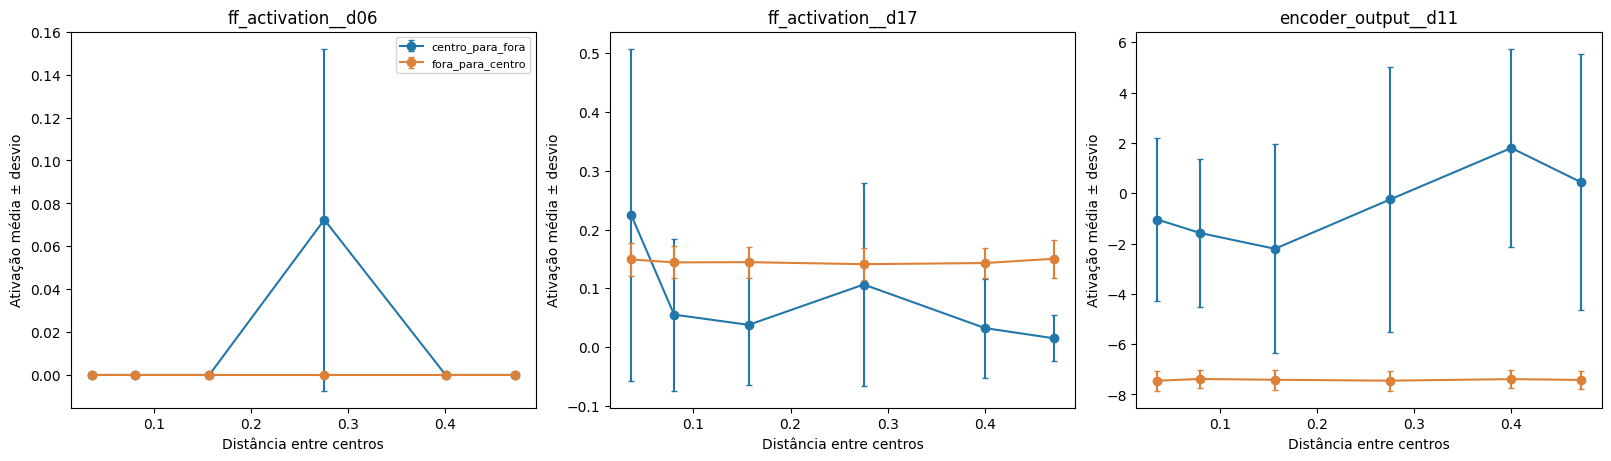

centro_para_fora ff d06 ativou em 0.083 das variantes com histórico real
fora_para_centro ff d06 ativou em 0.0 das variantes com histórico real


In [8]:
central_times=np.flatnonzero(ids==central_id)
central_times=central_times[central_times>=7]
split_boundary=int(.8*len(ids))
central_times=np.array([t for t in central_times if t<split_boundary or t-7>=split_boundary],dtype=int)
full_inputs=[]; full_rows=[]
for t in central_times:
    prefix=ids[t-7:t]
    assert len(prefix)==7
    part='treino' if t<split_boundary else 'teste'
    for row in chosen.itertuples(index=False):
        for direction,source,dest in [('centro_para_fora',central_id,row.peripheral_ps_id),
                                      ('fora_para_centro',row.peripheral_ps_id,central_id)]:
            full_inputs.append(np.r_[prefix,source,dest])
            full_rows.append((int(t),part,row.ring,row.sector,row.peripheral_ps_id,
                              direction,row.distance,source,dest))
full_inputs=torch.tensor(np.stack(full_inputs),dtype=torch.long)
full_meta=pd.DataFrame(full_rows,columns=['central_t','split','ring','sector','peripheral_ps_id',
                                          'direction','distance','source_ps_id','dest_ps_id'])
assert full_inputs.shape[1]==9
print('Ocorrências reais do PS central:',len(central_times),'| contextos sintéticos:',len(full_inputs))

ff_index=int(ff_best.rsplit('__d',1)[1])
encoder_index=int(encoder_best.rsplit('__d',1)[1])

@torch.inference_mode()
def extract_full(batch):
    emb=model.embedding(batch)
    pos=model.position_embedding(emb)
    attn,_=layer.self_attn(pos,pos,pos,attn_mask=model._causal_mask(9,batch.device),need_weights=False)
    norm1=layer.norm1(pos+layer.dropout1(attn))
    ff_act=layer.activation(layer.linear1(norm1))
    encoder=layer.norm2(norm1+layer.dropout2(layer.linear2(layer.dropout(ff_act))))
    return {'ff_activation__d06':ff_act[:,-1,6].numpy(),
            ff_best:ff_act[:,-1,ff_index].numpy(),
            encoder_best:encoder[:,-1,encoder_index].numpy()},encoder
full_blocks={}
for offset in range(0,len(full_inputs),24):
    batch=full_inputs[offset:offset+24]
    values,encoder=extract_full(batch)
    if offset==0:
        with torch.inference_mode():
            torch.testing.assert_close(model.fc_out(encoder[:,-1]),model(batch)[:,-1],atol=1e-5,rtol=1e-5)
    for name,a in values.items(): full_blocks.setdefault(name,[]).append(a)
full_results=full_meta.copy()
for name,chunks in full_blocks.items(): full_results[name]=np.concatenate(chunks)
full_results.to_parquet(root/'legacy/analysis/HardPos_pares_cruzados_centro_contexto10_contexto_real.parquet',index=False)

fig,axes=plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
for ax,feature in zip(axes,['ff_activation__d06',ff_best,encoder_best]):
    for direction,color in zip(order,['#2277aa','#dc8137']):
        part=full_results[full_results.direction==direction]
        grouped=part.groupby('ring').agg(distance=('distance','mean'),activation=(feature,'mean'),
                                         spread=(feature,'std'))
        ax.errorbar(grouped.distance,grouped.activation,yerr=grouped.spread,
                    marker='o',capsize=2,color=color,label=direction)
    ax.set(xlabel='Distância entre centros',ylabel='Ativação média ± desvio',title=feature)
axes[0].legend(fontsize=8)
fig.savefig(root/'imgs/hardpos_pares_centro_contexto10_contexto_real.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)
for direction in order:
    part=full_results[full_results.direction==direction]
    print(direction,'ff d06 ativou em',round(float((part['ff_activation__d06']>0).mean()),3),
          'das variantes com histórico real')

## FF1 e FF2: pesos, ativações e dimensões

Nesta seção, FF1 é a transformação linear de 16 para 32 dimensões; a não linearidade gera 32 ativações; FF2 transforma essas 32 ativações de volta para 16. Calculamos cada estágio na última posição do input para os pares isolados e para os contextos de 9 tokens. Os pesos W1 e W2 são **fixos** para todos os destinos e distâncias. Para mostrar o que muda em cada cenário, os mapas seguintes usam W1 multiplicado pela entrada média de FF1 e W2 multiplicado pela ativação média das 32 unidades. Os vieses são mostrados numericamente na checagem da reconstrução.

Checagem: FF1 = W1 × entrada + b1; FF2 = W2 × ReLU + b2, em ambos os modos.
Linhas: 1056 | W1: (32, 16) | W2: (16, 32)


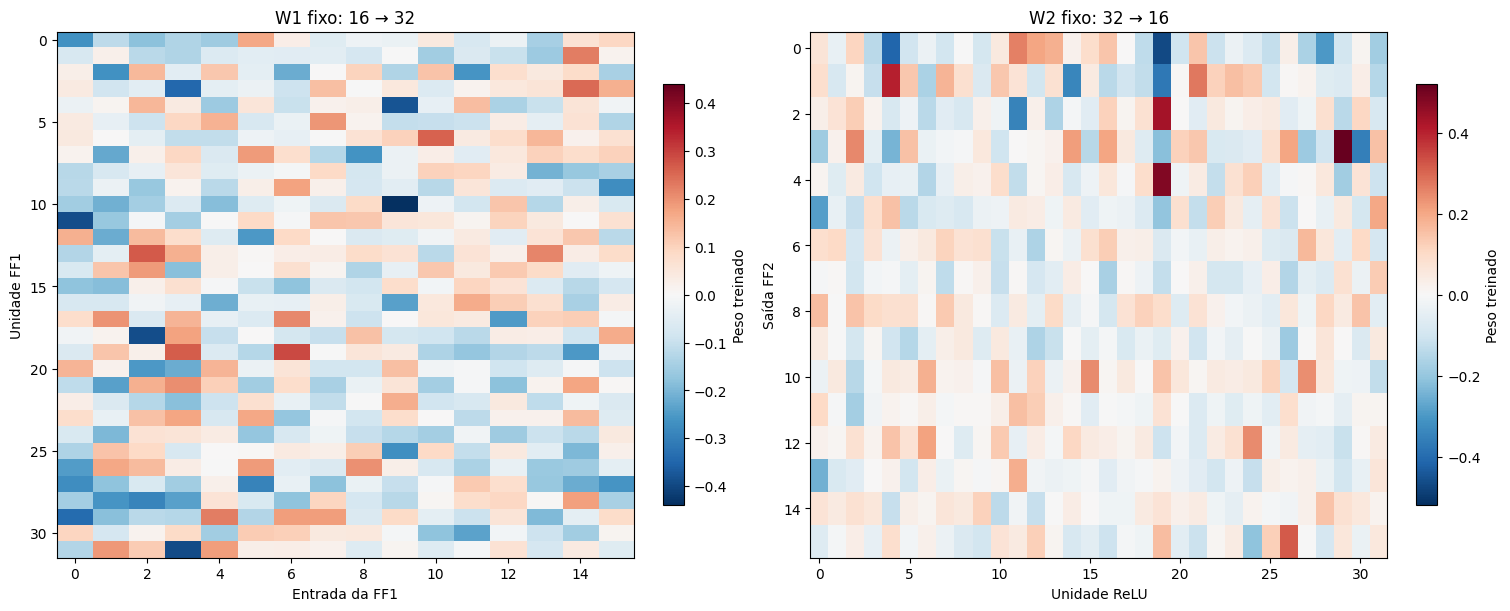

In [9]:
@torch.inference_mode()
def trace_feedforward(batch, pair_at_end=False):
    emb=model.embedding(batch)
    pos=emb+model.position_embedding.pe[7:9].unsqueeze(0) if pair_at_end else model.position_embedding(emb)
    attn,_=layer.self_attn(pos,pos,pos,attn_mask=model._causal_mask(batch.shape[1],batch.device),need_weights=False)
    norm1=layer.norm1(pos+layer.dropout1(attn))
    ff1=layer.linear1(norm1)
    relu=layer.activation(ff1)
    ff2=layer.linear2(layer.dropout(relu))
    encoder=layer.norm2(norm1+layer.dropout2(ff2))
    return {'attnorm':norm1[:,-1].numpy(),'ff1':ff1[:,-1].numpy(),
            'relu':relu[:,-1].numpy(),'ff2':ff2[:,-1].numpy(),
            'encoder':encoder[:,-1].numpy()}

trace_tables=[]
for mode,batches,metadata,pair_mode in [
    ('par_curto',inputs,meta,True),('historico_9',full_inputs,full_meta,False)]:
    accumulated={}
    for offset in range(0,len(batches),32):
        values=trace_feedforward(batches[offset:offset+32],pair_at_end=pair_mode)
        for stage,a in values.items():accumulated.setdefault(stage,[]).append(a)
    table=metadata[['ring','sector','direction','distance','peripheral_ps_id']].copy()
    table['mode']=mode
    stage_tables=[]
    for stage,chunks in accumulated.items():
        matrix=np.concatenate(chunks)
        values={f'{stage}__d{j:02d}':matrix[:,j] for j in range(matrix.shape[1])}
        values[f'{stage}_mean_abs']=np.abs(matrix).mean(axis=1)
        stage_tables.append(pd.DataFrame(values,index=table.index))
    table=pd.concat([table,*stage_tables],axis=1)
    relu_matrix=np.concatenate(accumulated['relu'])
    table['relu_fraction_active']=(relu_matrix>0).mean(axis=1)
    trace_tables.append(table)
trace=pd.concat(trace_tables,ignore_index=True)
trace.to_parquet(root/'legacy/analysis/HardPos_ffw_contexto10_ativacoes.parquet',index=False)
W1=layer.linear1.weight.detach().numpy()
b1=layer.linear1.bias.detach().numpy()
W2=layer.linear2.weight.detach().numpy()
b2=layer.linear2.bias.detach().numpy()
assert W1.shape==(32,16) and W2.shape==(16,32)
for mode in trace['mode'].unique():
    part=trace[trace['mode']==mode]
    x=part[[f'attnorm__d{i:02d}' for i in range(16)]].to_numpy(float)
    a=part[[f'relu__d{i:02d}' for i in range(32)]].to_numpy(float)
    z1=part[[f'ff1__d{i:02d}' for i in range(32)]].to_numpy(float)
    z2=part[[f'ff2__d{i:02d}' for i in range(16)]].to_numpy(float)
    np.testing.assert_allclose(x@W1.T+b1,z1,rtol=1e-5,atol=1e-5)
    np.testing.assert_allclose(a@W2.T+b2,z2,rtol=1e-5,atol=1e-5)
print('Checagem: FF1 = W1 × entrada + b1; FF2 = W2 × ReLU + b2, em ambos os modos.')
print('Linhas:',len(trace),'| W1:',W1.shape,'| W2:',W2.shape)

fig,axes=plt.subplots(1,2,figsize=(15,6),constrained_layout=True)
for ax,weight,title,xlabel,ylabel in [
    (axes[0],W1,'W1 fixo: 16 → 32','Entrada da FF1','Unidade FF1'),
    (axes[1],W2,'W2 fixo: 32 → 16','Unidade ReLU','Saída FF2')]:
    bound=float(np.max(np.abs(weight)))
    im=ax.imshow(weight,aspect='auto',cmap='RdBu_r',vmin=-bound,vmax=bound)
    ax.set(xlabel=xlabel,ylabel=ylabel,title=title)
    fig.colorbar(im,ax=ax,shrink=.8,label='Peso treinado')
fig.savefig(root/'imgs/hardpos_ffw_contexto10_pesos_fixos.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

### Média da camada e atividade de cada dimensão

A curva resume a média do valor absoluto das dimensões em cada estágio. Para a saída ReLU, o valor absoluto é igual à ativação. Os mapas mostram, separadamente, a média de **cada** uma das 32 unidades FF1/ReLU e das 16 dimensões FF2/encoder, agregando os oito setores de cada distância; no modo com histórico, também agregamos as dez ocorrências reais do PS central.

Médias por etapa e fração ReLU ativa: par_curto


attnorm_mean_abs  ff1_mean_abs  relu_mean_abs  \
direction        ring                                                  
centro_para_fora 0                0.551         0.410          0.029   
                 1                0.592         0.388          0.019   
                 2                0.638         0.390          0.033   
                 3                0.620         0.433          0.026   
                 4                0.592         0.416          0.015   
                 5                0.596         0.409          0.025   
fora_para_centro 0                0.638         0.457          0.050   
                 1                0.657         0.461          0.051   
                 2                0.656         0.462          0.051   
                 3                0.642         0.454          0.050   
                 4                0.664         0.464          0.056   
                 5                0.645         0.462          0.053   

                       ff2_mean_abs  encoder_mean_abs  relu_fraction_active  
direction        ring                                                        
centro_para_fora 0            0.031             3.228                 0.148  
                 1            0.021             3.226                 0.137  
                 2            0.034             3.260                 0.199  
                 3            0.028             3.205                 0.152  
                 4            0.020             3.350                 0.121  
                 5            0.026             3.312                 0.152  
fora_para_centro 0            0.051             3.352                 0.238  
                 1            0.051             3.399                 0.238  
                 2            0.050             3.314                 0.230  
                 3            0.049             3.307                 0.262  
                 4            0.057             3.331                 0.262  
                 5            0.051             3.315                 0.246

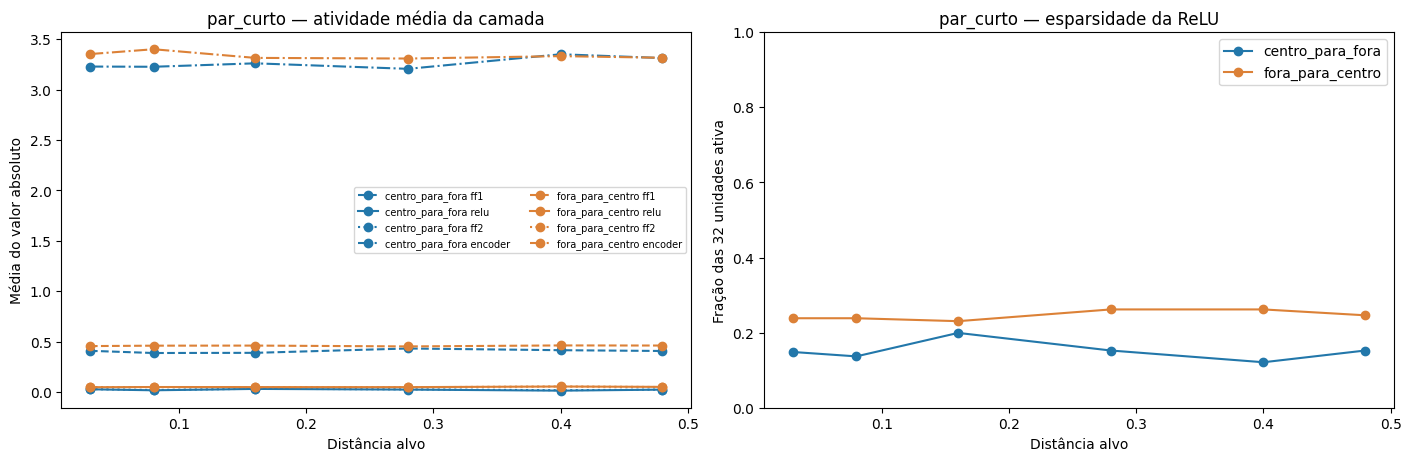

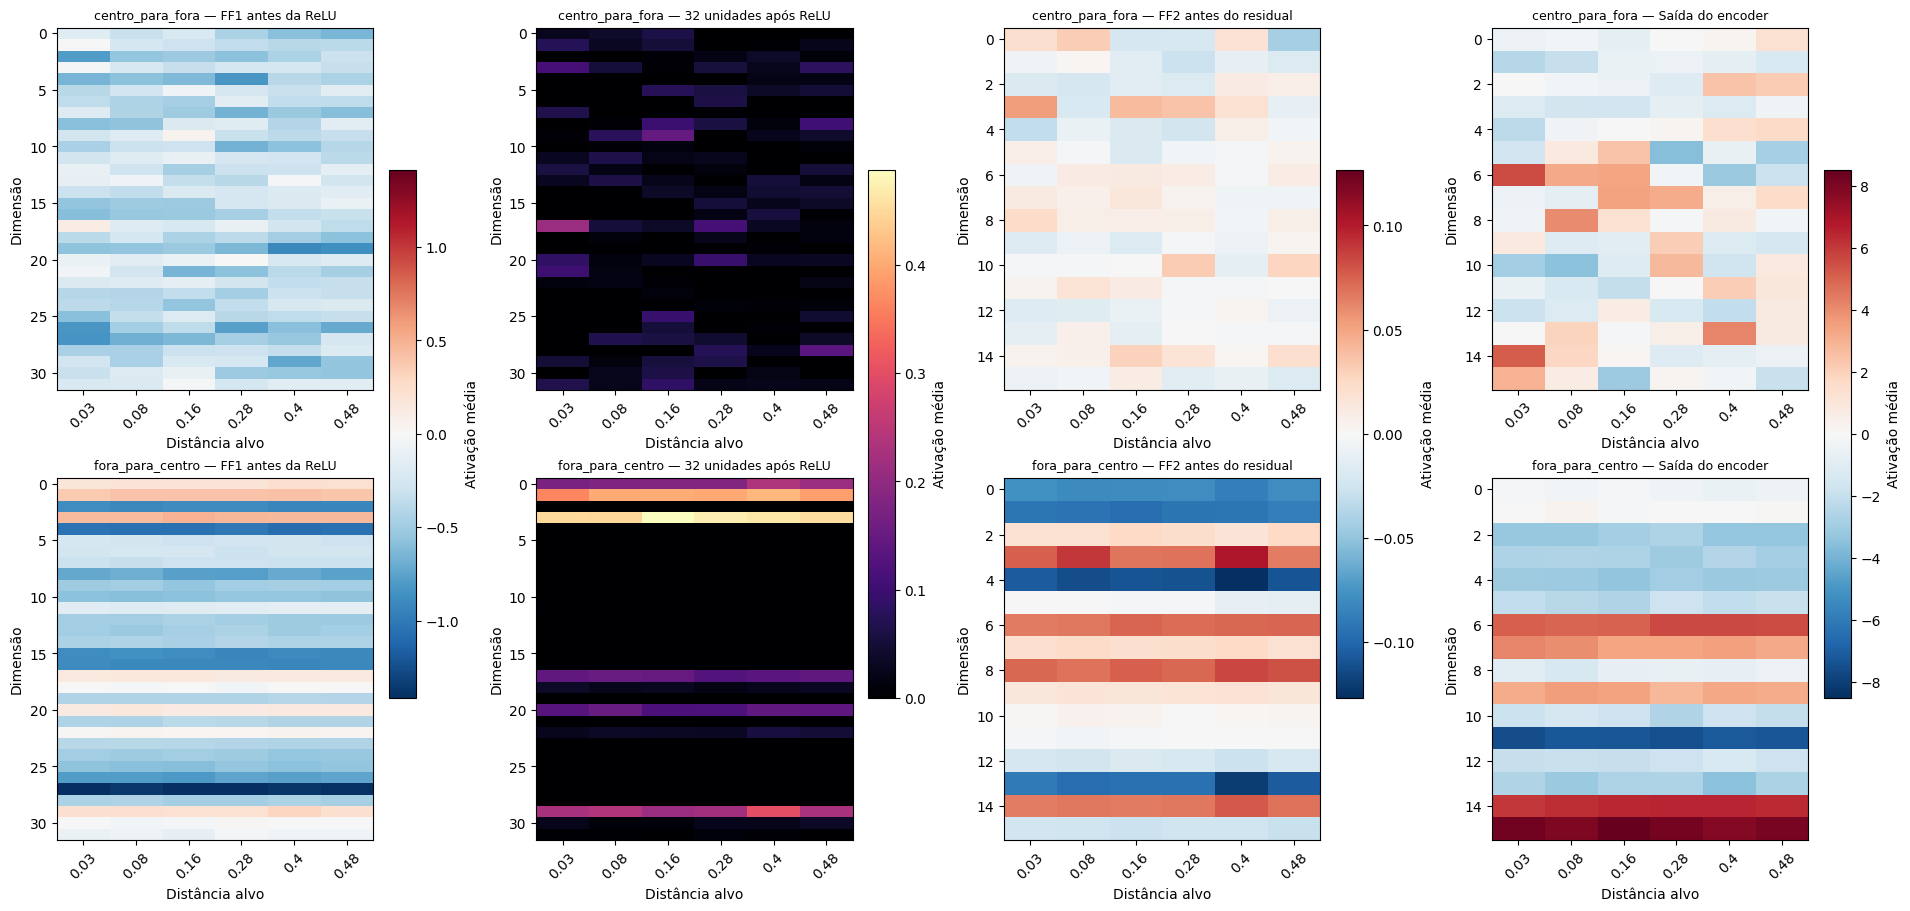

Médias por etapa e fração ReLU ativa: historico_9


attnorm_mean_abs  ff1_mean_abs  relu_mean_abs  \
direction        ring                                                  
centro_para_fora 0                0.570         0.416          0.032   
                 1                0.605         0.392          0.021   
                 2                0.650         0.395          0.035   
                 3                0.635         0.436          0.028   
                 4                0.593         0.420          0.016   
                 5                0.603         0.412          0.027   
fora_para_centro 0                0.660         0.462          0.052   
                 1                0.658         0.463          0.052   
                 2                0.659         0.462          0.052   
                 3                0.656         0.461          0.052   
                 4                0.660         0.463          0.053   
                 5                0.658         0.463          0.053   

                       ff2_mean_abs  encoder_mean_abs  relu_fraction_active  
direction        ring                                                        
centro_para_fora 0            0.034             3.248                 0.170  
                 1            0.024             3.229                 0.136  
                 2            0.037             3.248                 0.195  
                 3            0.031             3.202                 0.155  
                 4            0.021             3.340                 0.122  
                 5            0.028             3.300                 0.143  
fora_para_centro 0            0.052             3.388                 0.245  
                 1            0.052             3.396                 0.239  
                 2            0.052             3.391                 0.242  
                 3            0.052             3.389                 0.243  
                 4            0.053             3.386                 0.241  
                 5            0.052             3.387                 0.245

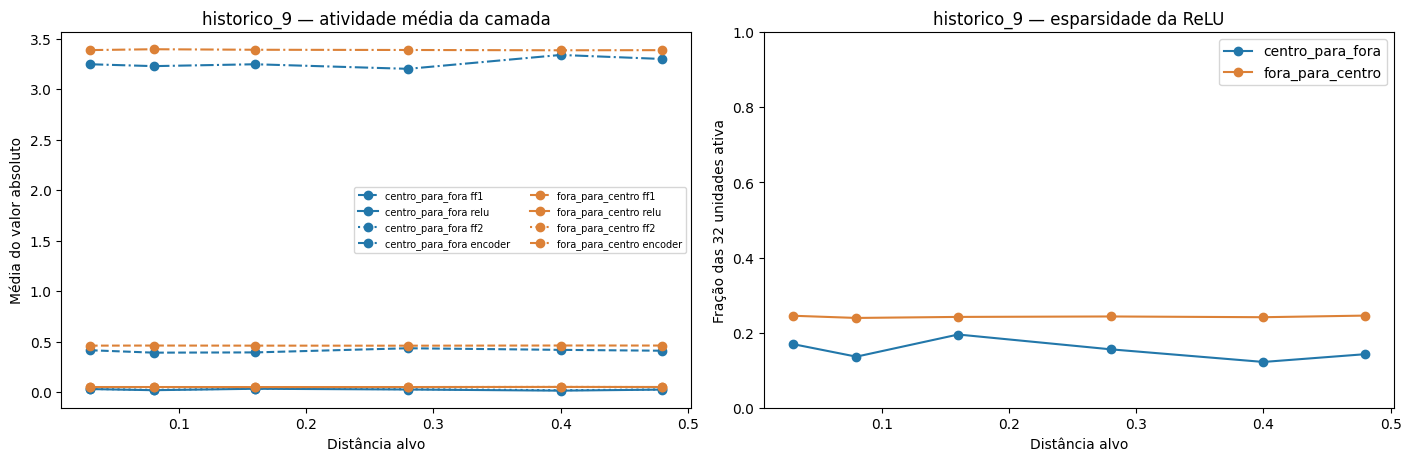

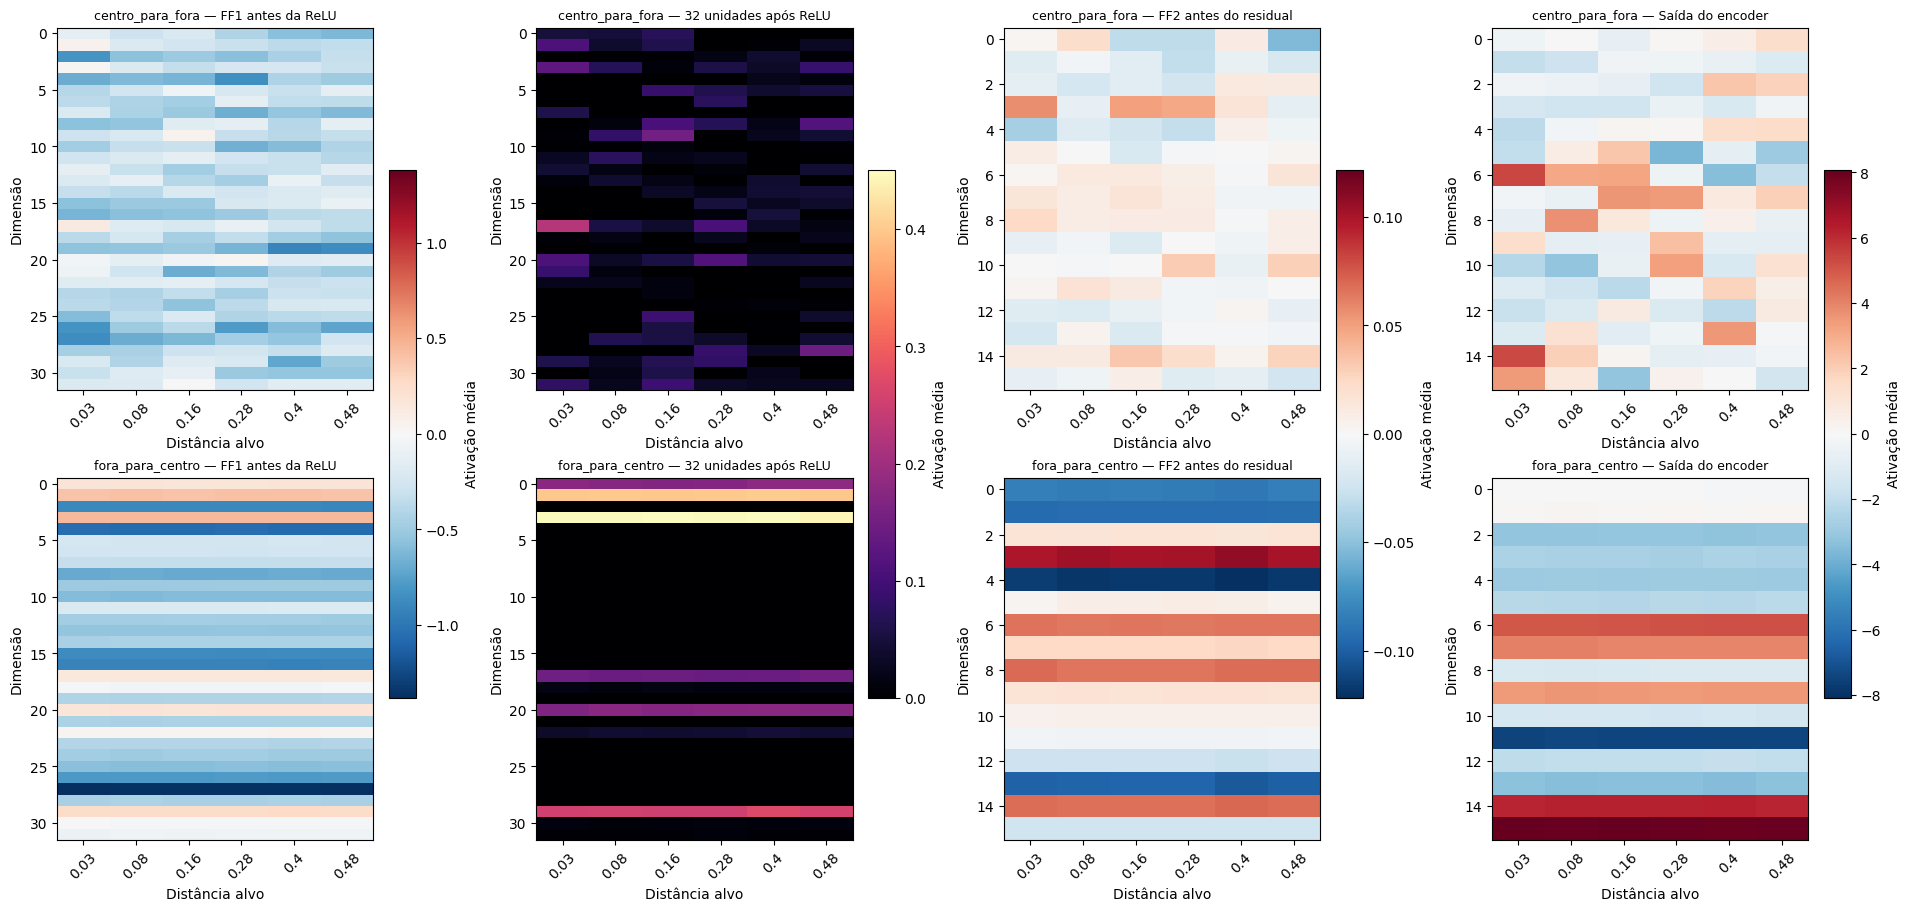

In [10]:
stage_config=[('ff1',32,'FF1 antes da ReLU','RdBu_r'),('relu',32,'32 unidades após ReLU','magma'),
              ('ff2',16,'FF2 antes do residual','RdBu_r'),('encoder',16,'Saída do encoder','RdBu_r')]
for mode in ['par_curto','historico_9']:
    part=trace[trace['mode']==mode]
    summary=part.groupby(['direction','ring'])[['attnorm_mean_abs','ff1_mean_abs','relu_mean_abs',
                                                'ff2_mean_abs','encoder_mean_abs','relu_fraction_active']].mean()
    print('Médias por etapa e fração ReLU ativa:',mode)
    display(summary.round(3))
    fig,axes=plt.subplots(1,2,figsize=(14,4.5),constrained_layout=True)
    for direction,color in zip(order,['#2277aa','#dc8137']):
        subset=summary.loc[direction]
        x=[radii[i] for i in subset.index]
        for stage,style in [('ff1','--'),('relu','-'),('ff2',':'),('encoder','-.')]:
            axes[0].plot(x,subset[f'{stage}_mean_abs'],marker='o',ls=style,color=color,
                         label=direction+' '+stage)
        axes[1].plot(x,subset.relu_fraction_active,marker='o',color=color,label=direction)
    axes[0].set(xlabel='Distância alvo',ylabel='Média do valor absoluto',title=mode+' — atividade média da camada')
    axes[0].legend(fontsize=7,ncol=2)
    axes[1].set(xlabel='Distância alvo',ylabel='Fração das 32 unidades ativa',ylim=(0,1),
                title=mode+' — esparsidade da ReLU')
    axes[1].legend()
    fig.savefig(root/f'imgs/hardpos_ffw_contexto10_media_{mode}.png',dpi=150,bbox_inches='tight')
    display(fig)
    plt.close(fig)

    fig,axes=plt.subplots(2,4,figsize=(19,9),constrained_layout=True)
    for col,(stage,width,title,cmap) in enumerate(stage_config):
        columns=[f'{stage}__d{i:02d}' for i in range(width)]
        values=part.groupby(['direction','ring'])[columns].mean()
        bound=float(np.max(np.abs(values.to_numpy())))
        vmax=bound if bound>1e-9 else 1e-9
        for row,direction in enumerate(order):
            matrix=values.loc[direction].to_numpy().T
            im=axes[row,col].imshow(matrix,aspect='auto',cmap=cmap,
                                    vmin=0 if stage=='relu' else -vmax,vmax=vmax)
            axes[row,col].set_title(direction+' — '+title,fontsize=9)
            axes[row,col].set_xticks(range(len(radii)),[str(r) for r in radii],rotation=45)
            axes[row,col].set_xlabel('Distância alvo')
            axes[row,col].set_ylabel('Dimensão')
        fig.colorbar(im,ax=axes[:,col],shrink=.65,label='Ativação média')
    fig.savefig(root/f'imgs/hardpos_ffw_contexto10_dimensoes_{mode}.png',dpi=140,bbox_inches='tight')
    display(fig)
    plt.close(fig)

### Matrizes de contribuição em cada distância

As figuras seguintes têm seis colunas, uma por distância, e duas linhas, uma por sentido. Em FF1, cada pixel é W1[j,i] multiplicado pela ativação média da dimensão i que entra na camada. Em FF2, cada pixel é W2[k,j] multiplicado pela ativação média da unidade j após a ReLU. Esses mapas mudam entre cenários porque a **entrada da camada muda**; os pesos W1 e W2 permanecem os mesmos. O viés é constante em todos os cenários e não aparece nos pixels.

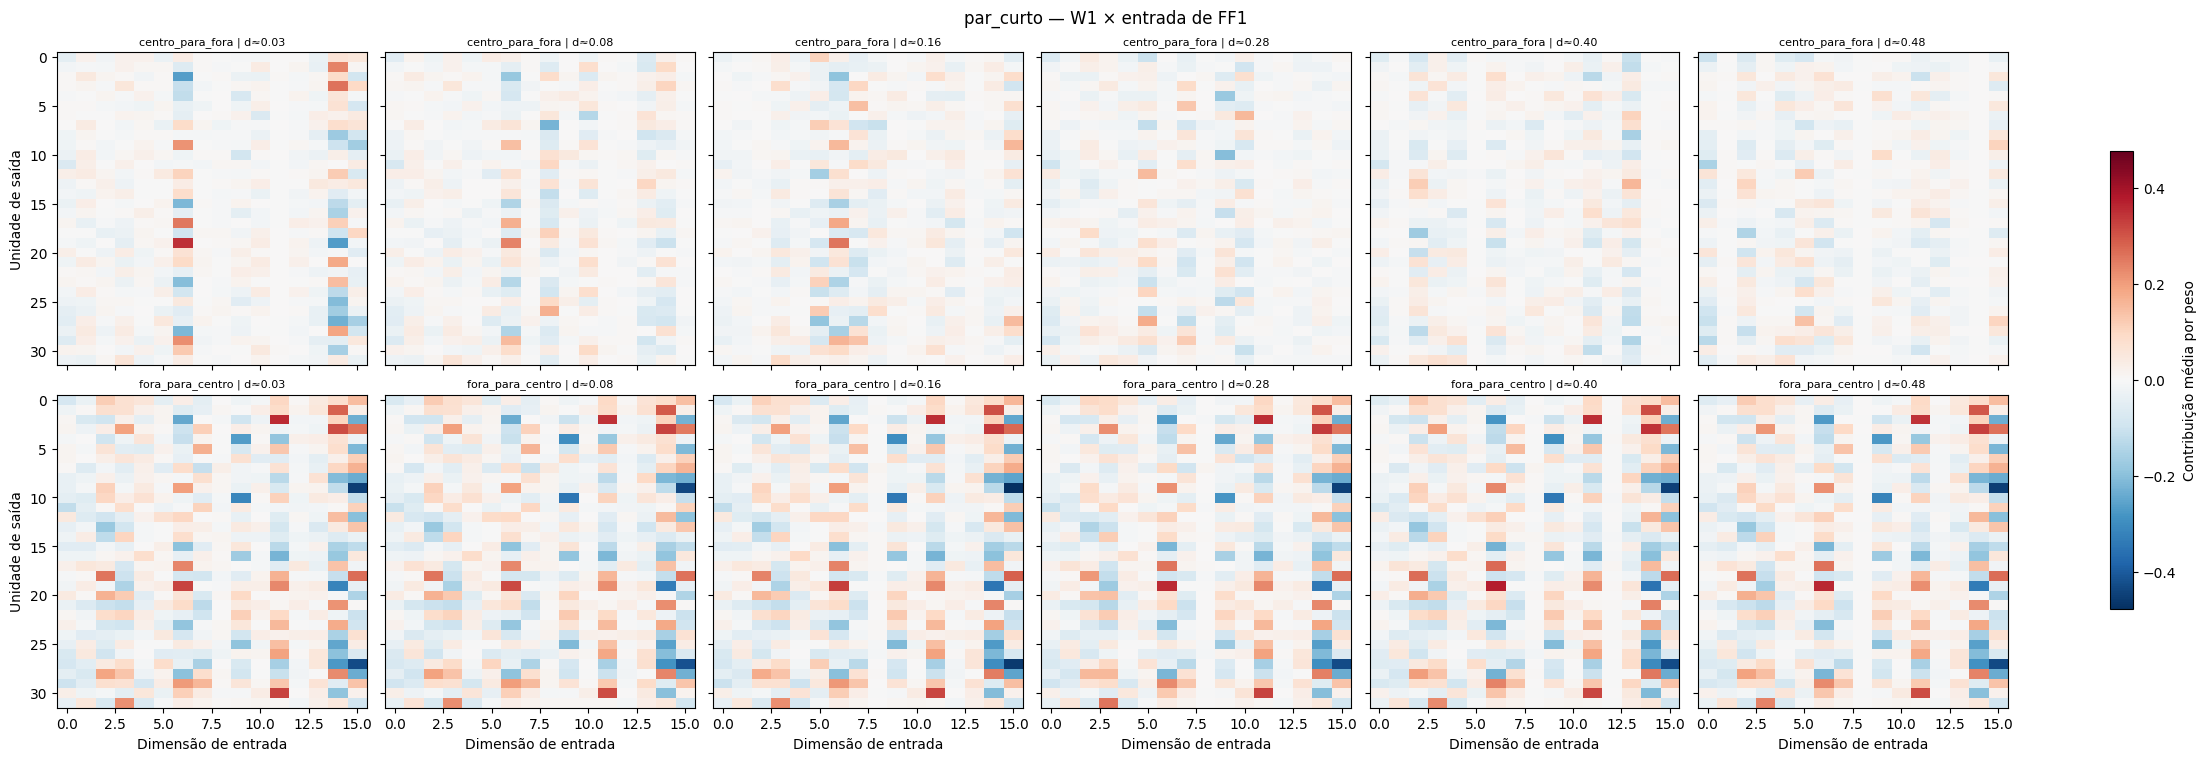

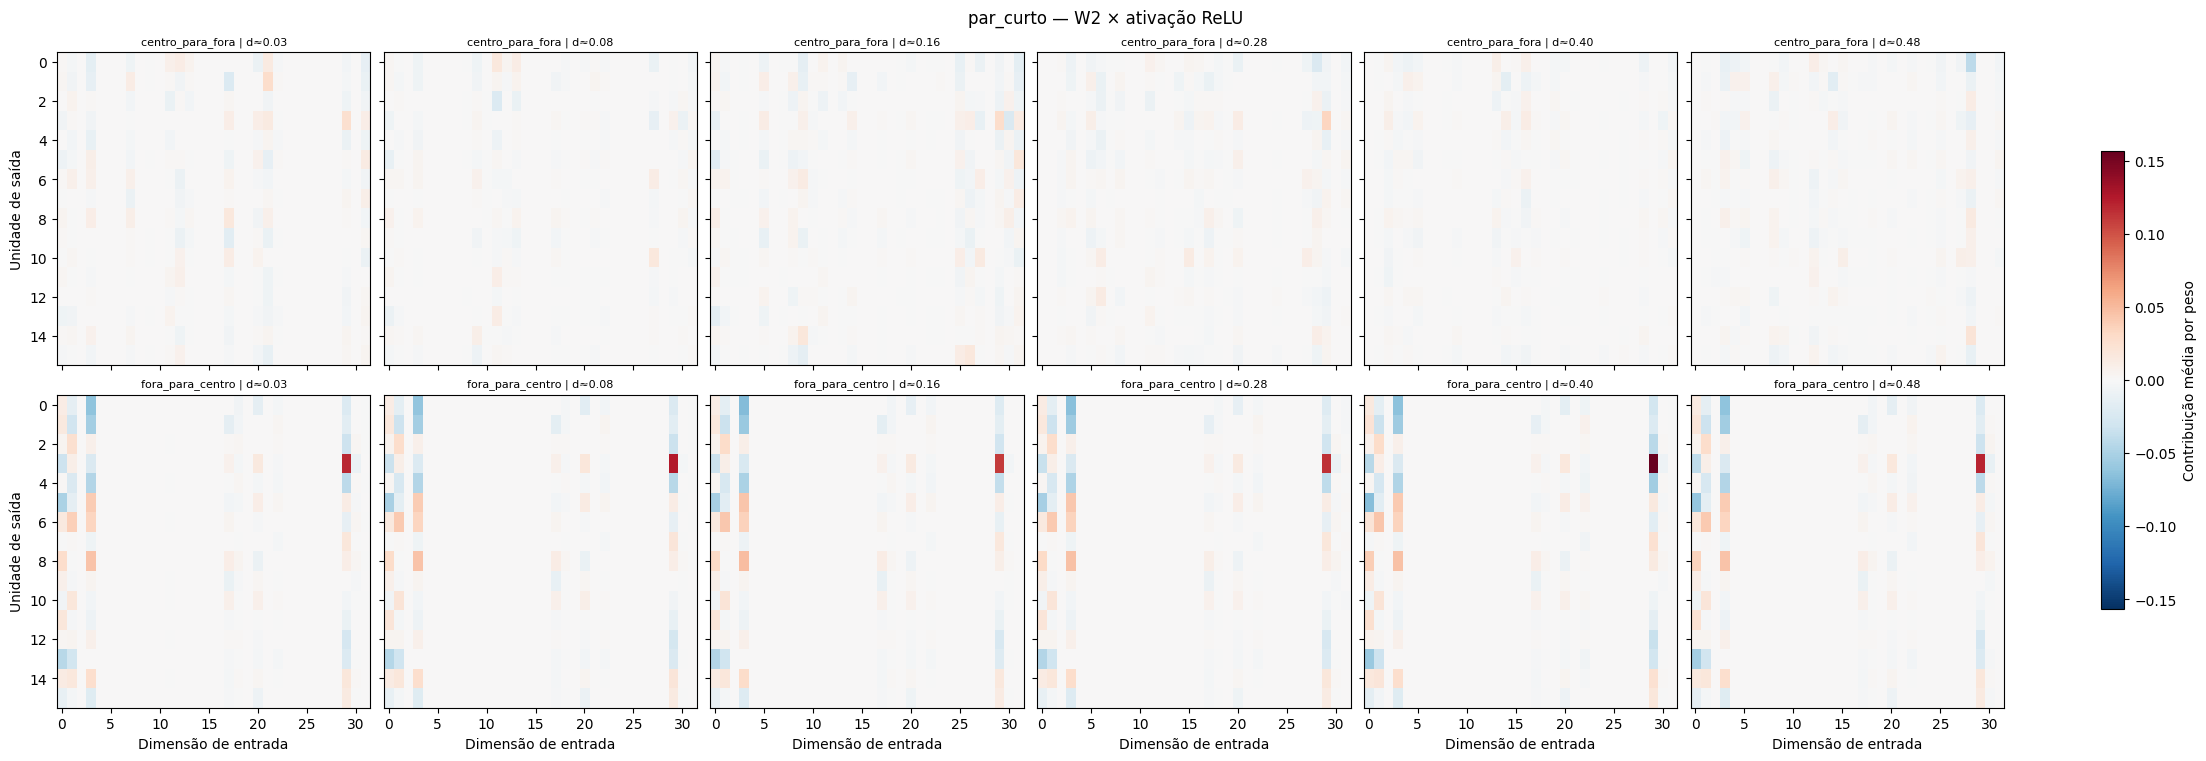

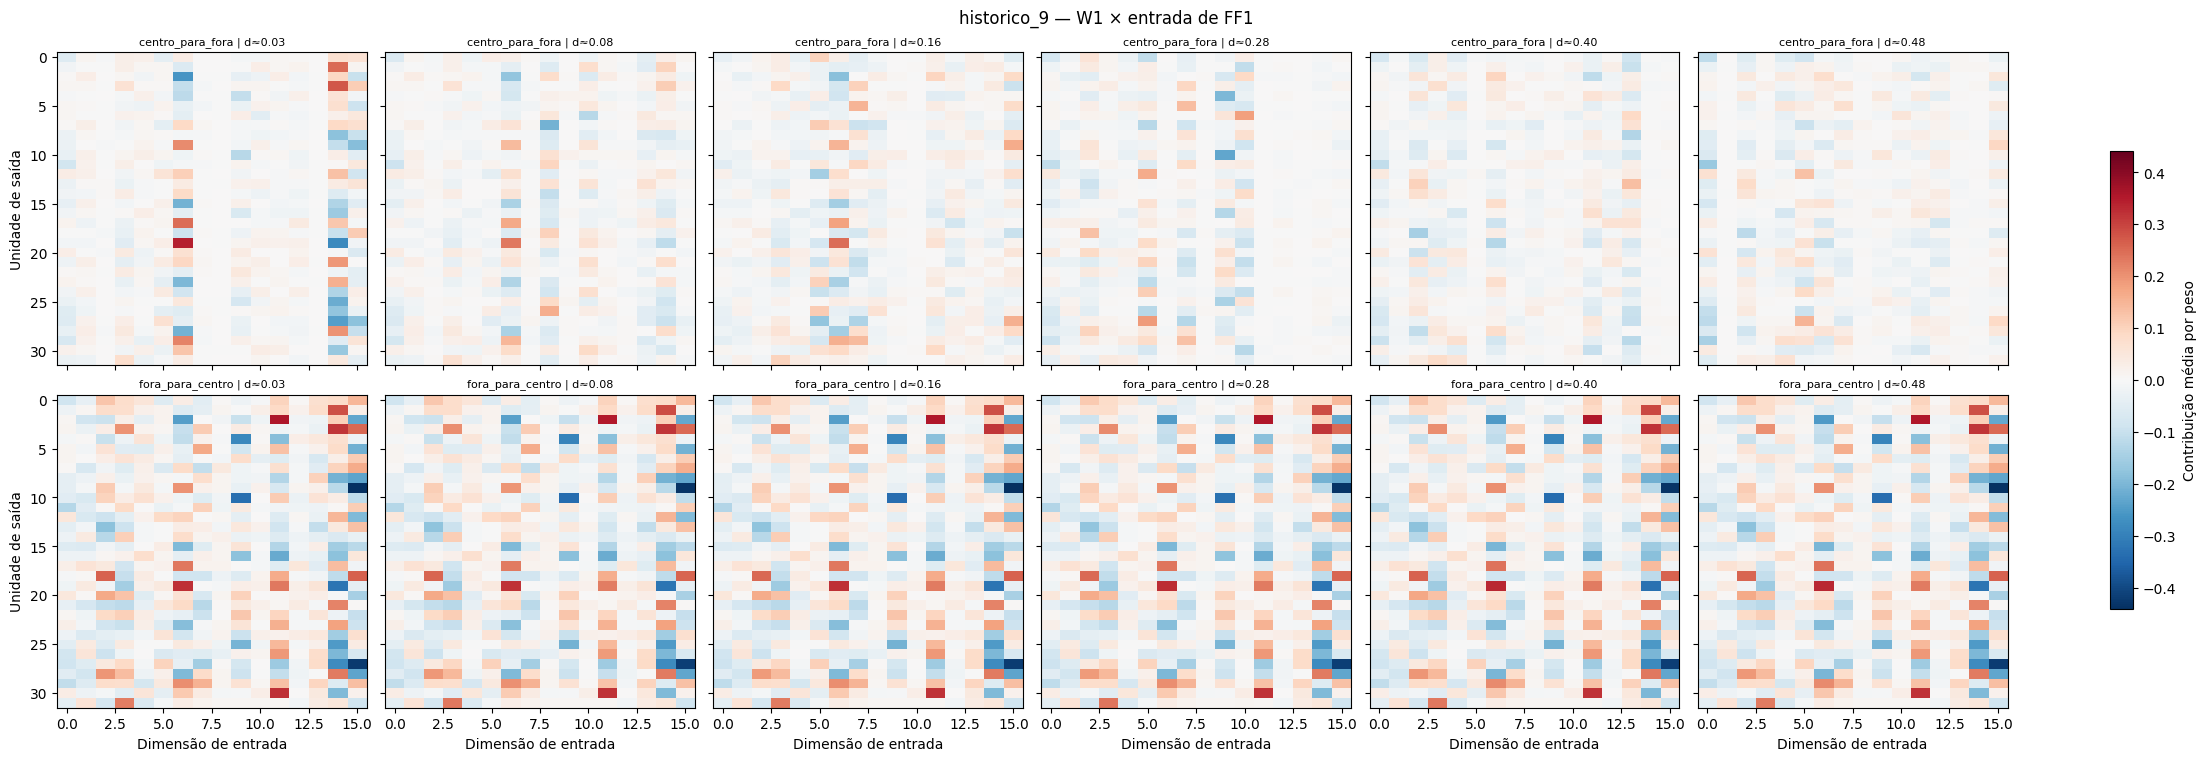

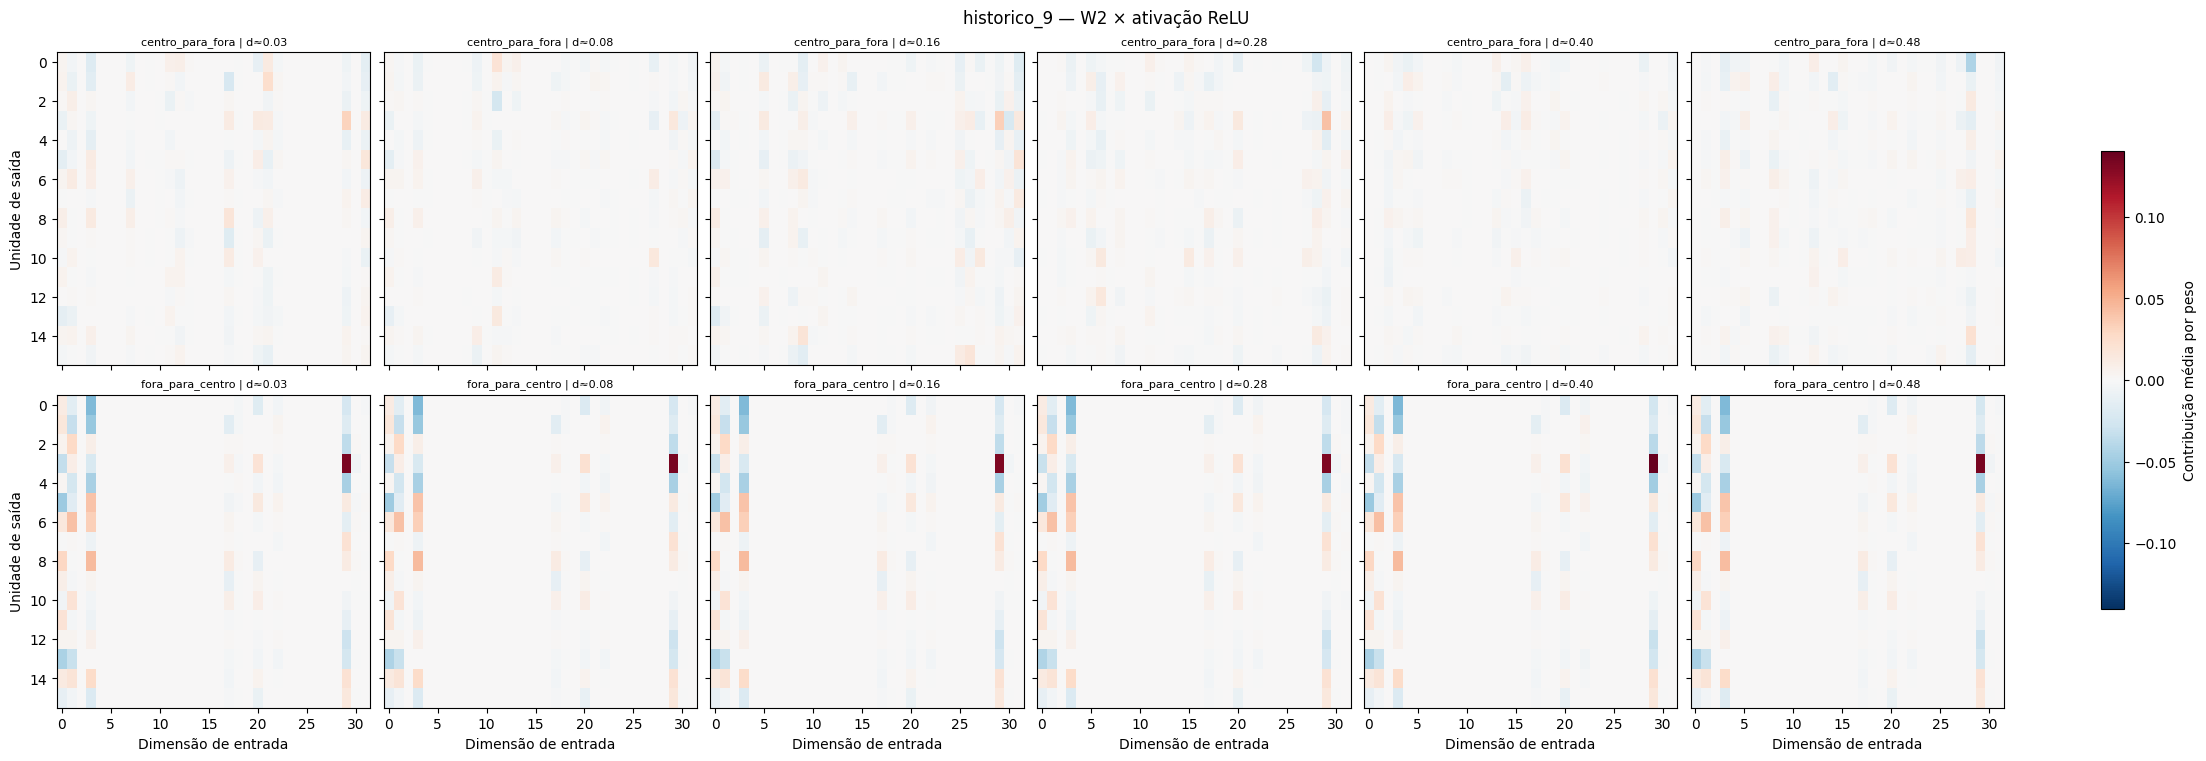

Mapas de pesos, ativações por dimensão e contribuições salvos em imgs/.


In [11]:
for mode in ['par_curto','historico_9']:
    part=trace[trace['mode']==mode]
    for stage,weight,input_stage,title in [
        ('FF1',W1,'attnorm','W1 × entrada de FF1'),
        ('FF2',W2,'relu','W2 × ativação ReLU')]:
        width=weight.shape[1]
        cols=[f'{input_stage}__d{i:02d}' for i in range(width)]
        grouped=part.groupby(['direction','ring'])[cols].mean()
        matrices={(direction,ring):weight*grouped.loc[(direction,ring)].to_numpy()[None,:]
                  for direction in order for ring in range(len(radii))}
        bound=max(float(np.max(np.abs(a))) for a in matrices.values())
        fig,axes=plt.subplots(2,len(radii),figsize=(22,7.5),sharex=True,sharey=True,constrained_layout=True)
        for row,direction in enumerate(order):
            for ring,radius in enumerate(radii):
                ax=axes[row,ring]
                im=ax.imshow(matrices[(direction,ring)],aspect='auto',cmap='RdBu_r',vmin=-bound,vmax=bound)
                ax.set_title(f'{direction} | d≈{radius:.2f}',fontsize=8)
                if row==1:ax.set_xlabel('Dimensão de entrada')
                if ring==0:ax.set_ylabel('Unidade de saída')
        fig.colorbar(im,ax=axes,shrink=.7,label='Contribuição média por peso')
        fig.suptitle(mode+' — '+title)
        fig.savefig(root/f'imgs/hardpos_ffw_contexto10_contrib_{stage}_{mode}.png',dpi=130,bbox_inches='tight')
        display(fig)
        plt.close(fig)
print('Mapas de pesos, ativações por dimensão e contribuições salvos em imgs/.')

### Cada posição da entrada

O resumo anterior observa o último PS de cada entrada. Agora registramos todos os passos: posições 7 e 8 do par isolado e posições 0 a 8 do contexto completo. A matriz treinada continua fixa; o mapa de cada passo mostra a contribuição de seus pesos depois de multiplicados pela ativação que entra em FF1 ou FF2 naquela posição. Cada distância e cada sentido têm seu próprio mapa. Salvamos também as 32 ativações ReLU e as 16 saídas de FF2 em cada passo para análises adicionais.

In [12]:
@torch.inference_mode()
def trace_all_steps(batch,pair_at_end=False):
    emb=model.embedding(batch)
    pos=emb+model.position_embedding.pe[7:9].unsqueeze(0) if pair_at_end else model.position_embedding(emb)
    attn,_=layer.self_attn(pos,pos,pos,attn_mask=model._causal_mask(batch.shape[1],batch.device),need_weights=False)
    norm1=layer.norm1(pos+layer.dropout1(attn))
    ff1=layer.linear1(norm1)
    relu=layer.activation(ff1)
    ff2=layer.linear2(layer.dropout(relu))
    encoder=layer.norm2(norm1+layer.dropout2(ff2))
    return {'attnorm':norm1.numpy(),'ff1':ff1.numpy(),'relu':relu.numpy(),
            'ff2':ff2.numpy(),'encoder':encoder.numpy()}

step_tables=[]
for mode,batches,metadata,pair_mode,step_positions in [
    ('par_curto',inputs,meta,True,[7,8]),
    ('historico_9',full_inputs,full_meta,False,list(range(9)))]:
    chunks={}
    for offset in range(0,len(batches),32):
        for stage,a in trace_all_steps(batches[offset:offset+32],pair_mode).items():
            chunks.setdefault(stage,[]).append(a)
    n_steps=len(step_positions)
    table=metadata[['ring','sector','direction','distance','peripheral_ps_id']].iloc[
        np.repeat(np.arange(len(metadata)),n_steps)].reset_index(drop=True)
    table['mode']=mode
    table['step']=np.tile(step_positions,len(metadata))
    stage_tables=[]
    for stage,parts in chunks.items():
        matrix=np.concatenate(parts).reshape(-1,parts[0].shape[-1])
        values={f'{stage}__d{j:02d}':matrix[:,j] for j in range(matrix.shape[1])}
        values[f'{stage}_mean_abs']=np.abs(matrix).mean(axis=1)
        stage_tables.append(pd.DataFrame(values))
    table=pd.concat([table,*stage_tables],axis=1)
    table['relu_fraction_active']=(np.concatenate(chunks['relu']).reshape(-1,32)>0).mean(axis=1)
    step_tables.append(table)
step_trace=pd.concat(step_tables,ignore_index=True)
step_trace.to_parquet(root/'legacy/analysis/HardPos_ffw_contexto10_todos_passos.parquet',index=False)
for mode,last_step in [('par_curto',8),('historico_9',8)]:
    left=step_trace.query('mode==@mode and step==@last_step')
    right=trace.query('mode==@mode')
    for stage in ['attnorm','ff1','relu','ff2','encoder']:
        np.testing.assert_allclose(left[f'{stage}_mean_abs'].to_numpy(),
                                   right[f'{stage}_mean_abs'].to_numpy(),rtol=1e-6,atol=1e-6)
print('Ativações por posição salvas:',len(step_trace),'linhas; última posição confere com o resumo anterior.')

Ativações por posição salvas: 8832 linhas; última posição confere com o resumo anterior.


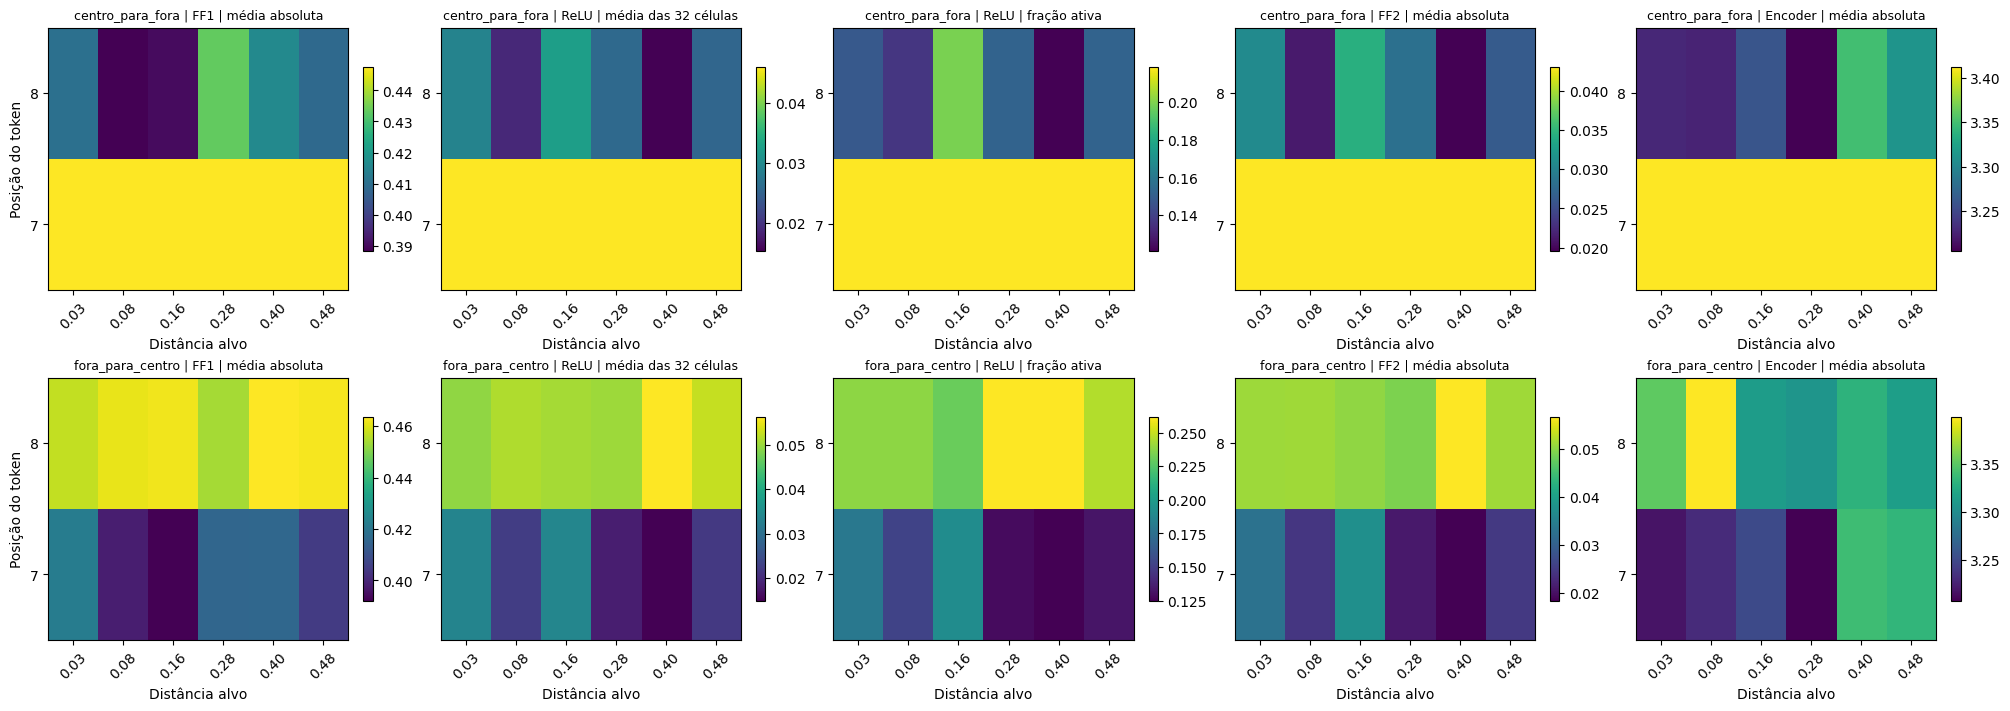

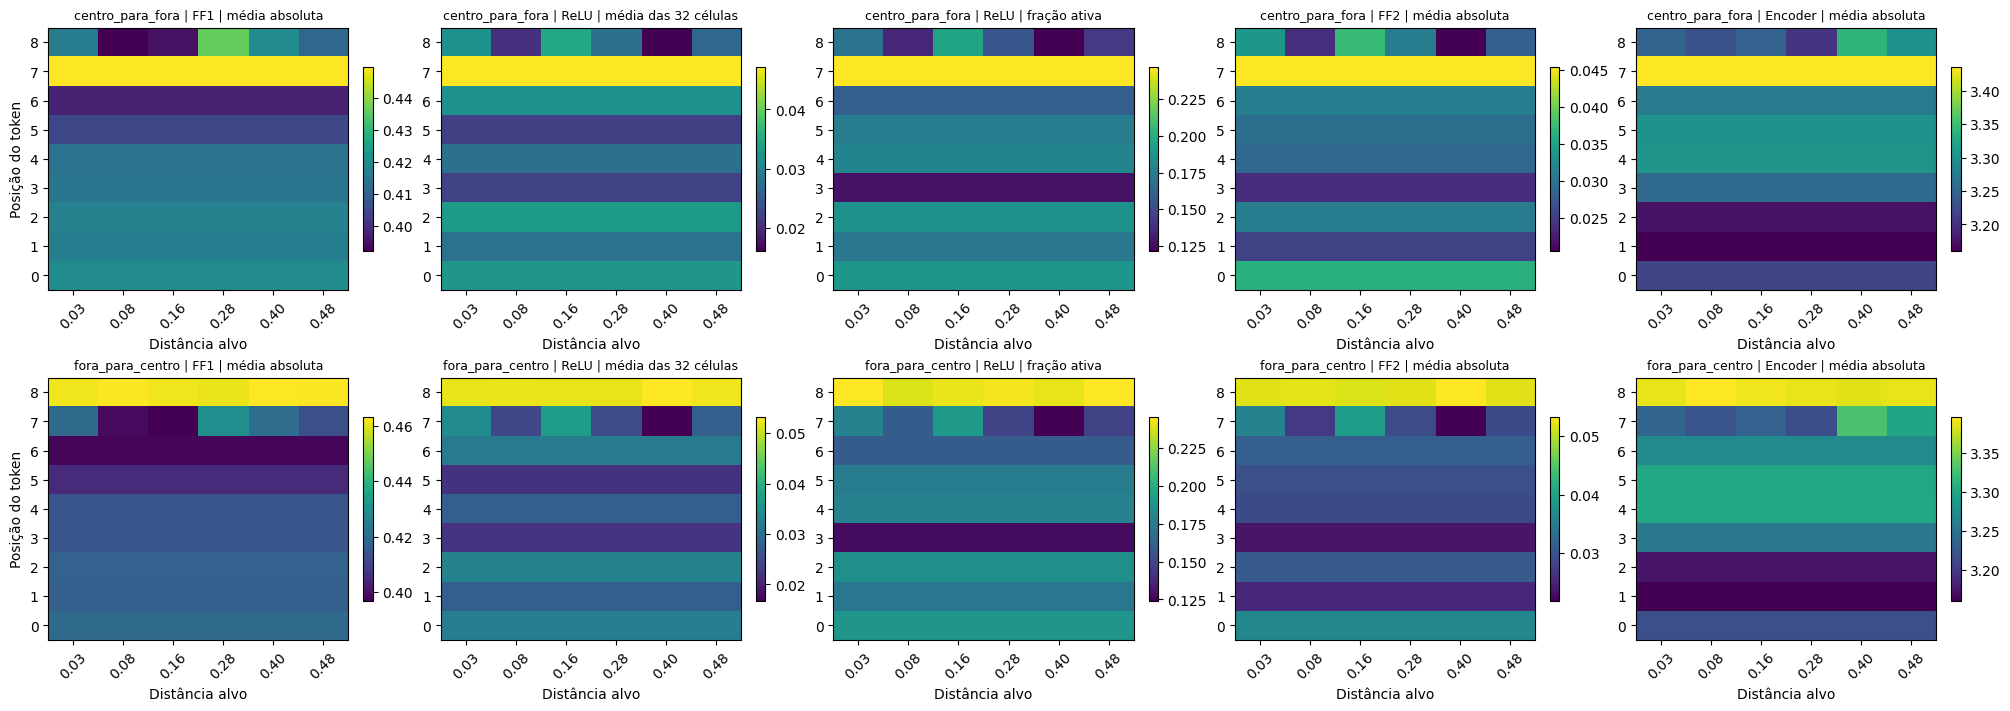

In [13]:
step_metrics=[('ff1_mean_abs','FF1 | média absoluta'),
              ('relu_mean_abs','ReLU | média das 32 células'),
              ('relu_fraction_active','ReLU | fração ativa'),
              ('ff2_mean_abs','FF2 | média absoluta'),
              ('encoder_mean_abs','Encoder | média absoluta')]
for mode in ['par_curto','historico_9']:
    part=step_trace[step_trace['mode']==mode]
    grouped=part.groupby(['direction','ring','step'])[[x[0] for x in step_metrics]].mean()
    steps=sorted(part.step.unique())
    fig,axes=plt.subplots(2,len(step_metrics),figsize=(20,7),constrained_layout=True)
    for row,direction in enumerate(order):
        for col,(metric,title) in enumerate(step_metrics):
            values=np.array([[grouped.loc[(direction,ring,step),metric]
                              for ring in range(len(radii))] for step in steps])
            im=axes[row,col].imshow(values,aspect='auto',origin='lower',cmap='viridis')
            axes[row,col].set_title(direction+' | '+title,fontsize=9)
            axes[row,col].set_xticks(range(len(radii)),[f'{r:.2f}' for r in radii],rotation=45)
            axes[row,col].set_yticks(range(len(steps)),steps)
            axes[row,col].set_xlabel('Distância alvo')
            if col==0:axes[row,col].set_ylabel('Posição do token')
            fig.colorbar(im,ax=axes[row,col],shrink=.7)
    fig.savefig(root/f'imgs/hardpos_ffw_contexto10_media_por_passo_{mode}.png',dpi=140,bbox_inches='tight')
    display(fig)
    plt.close(fig)

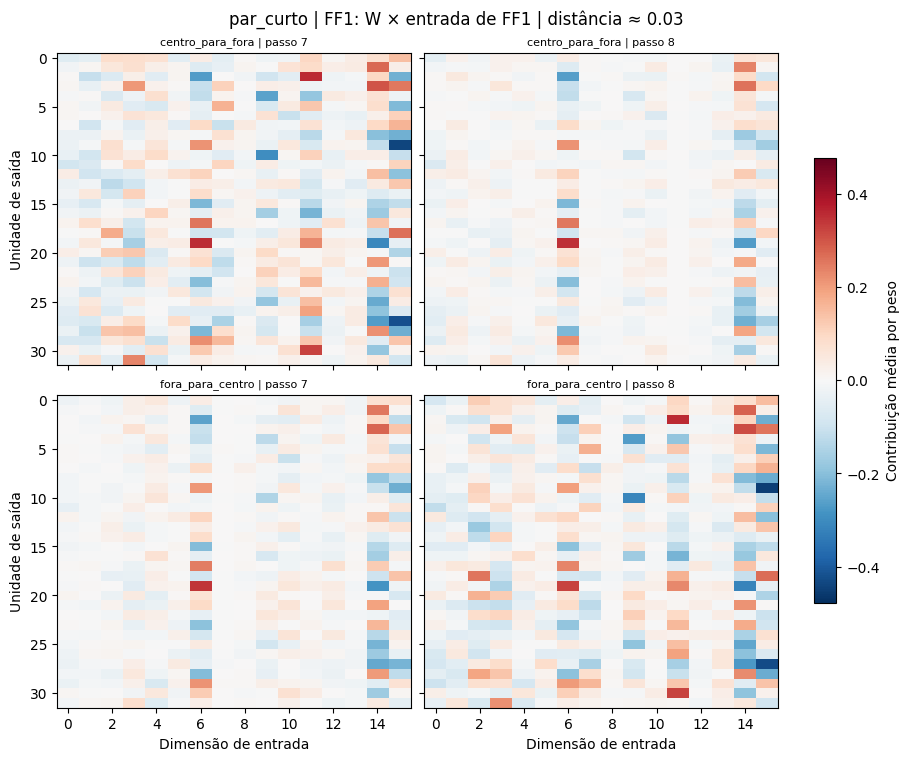

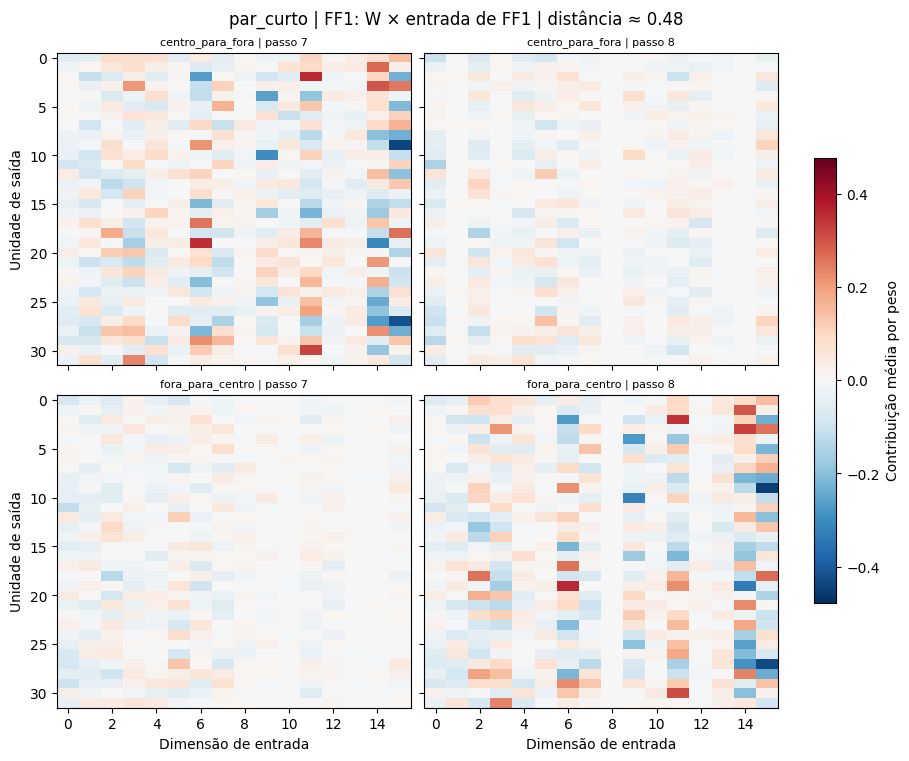

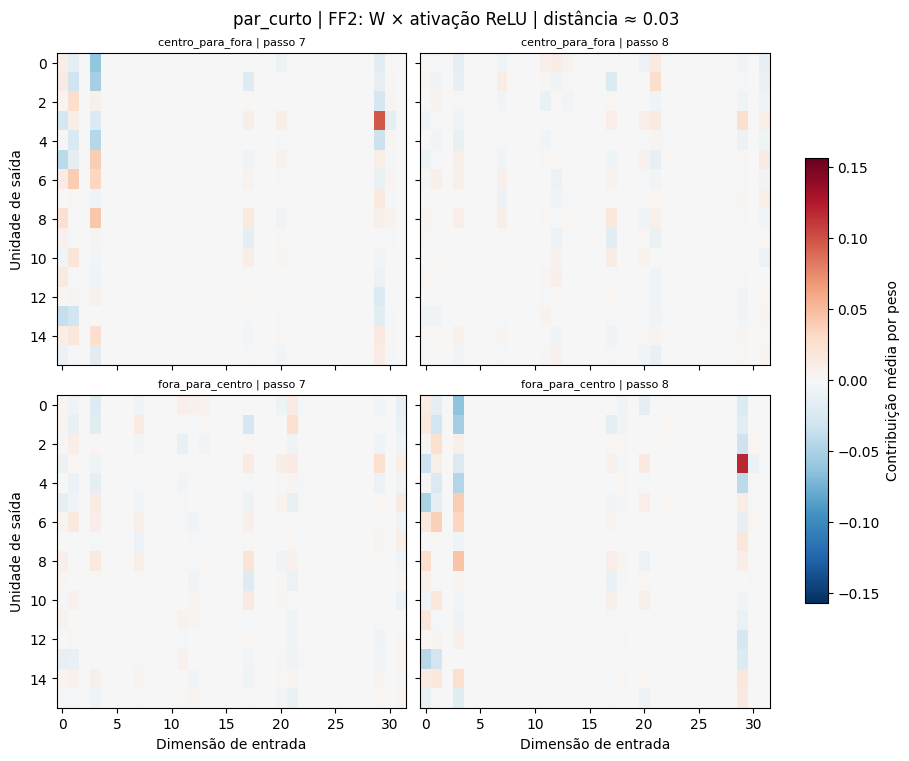

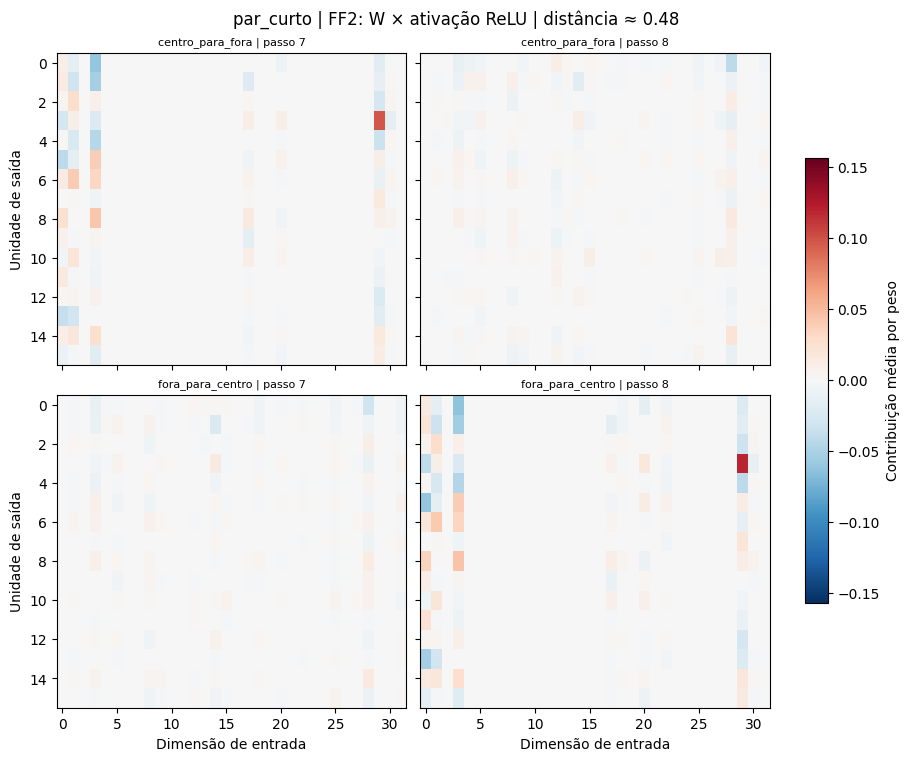

**par_curto:** 12 mapas por passo salvos em imgs/; cada arquivo mostra os dois sentidos em uma distância.

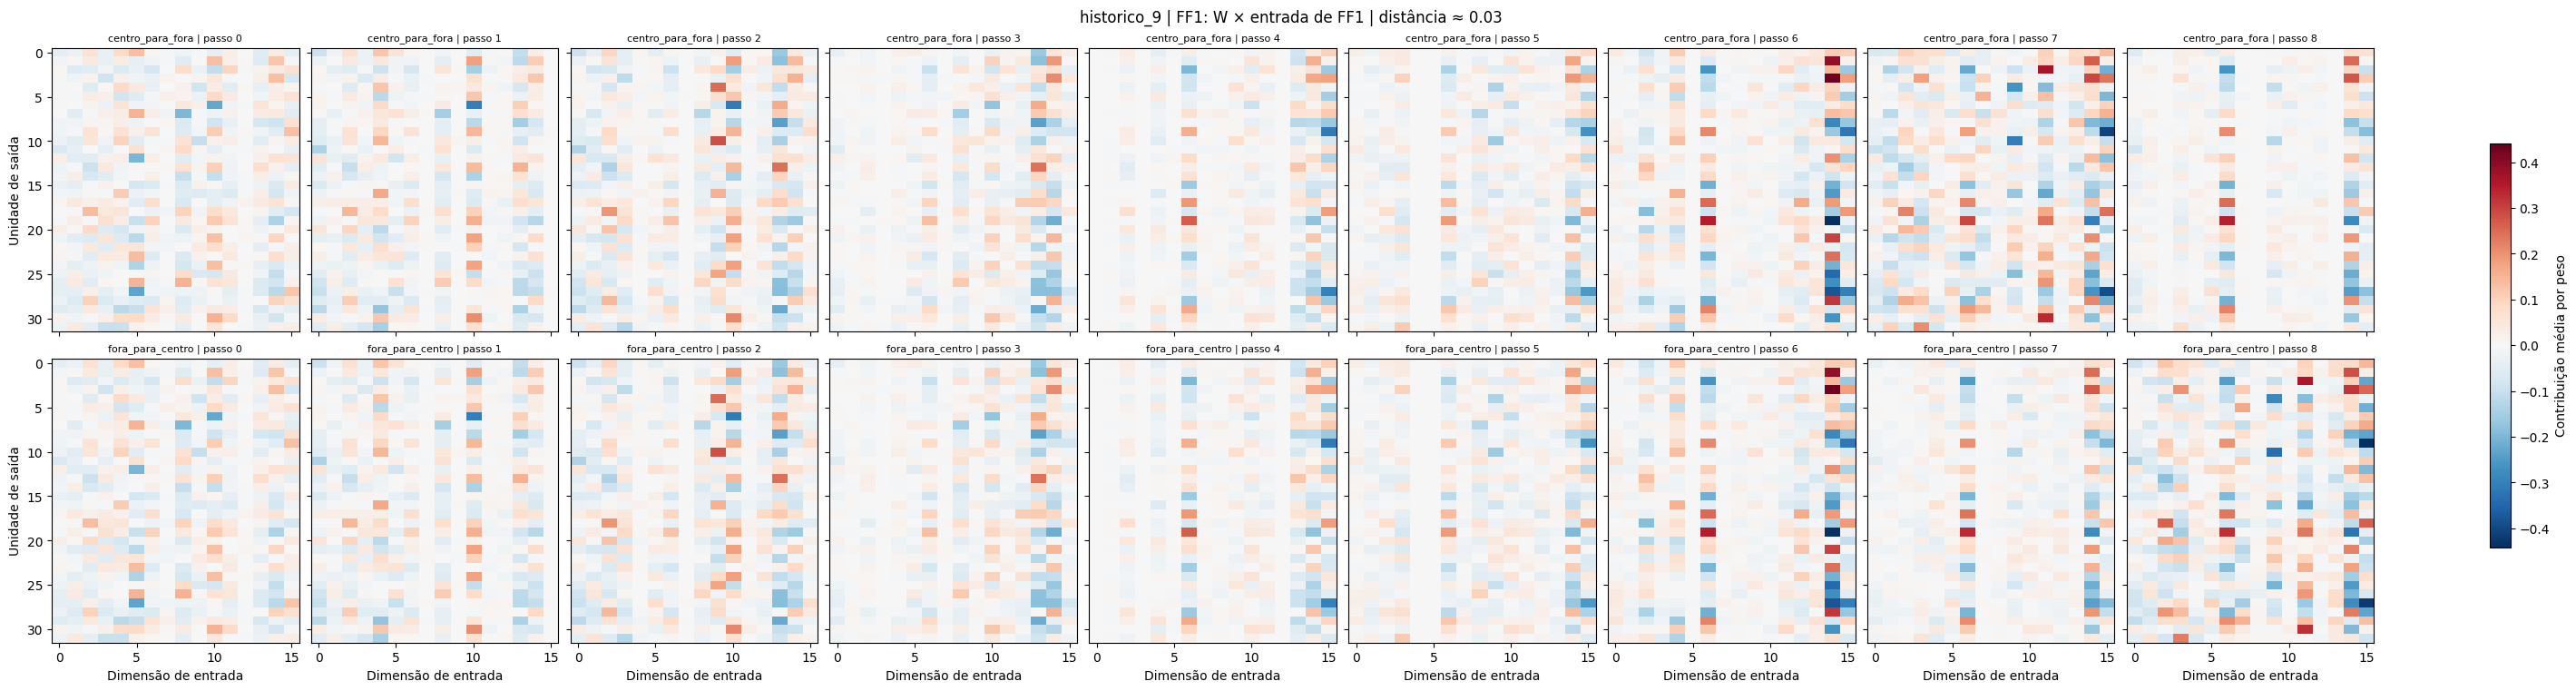

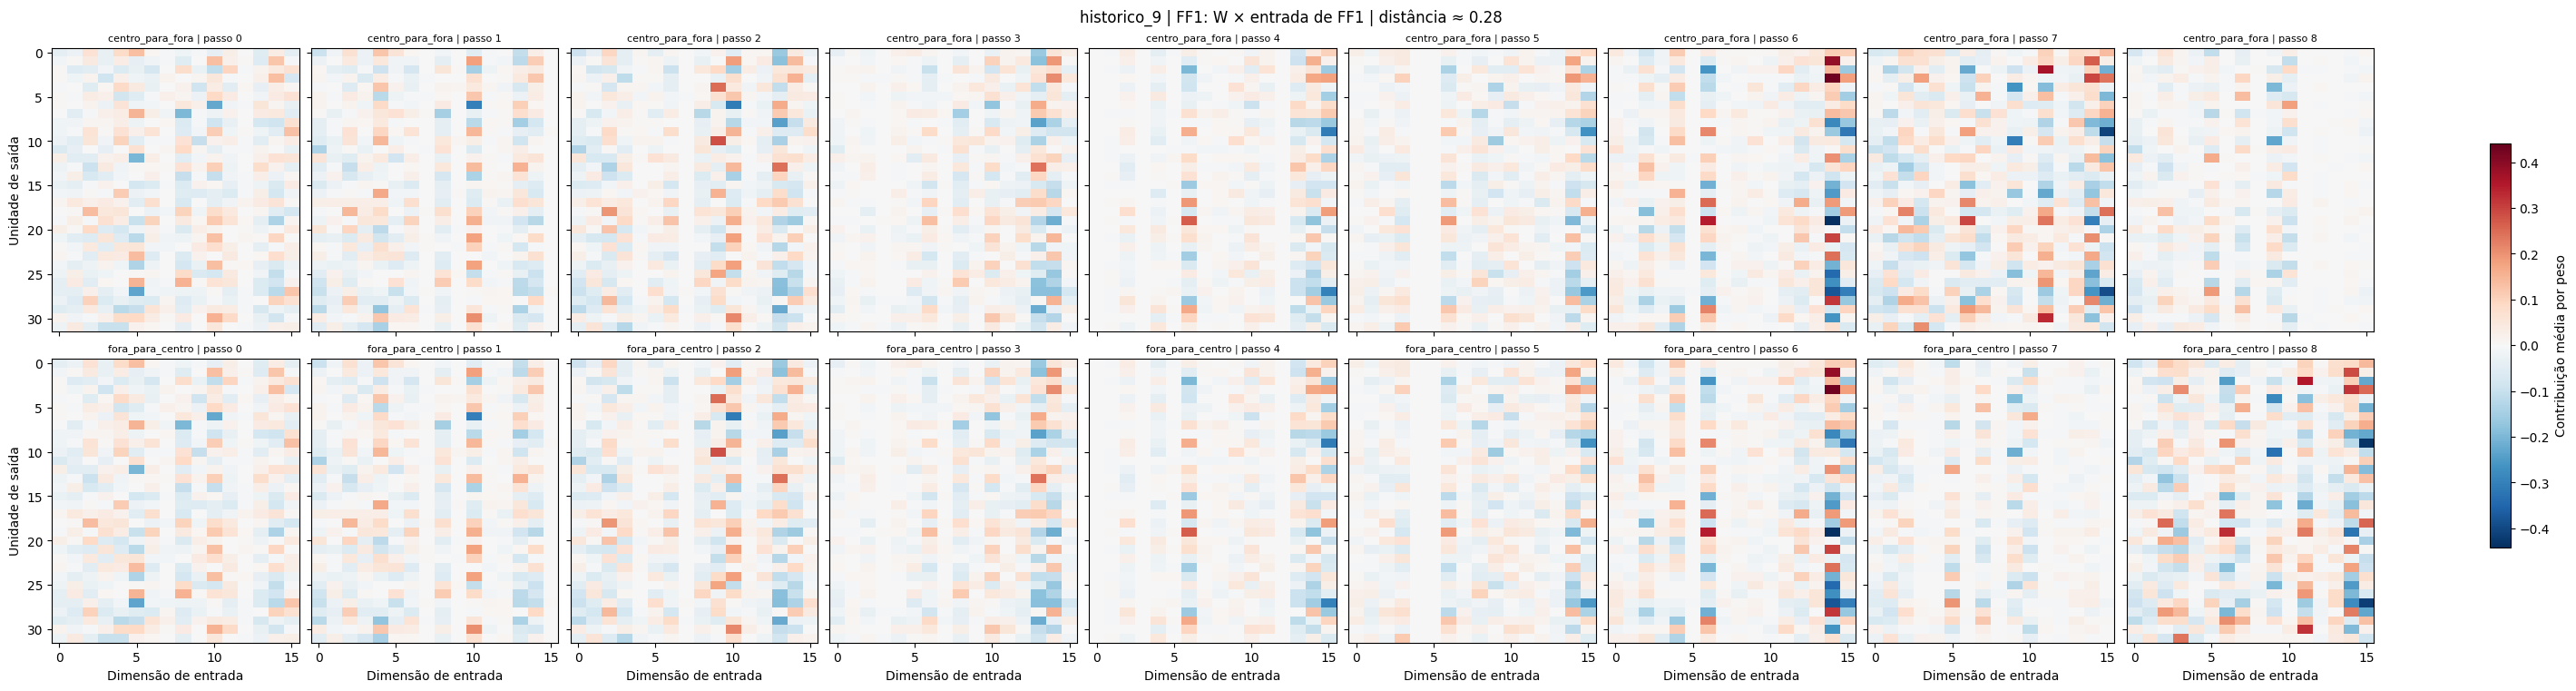

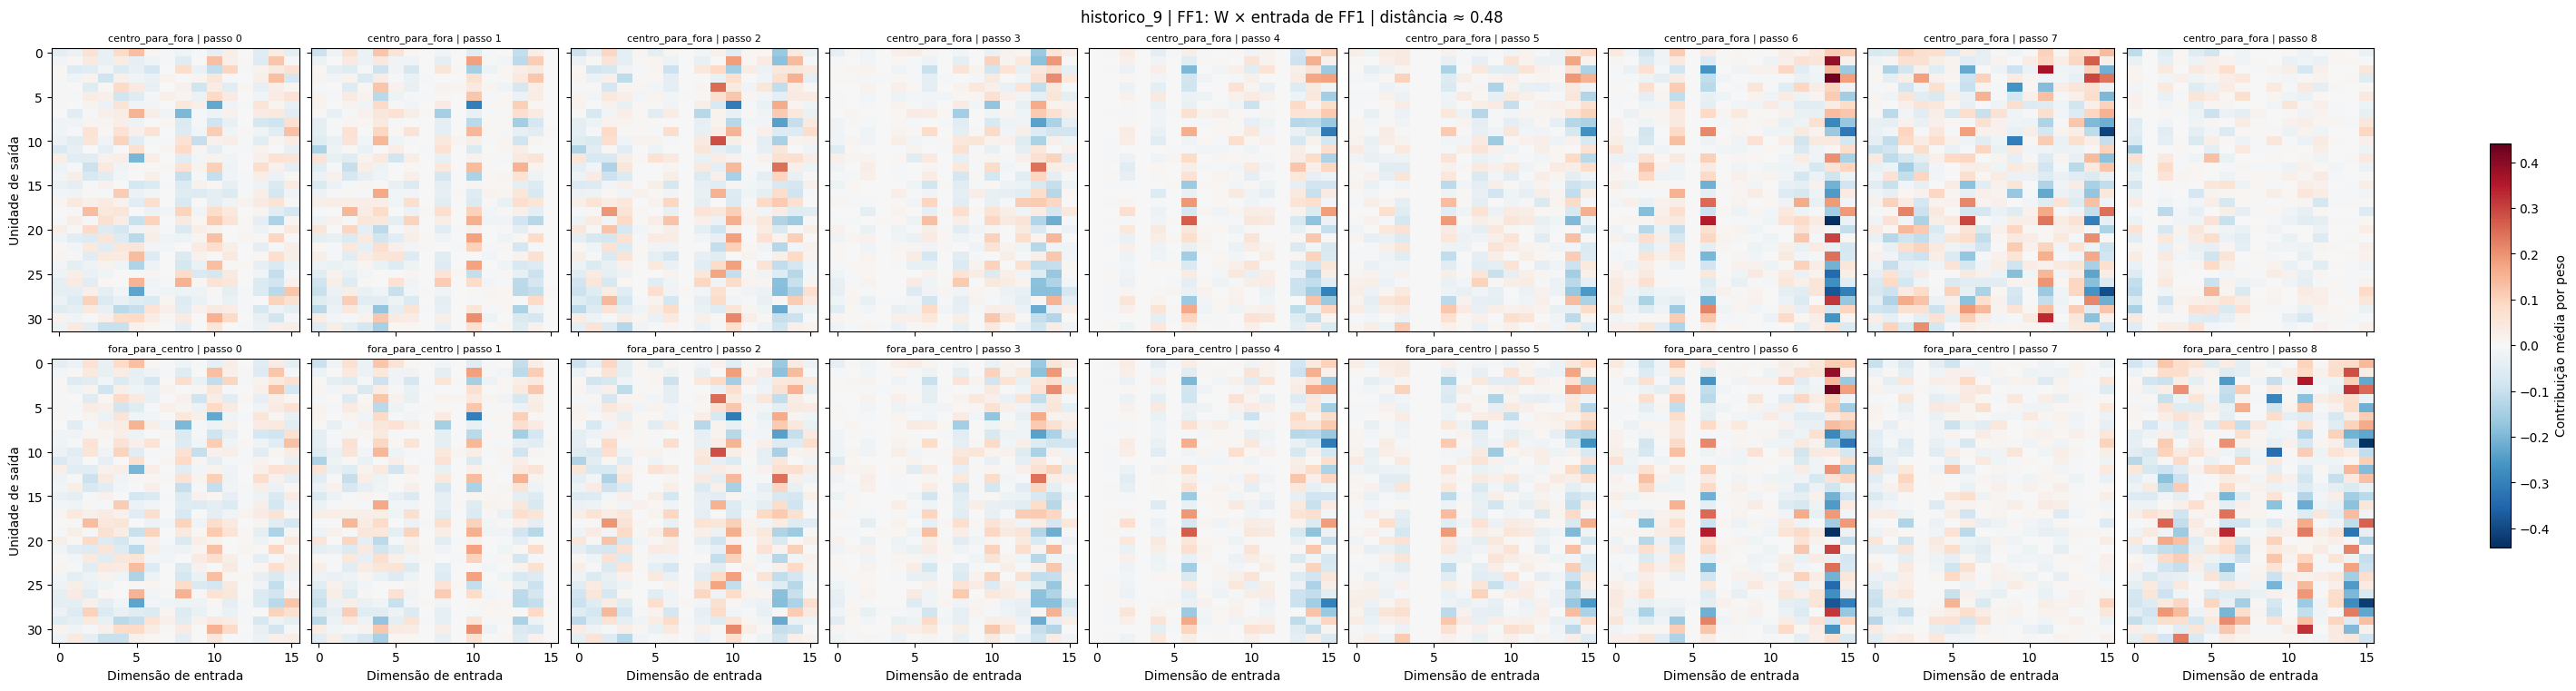

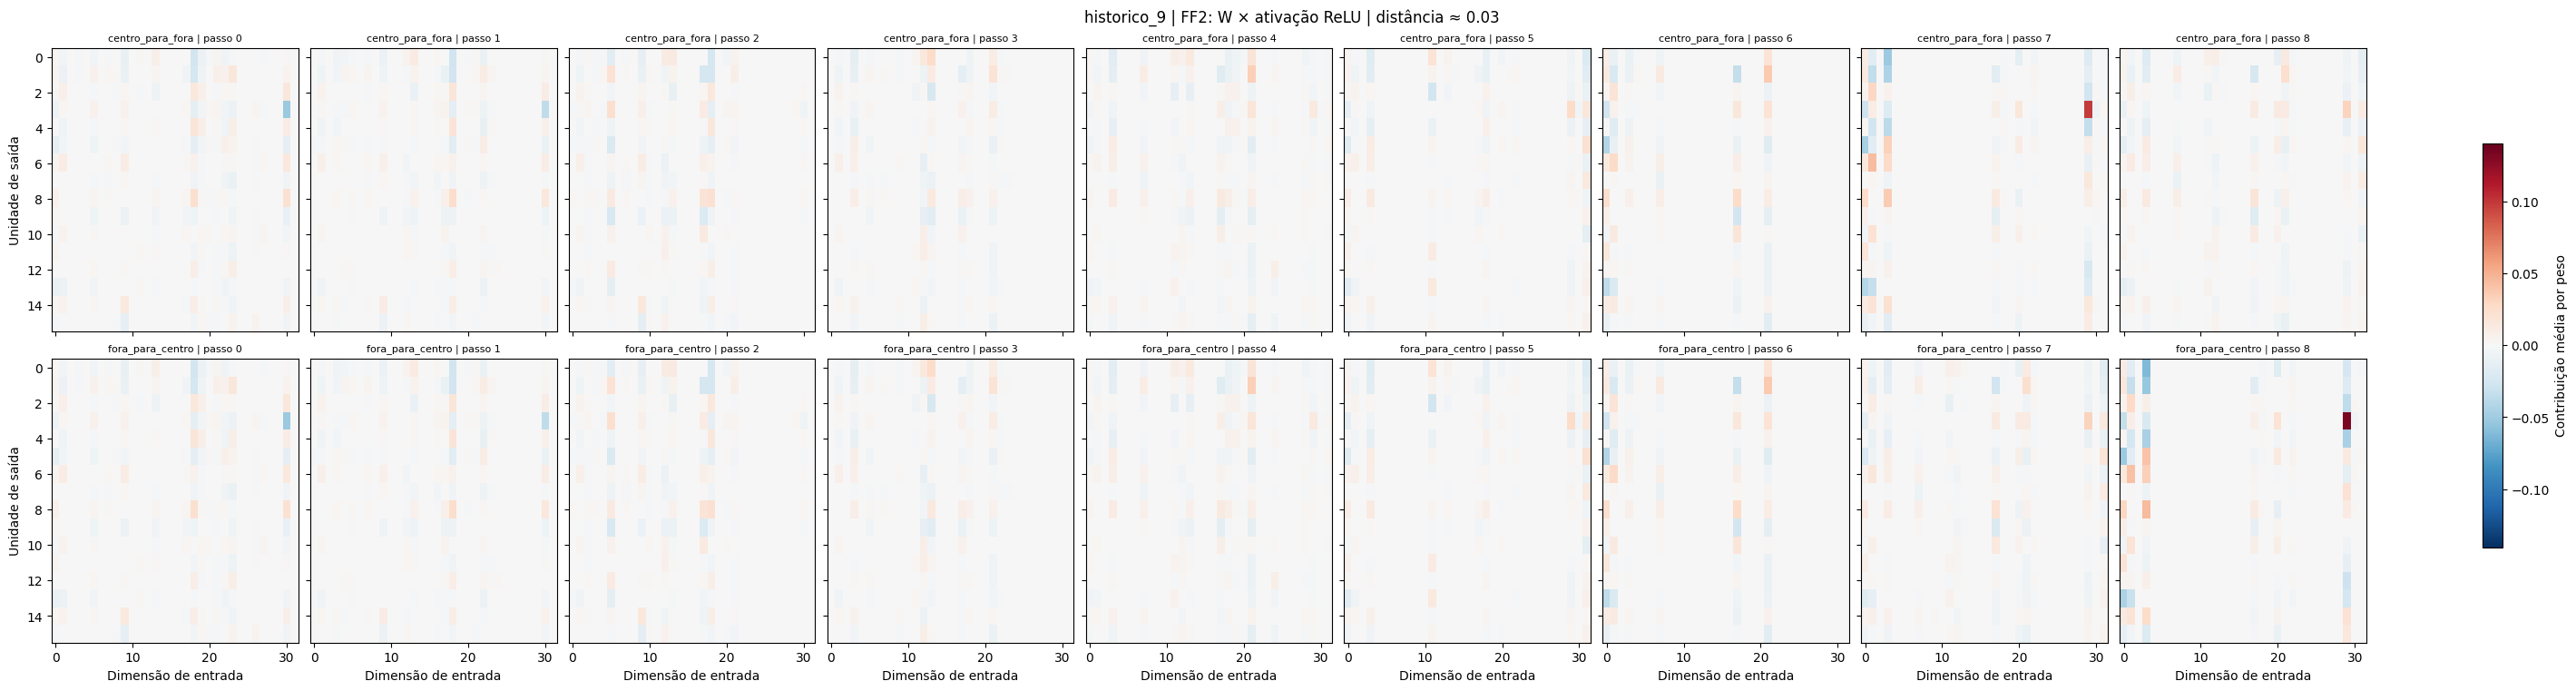

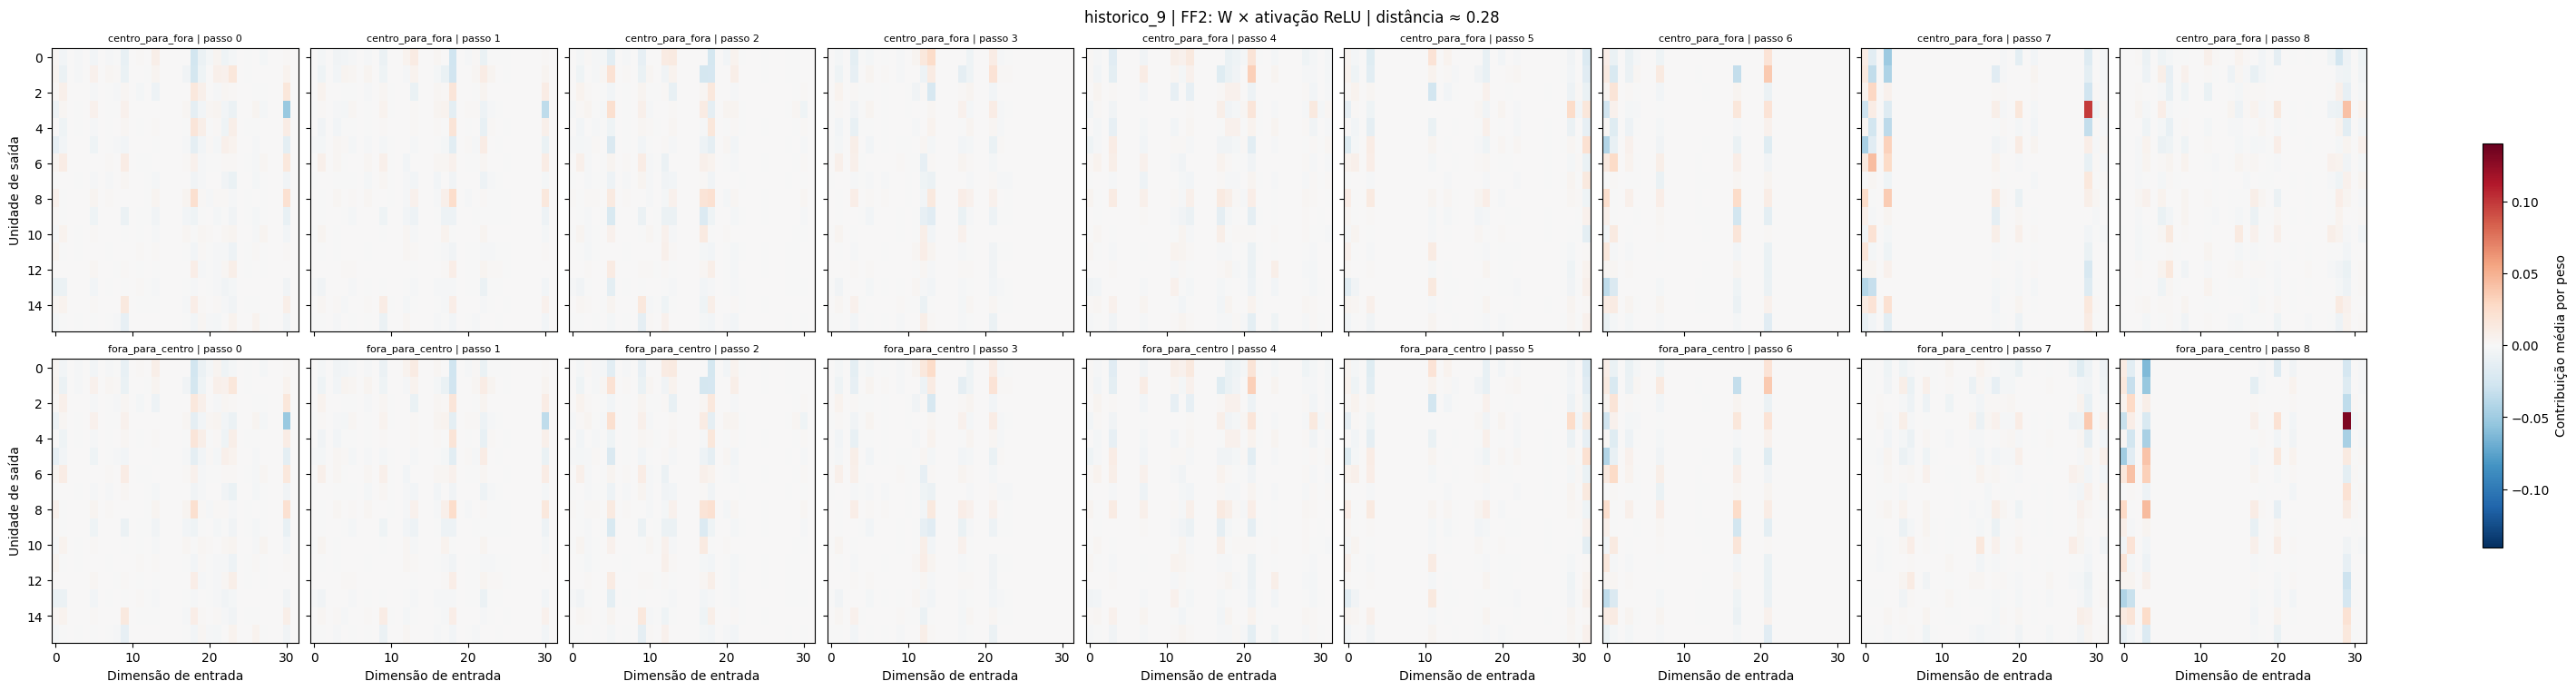

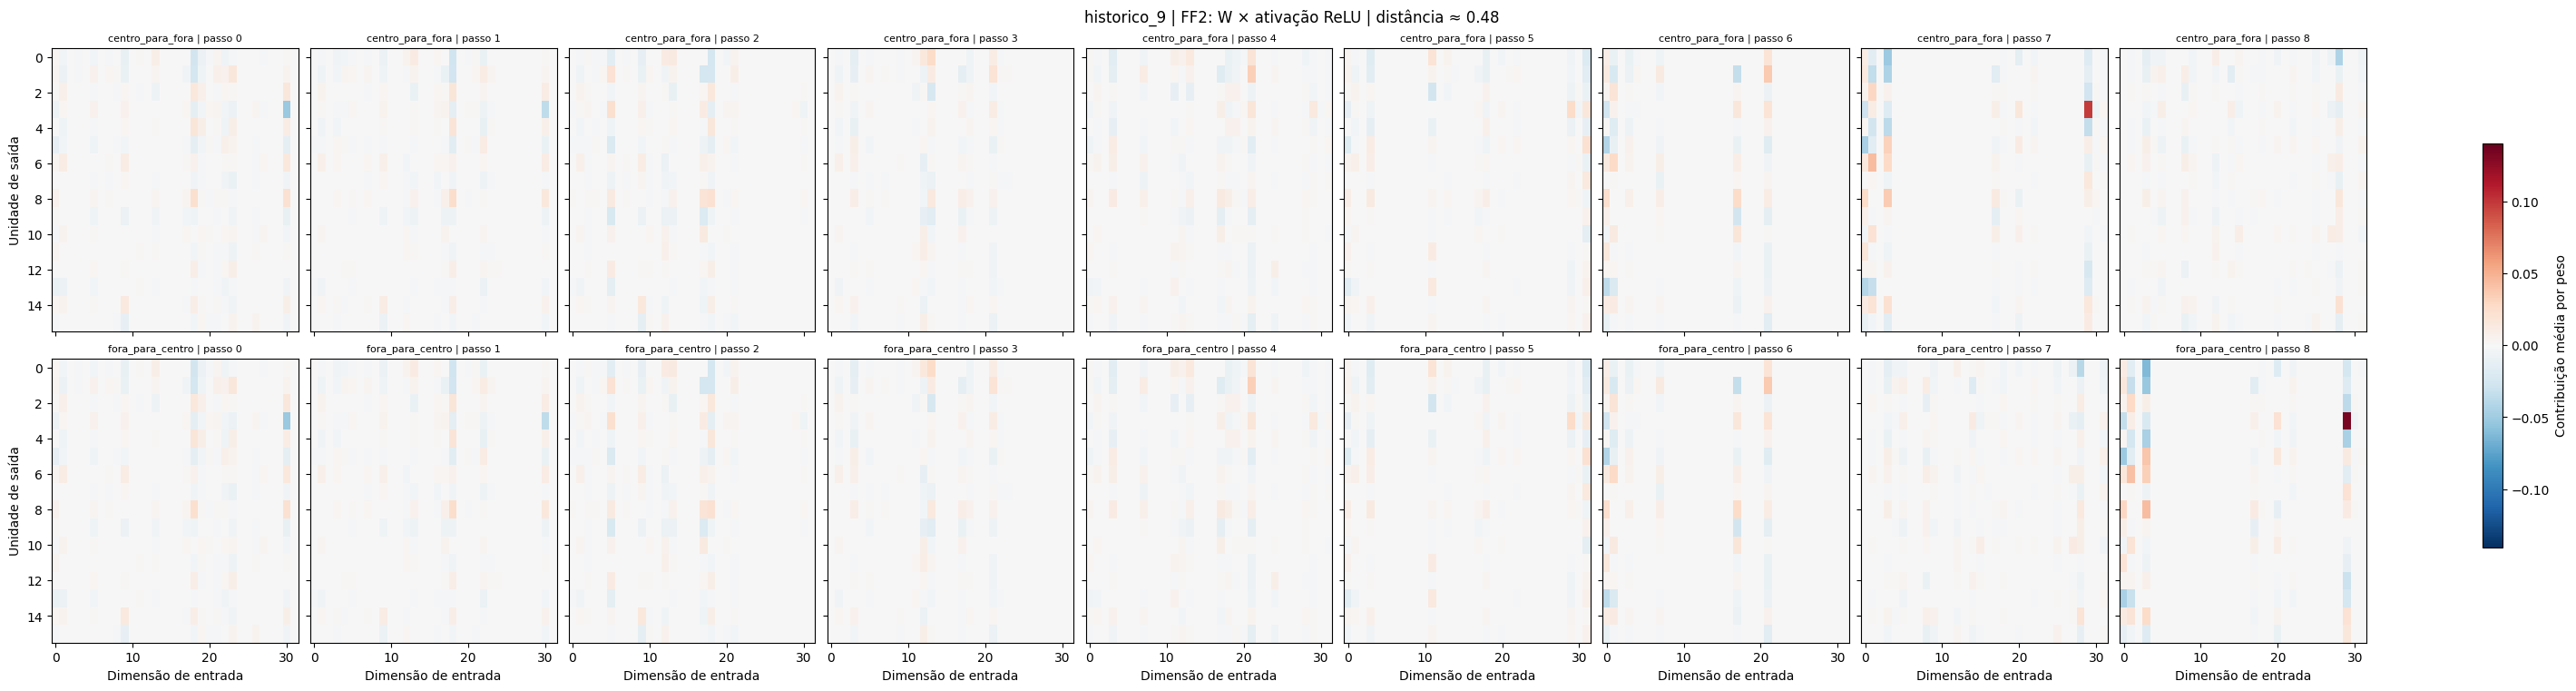

**historico_9:** 12 mapas por passo salvos em imgs/; cada arquivo mostra os dois sentidos em uma distância.

Total: 24 figuras por passo, cobrindo W1 e W2 em 6 distâncias e 2 modos.


In [14]:
from IPython.display import Markdown
weight_stages=[('FF1',W1,'attnorm','entrada de FF1'),
               ('FF2',W2,'relu','ativação ReLU')]
for mode in ['par_curto','historico_9']:
    part=step_trace[step_trace['mode']==mode]
    steps=sorted(part.step.unique())
    for stage,weight,input_stage,input_label in weight_stages:
        cols=[f'{input_stage}__d{i:02d}' for i in range(weight.shape[1])]
        grouped=part.groupby(['direction','ring','step'])[cols].mean()
        matrices={(direction,ring,step):weight*grouped.loc[(direction,ring,step)].to_numpy()[None,:]
                  for direction in order for ring in range(len(radii)) for step in steps}
        bound=max(float(np.max(np.abs(m))) for m in matrices.values())
        for ring,radius in enumerate(radii):
            fig,axes=plt.subplots(2,len(steps),figsize=(max(9,3.15*len(steps)),7.5),
                                  sharex=True,sharey=True,constrained_layout=True)
            for row,direction in enumerate(order):
                for col,step in enumerate(steps):
                    ax=axes[row,col]
                    im=ax.imshow(matrices[(direction,ring,step)],aspect='auto',
                                 cmap='RdBu_r',vmin=-bound,vmax=bound)
                    ax.set_title(f'{direction} | passo {step}',fontsize=8)
                    if row==1:ax.set_xlabel('Dimensão de entrada')
                    if col==0:ax.set_ylabel('Unidade de saída')
            fig.colorbar(im,ax=axes,shrink=.68,label='Contribuição média por peso')
            fig.suptitle(f'{mode} | {stage}: W × {input_label} | distância ≈ {radius:.2f}')
            path=root/f'imgs/hardpos_ffw_contexto10_passo_{stage}_{mode}_distancia_{ring:02d}.png'
            fig.savefig(path,dpi=130,bbox_inches='tight')
            if ring in ([0,5] if mode=='par_curto' else [0,3,5]):display(fig)
            plt.close(fig)
    display(Markdown(f'**{mode}:** 12 mapas por passo salvos em imgs/; cada arquivo mostra os dois sentidos em uma distância.'))
print('Total: 24 figuras por passo, cobrindo W1 e W2 em 6 distâncias e 2 modos.')

### Ativação individual em todos os passos

Para cada distância, mostramos a média de cada uma das 32 unidades de FF1 antes e depois da ReLU, e de cada uma das 16 saídas de FF2. As colunas são posições do input; as linhas são dimensões. Cada figura compara os dois sentidos, e a escala de cores de cada estágio é compartilhada entre as seis distâncias do mesmo modo.

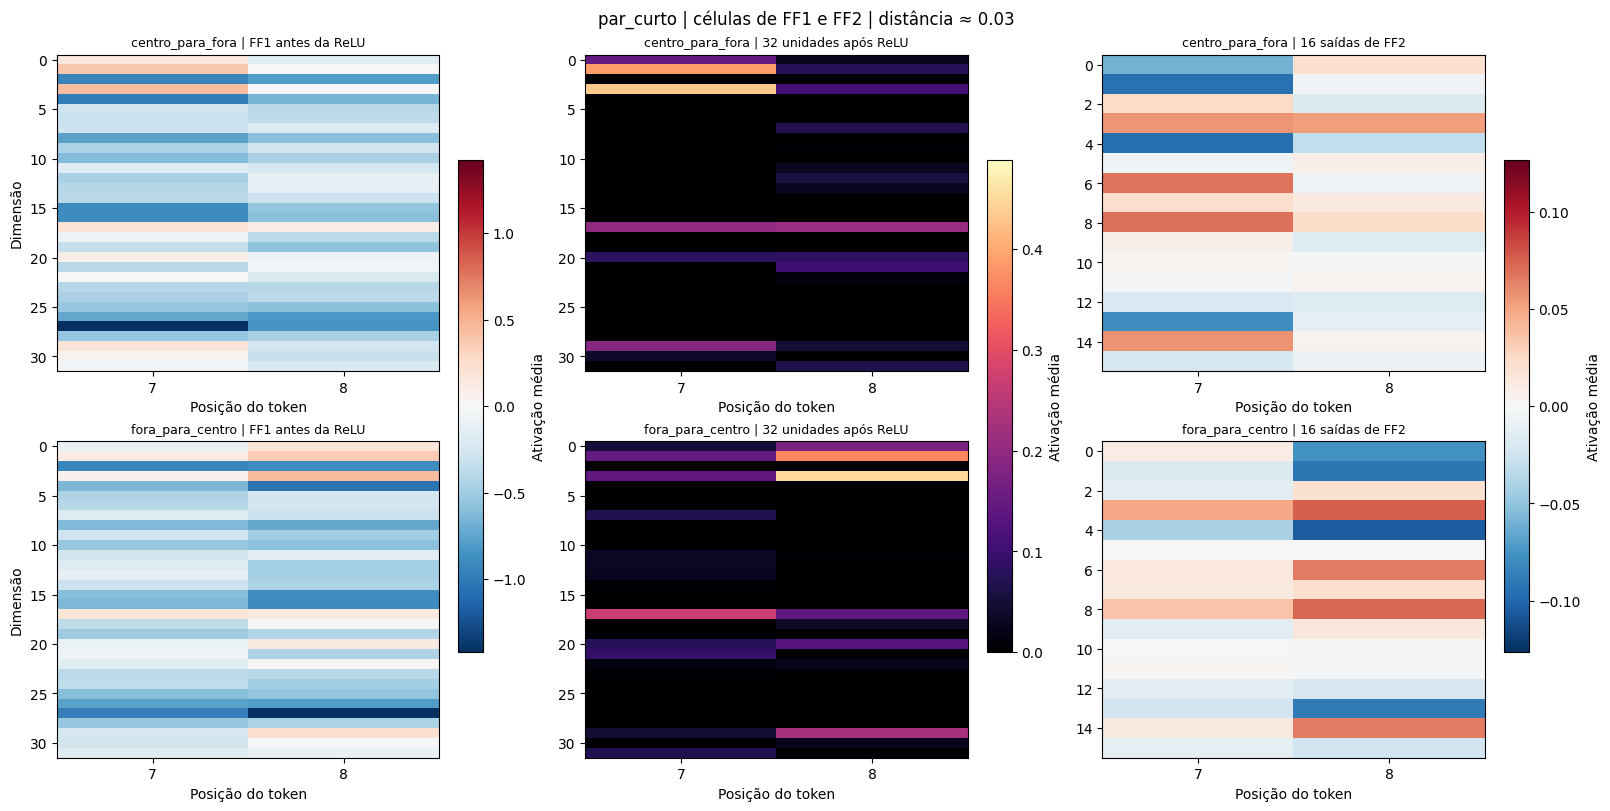

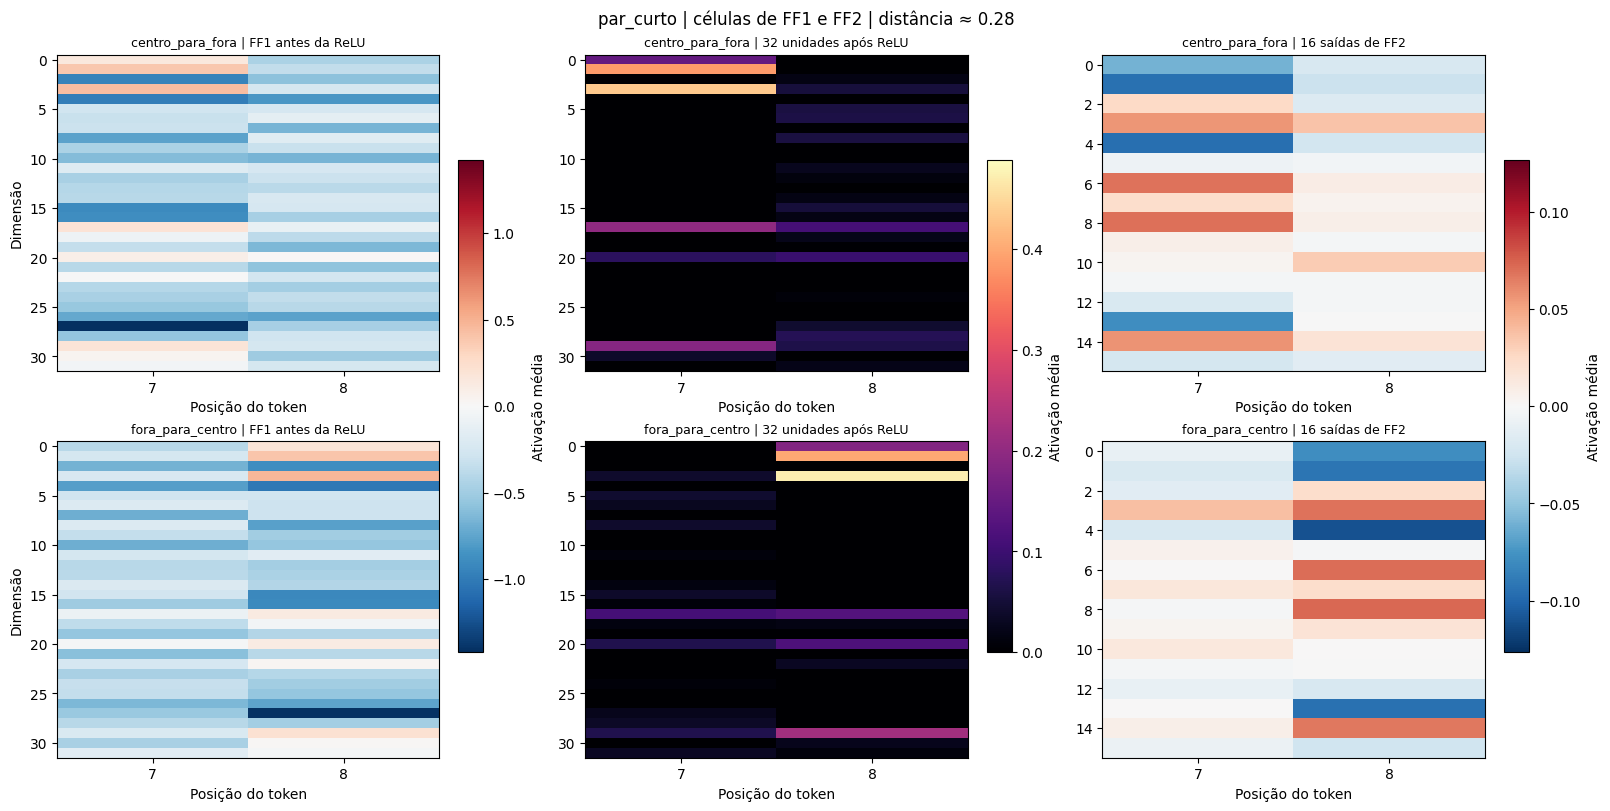

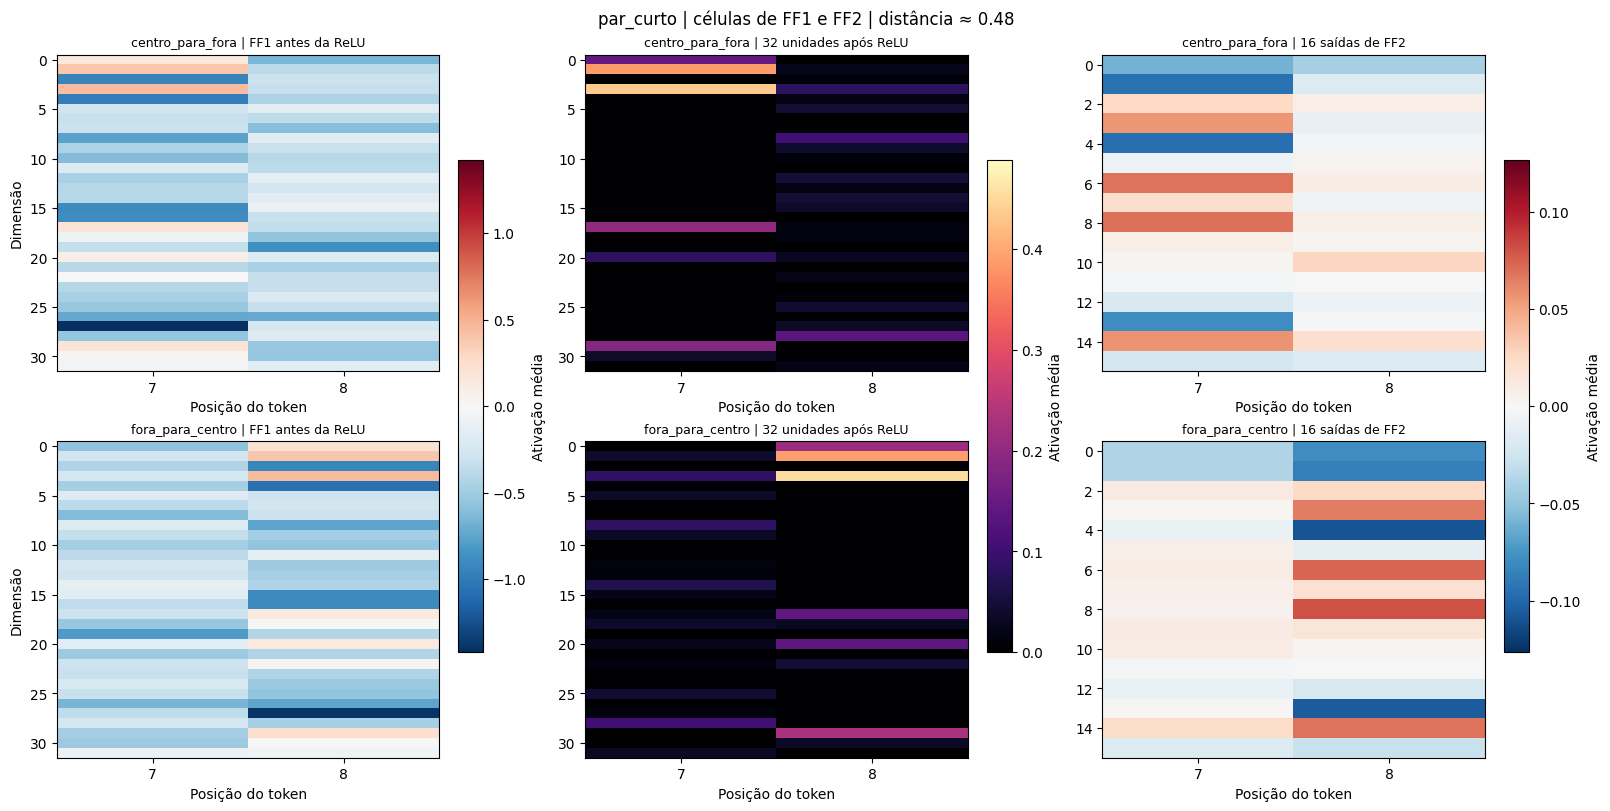

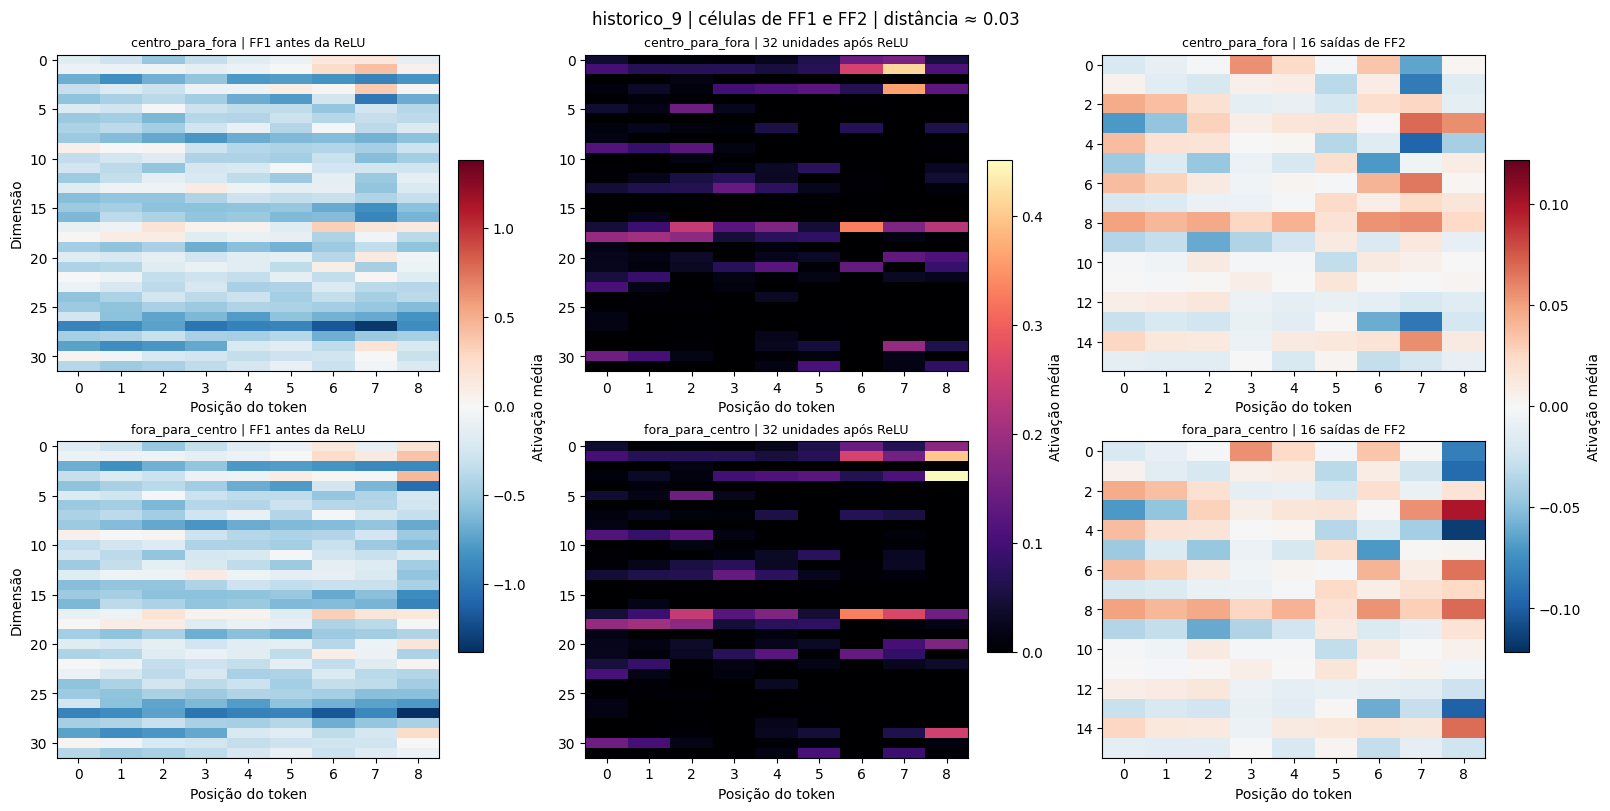

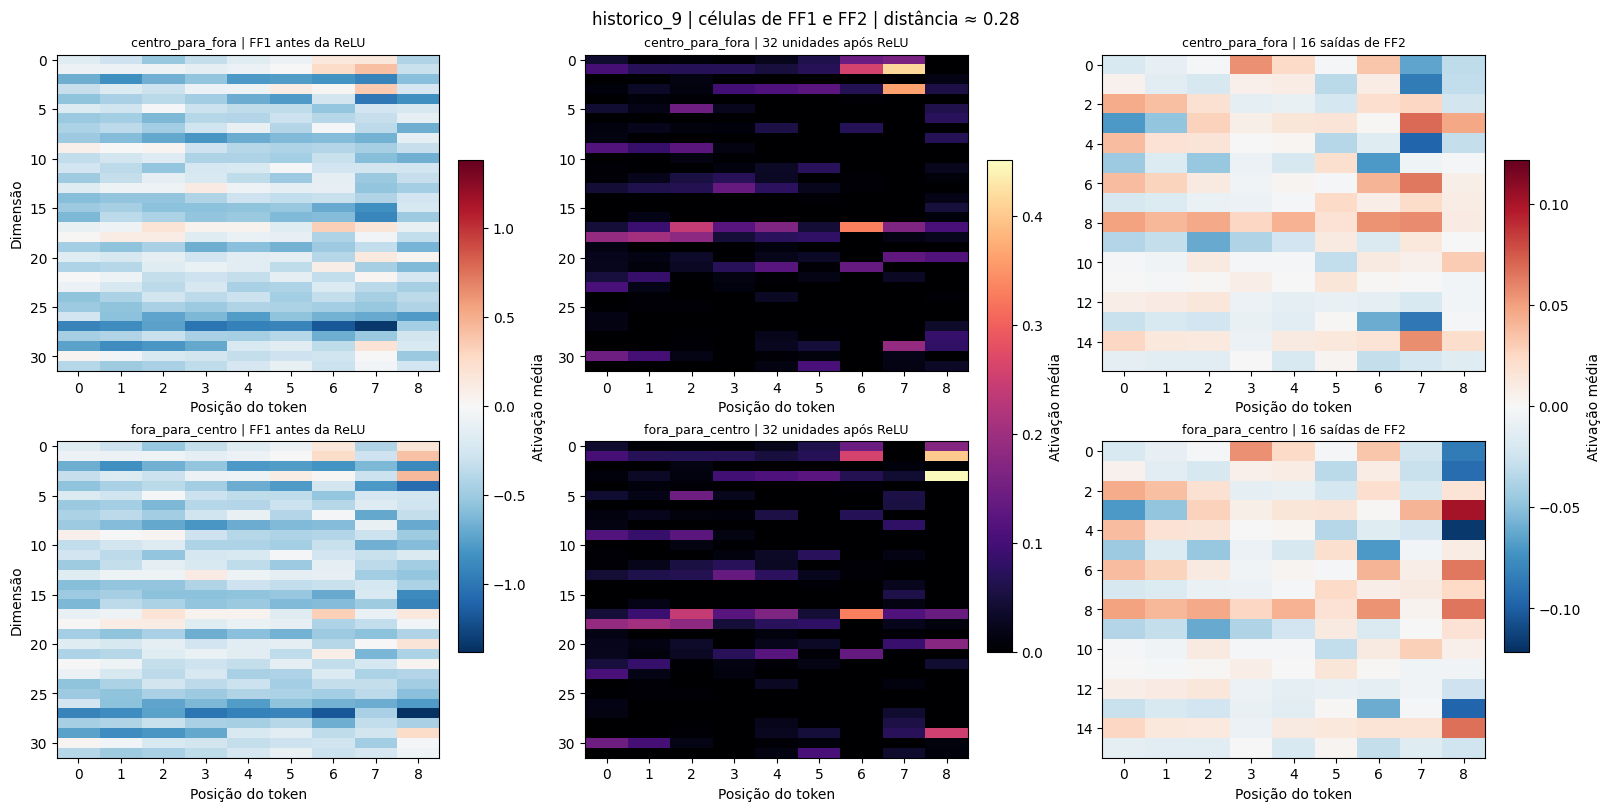

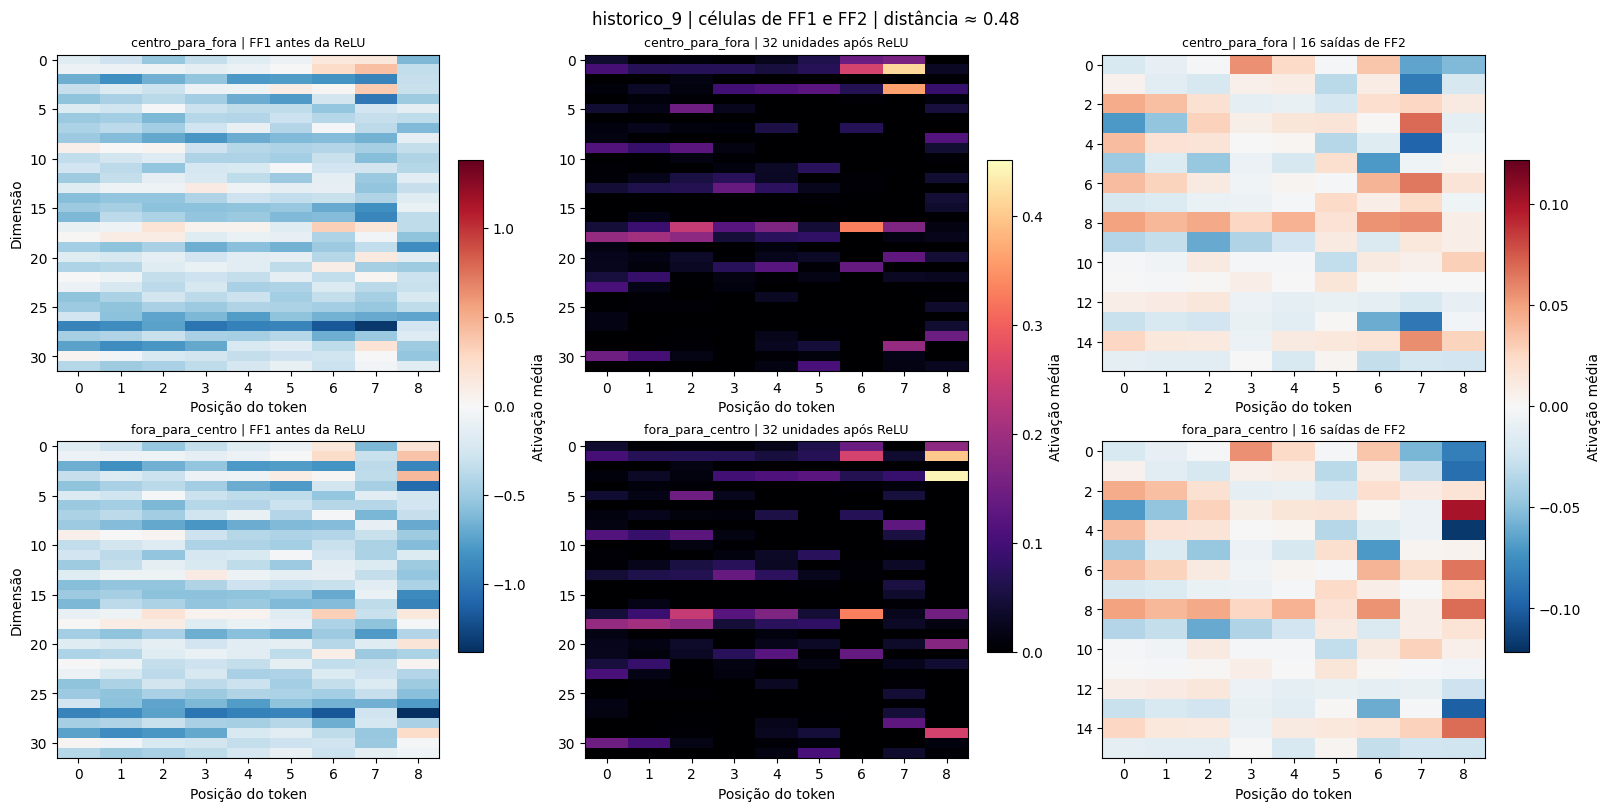

12 mapas de ativação individual por passo salvos para os dois modos e seis distâncias.


In [15]:
dimension_stages=[('ff1',32,'FF1 antes da ReLU','RdBu_r'),
                  ('relu',32,'32 unidades após ReLU','magma'),
                  ('ff2',16,'16 saídas de FF2','RdBu_r')]
for mode in ['par_curto','historico_9']:
    part=step_trace[step_trace['mode']==mode]
    steps=sorted(part.step.unique())
    stage_means={}
    bounds={}
    for stage,width,title,cmap in dimension_stages:
        cols=[f'{stage}__d{i:02d}' for i in range(width)]
        stage_means[stage]=part.groupby(['direction','ring','step'])[cols].mean()
        bounds[stage]=max(1e-9,float(np.abs(stage_means[stage].to_numpy()).max()))
    for ring,radius in enumerate(radii):
        fig,axes=plt.subplots(2,3,figsize=(16,8),constrained_layout=True)
        for col,(stage,width,title,cmap) in enumerate(dimension_stages):
            bound=bounds[stage]
            for row,direction in enumerate(order):
                matrix=np.stack([stage_means[stage].loc[(direction,ring,step)].to_numpy()
                                 for step in steps],axis=1)
                im=axes[row,col].imshow(matrix,aspect='auto',cmap=cmap,
                                        vmin=0 if stage=='relu' else -bound,vmax=bound)
                axes[row,col].set_title(direction+' | '+title,fontsize=9)
                axes[row,col].set_xticks(range(len(steps)),steps)
                axes[row,col].set_xlabel('Posição do token')
                if col==0:axes[row,col].set_ylabel('Dimensão')
            fig.colorbar(im,ax=axes[:,col],shrink=.7,label='Ativação média')
        fig.suptitle(f'{mode} | células de FF1 e FF2 | distância ≈ {radius:.2f}')
        path=root/f'imgs/hardpos_ffw_contexto10_celulas_por_passo_{mode}_distancia_{ring:02d}.png'
        fig.savefig(path,dpi=140,bbox_inches='tight')
        if ring in [0,3,5]:display(fig)
        plt.close(fig)
print('12 mapas de ativação individual por passo salvos para os dois modos e seis distâncias.')

### Leitura dos mapas por passo

Nos contextos de 9 tokens, os passos 0 a 6 usam o mesmo histórico real em todas as distâncias. Com atenção causal, suas ativações são idênticas entre os cenários. No sentido centro → fora, o passo 7 também é o mesmo PS central: a diferença surge no passo 8, onde mudamos o PS final. No sentido fora → centro, a diferença surge no passo 7, onde colocamos o PS periférico; no passo 8, o PS central fixo ainda pode receber informação desse passo anterior pela atenção.

A variação da média absoluta de FF1 entre os seis raios foi 0,0437 no passo 8 para centro → fora; para fora → centro, foi 0,0325 no passo 7 e apenas 0,0019 no passo 8. Assim, o contraste mais forte está associado ao token que foi trocado. Uma célula individual pode ter resposta diferente da média da camada; consulte os mapas das 32 dimensões e a tabela de ativações por passo. Essas respostas ainda não identificam, sozinhas, uma speed cell.

## Q, K e V em função da pseudovelocidade

Repetimos a leitura de FF1/FF2 nas três projeções da atenção. Cada peso treinado W_Q, W_K ou W_V tem forma 16 × 16 e permanece fixo; o que muda com o PS e com o passo é o vetor projetado e a contribuição de cada peso. Aqui velocidade significa distância entre centros dos dois PS dividida pelo intervalo de referência de 0,15 s. Ela serve para ordenar os saltos sintéticos; não é uma medida de velocidade real do animal nesses pares. Mostramos os dois sentidos, os seis grupos de velocidade e todas as posições válidas do input.

Q/K/V: 8832 linhas por passo; pesos 16 × 16; atenção causal verificada.
Pseudovelocidades médias: [0.24  0.534 1.046 1.836 2.668 3.143]


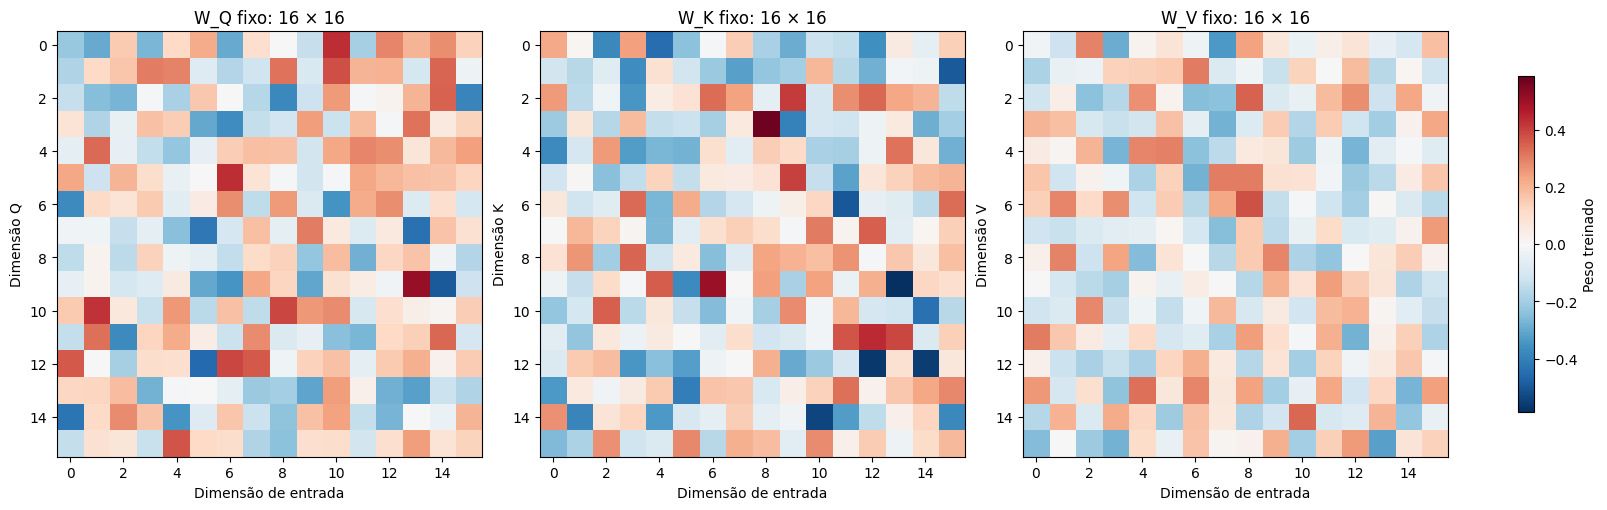

In [16]:
Wq,Wk,Wv=layer.self_attn.in_proj_weight.detach().chunk(3,dim=0)
bq,bk,bv=layer.self_attn.in_proj_bias.detach().chunk(3,dim=0)
qkv_weights={'Q':Wq.numpy(),'K':Wk.numpy(),'V':Wv.numpy()}
qkv_biases={'Q':bq.numpy(),'K':bk.numpy(),'V':bv.numpy()}
assert all(w.shape==(16,16) for w in qkv_weights.values())

@torch.inference_mode()
def trace_qkv(batch,pair_at_end=False):
    emb=model.embedding(batch)
    pos=emb+model.position_embedding.pe[7:9].unsqueeze(0) if pair_at_end else model.position_embedding(emb)
    q,k,v=F.linear(pos,layer.self_attn.in_proj_weight,layer.self_attn.in_proj_bias).chunk(3,dim=-1)
    _,attention=layer.self_attn(pos,pos,pos,
        attn_mask=model._causal_mask(batch.shape[1],batch.device),
        need_weights=True,average_attn_weights=False)
    logits=q@k.transpose(-2,-1)/math.sqrt(q.shape[-1])
    mask=torch.triu(torch.ones(logits.shape[-2:],dtype=torch.bool),diagonal=1)
    expected=logits.masked_fill(mask,float('-inf')).softmax(dim=-1)
    torch.testing.assert_close(attention[:,0],expected,atol=1e-5,rtol=1e-5)
    return {'input':pos.numpy(),'Q':q.numpy(),'K':k.numpy(),'V':v.numpy()},attention[:,0].numpy(),logits.numpy()

qkv_tables=[]
qkv_attention_tables=[]
attention_arrays={}
for mode,batches,metadata,pair_mode,step_positions in [
    ('par_curto',inputs,meta,True,[7,8]),
    ('historico_9',full_inputs,full_meta,False,list(range(9)))]:
    chunks={}
    weights_chunks=[]
    logits_chunks=[]
    for offset in range(0,len(batches),32):
        stages,weights,logits=trace_qkv(batches[offset:offset+32],pair_mode)
        for stage,a in stages.items():chunks.setdefault(stage,[]).append(a)
        weights_chunks.append(weights)
        logits_chunks.append(logits)
    arrays={stage:np.concatenate(parts) for stage,parts in chunks.items()}
    n_steps=len(step_positions)
    table=metadata[['ring','sector','direction','distance','peripheral_ps_id']].iloc[
        np.repeat(np.arange(len(metadata)),n_steps)].reset_index(drop=True)
    table['mode']=mode
    table['step']=np.tile(step_positions,len(metadata))
    table['speed_proxy']=table['distance']/reference_dt
    values={}
    for stage,a in arrays.items():
        flat=a.reshape(-1,16)
        values.update({f'{stage}__d{j:02d}':flat[:,j] for j in range(16)})
        values[f'{stage}_mean_abs']=np.abs(flat).mean(axis=1)
    table=pd.concat([table,pd.DataFrame(values)],axis=1)
    for stage in ['Q','K','V']:
        pred=arrays['input']@qkv_weights[stage].T+qkv_biases[stage]
        np.testing.assert_allclose(pred,arrays[stage],atol=1e-5,rtol=1e-5)
    qkv_tables.append(table)
    attention_arrays[mode]=np.concatenate(weights_chunks)
    all_logits=np.concatenate(logits_chunks)
    at=metadata[['ring','sector','direction','distance','peripheral_ps_id']].reset_index(drop=True).copy()
    at['mode']=mode
    at['speed_proxy']=at['distance']/reference_dt
    at['qk_source_logit']=all_logits[:,-1,-2]
    at['qk_self_logit']=all_logits[:,-1,-1]
    at['attention_to_source']=attention_arrays[mode][:,-1,-2]
    at['attention_to_self']=attention_arrays[mode][:,-1,-1]
    qkv_attention_tables.append(at)
qkv_trace=pd.concat(qkv_tables,ignore_index=True)
qkv_attention=pd.concat(qkv_attention_tables,ignore_index=True)
qkv_trace.to_parquet(root/'legacy/analysis/HardPos_qkv_contexto10_todos_passos.parquet',index=False)
qkv_attention.to_parquet(root/'legacy/analysis/HardPos_qkv_contexto10_atencao.parquet',index=False)
speed_ticks=(meta.groupby('ring').distance.mean()/reference_dt).to_numpy()
print('Q/K/V:',len(qkv_trace),'linhas por passo; pesos 16 × 16; atenção causal verificada.')
print('Pseudovelocidades médias:',np.round(speed_ticks,3))

fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
bound=max(float(np.abs(w).max()) for w in qkv_weights.values())
for ax,(stage,w) in zip(axes,qkv_weights.items()):
    im=ax.imshow(w,aspect='equal',cmap='RdBu_r',vmin=-bound,vmax=bound)
    ax.set(title=f'W_{stage} fixo: 16 × 16',xlabel='Dimensão de entrada',ylabel=f'Dimensão {stage}')
fig.colorbar(im,ax=axes,shrink=.75,label='Peso treinado')
fig.savefig(root/'imgs/hardpos_qkv_contexto10_pesos_fixos.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

### Atividade média e cada dimensão de Q, K e V

A média absoluta resume a magnitude da projeção. Os mapas individuais preservam o sinal de cada dimensão. Em cada painel, a linha é um passo do input e a coluna é um grupo de pseudovelocidade; no painel detalhado por velocidade, as linhas são as 16 dimensões. As escalas de cada projeção são compartilhadas entre os sentidos e entre os seis grupos do mesmo modo.

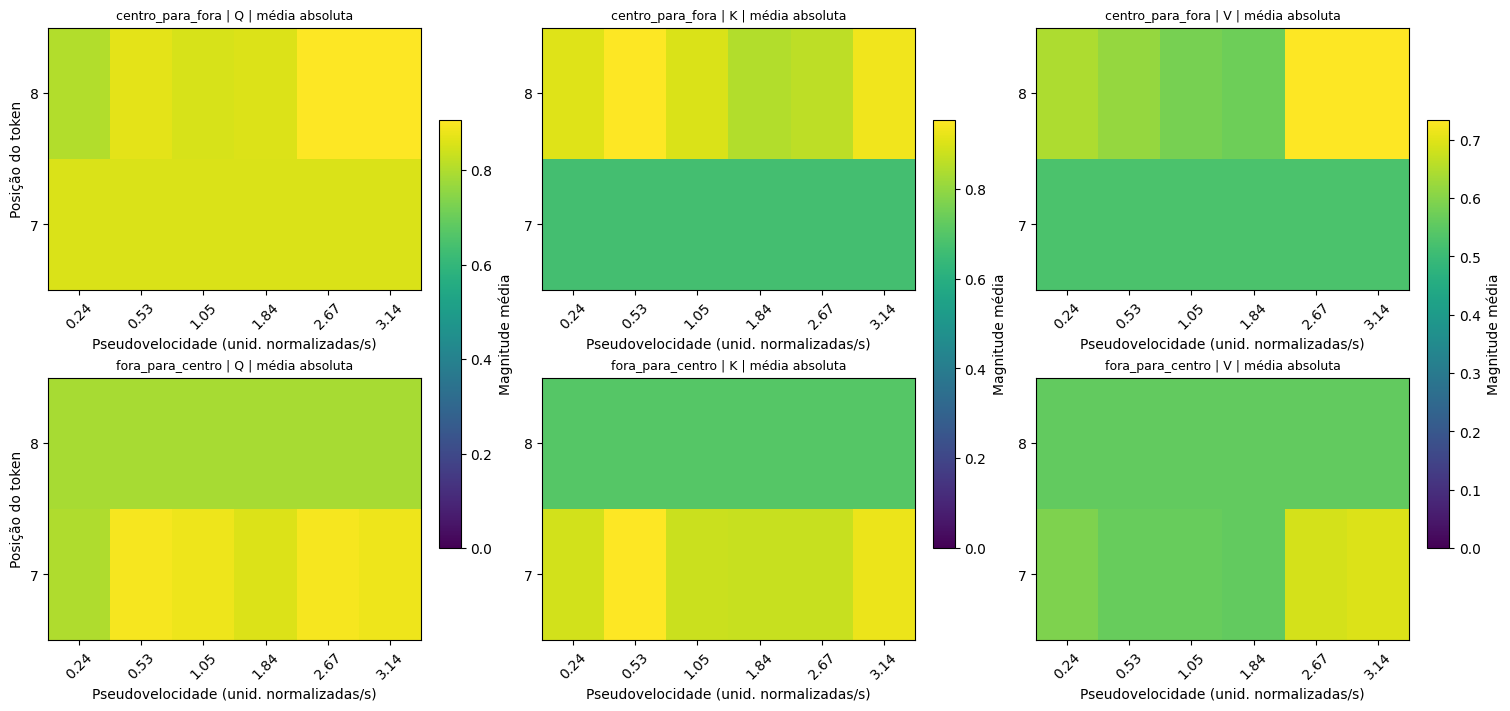

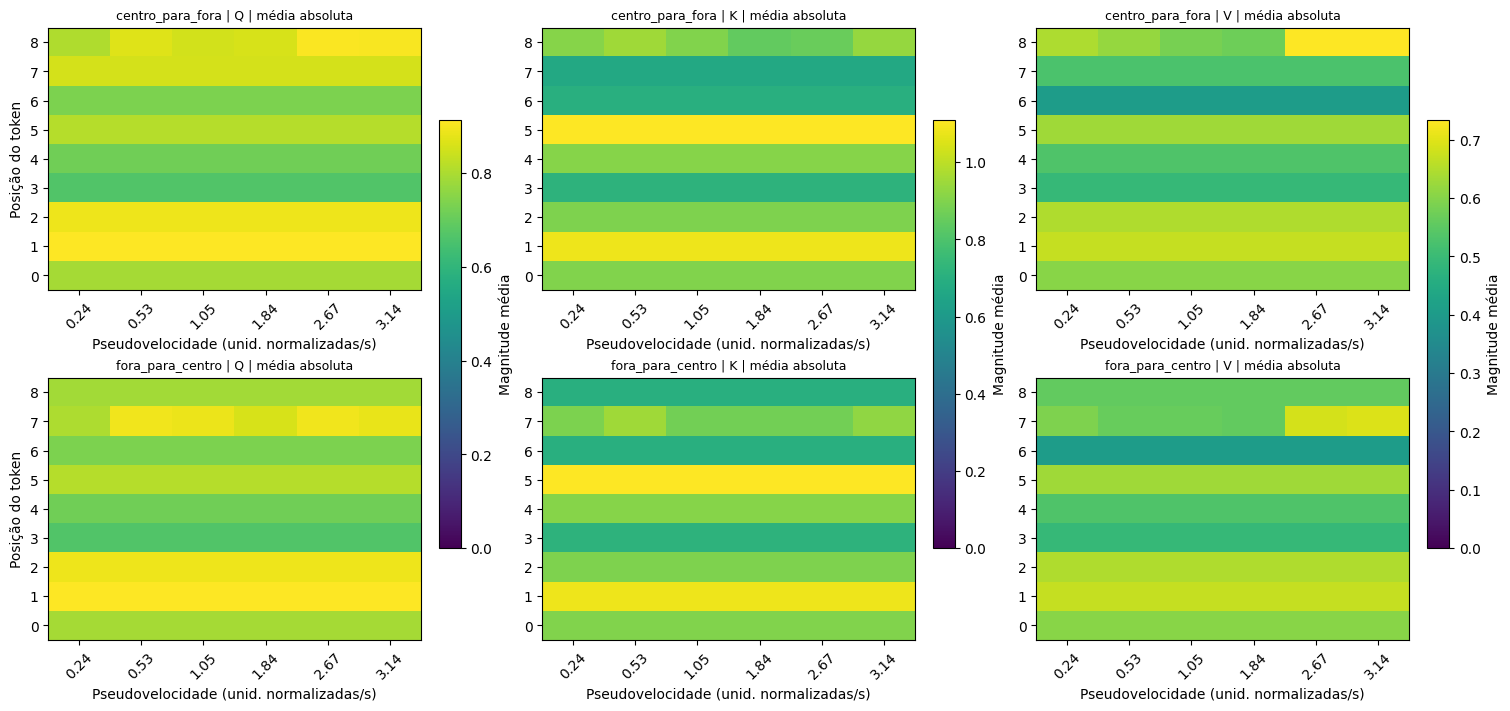

speed_proxy  Q_mean_abs  K_mean_abs  V_mean_abs
direction        ring                                                 
centro_para_fora 0           0.240       0.804       0.907       0.646
                 1           0.534       0.871       0.954       0.619
                 2           1.046       0.853       0.901       0.584
                 3           1.836       0.858       0.845       0.572
                 4           2.668       0.907       0.858       0.734
                 5           3.143       0.905       0.933       0.735
fora_para_centro 0           0.240       0.788       0.702       0.557
                 1           0.534       0.788       0.702       0.557
                 2           1.046       0.788       0.702       0.557
                 3           1.836       0.788       0.702       0.557
                 4           2.668       0.788       0.702       0.557
                 5           3.143       0.788       0.702       0.557

In [17]:
qkv_stages=['Q','K','V']
for mode in ['par_curto','historico_9']:
    part=qkv_trace[qkv_trace['mode']==mode]
    steps=sorted(part.step.unique())
    grouped=part.groupby(['direction','ring','step'])[[f'{s}_mean_abs' for s in qkv_stages]].mean()
    fig,axes=plt.subplots(2,3,figsize=(15,7),constrained_layout=True)
    for col,stage in enumerate(qkv_stages):
        vmax=float(grouped[f'{stage}_mean_abs'].max())
        for row,direction in enumerate(order):
            matrix=np.array([[grouped.loc[(direction,ring,step),f'{stage}_mean_abs']
                              for ring in range(len(radii))] for step in steps])
            im=axes[row,col].imshow(matrix,origin='lower',aspect='auto',cmap='viridis',vmin=0,vmax=vmax)
            axes[row,col].set_title(direction+' | '+stage+' | média absoluta',fontsize=9)
            axes[row,col].set_xticks(range(len(radii)),[f'{v:.2f}' for v in speed_ticks],rotation=45)
            axes[row,col].set_yticks(range(len(steps)),steps)
            axes[row,col].set_xlabel('Pseudovelocidade (unid. normalizadas/s)')
            if col==0:axes[row,col].set_ylabel('Posição do token')
        fig.colorbar(im,ax=axes[:,col],shrink=.7,label='Magnitude média')
    fig.savefig(root/f'imgs/hardpos_qkv_contexto10_media_por_passo_{mode}.png',dpi=140,bbox_inches='tight')
    display(fig)
    plt.close(fig)
    if mode=='historico_9':
        display(part[part.step==8].groupby(['direction','ring'])
                [['speed_proxy','Q_mean_abs','K_mean_abs','V_mean_abs']].mean().round(3))

### Cada dimensão diretamente contra a pseudovelocidade

Os painéis abaixo deixam uma das posições do par fixa (7 ou 8) e variam os seis grupos de pseudovelocidade. Cada linha do heatmap é uma dimensão de Q, K ou V; cada coluna é um grupo de saltos. Isso facilita procurar dimensões que respondem gradualmente ao salto, sem confundir mudanças entre os passos do contexto.

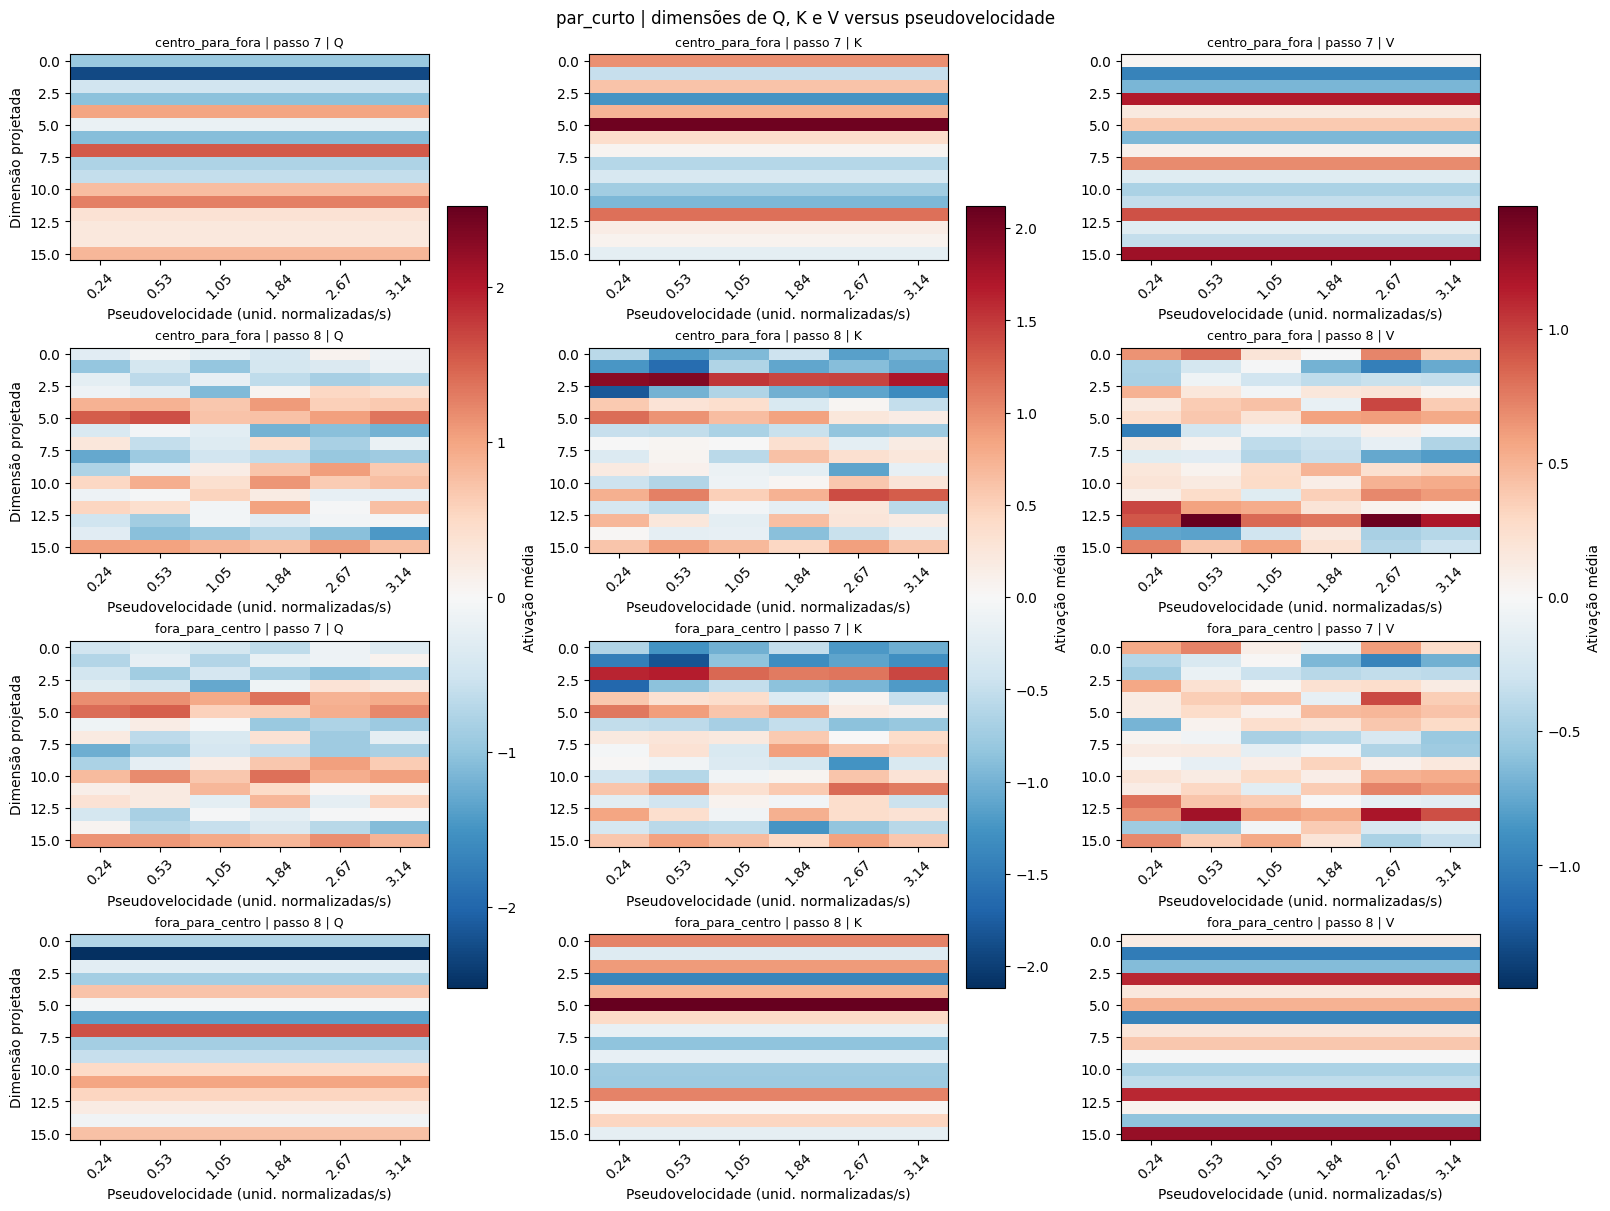

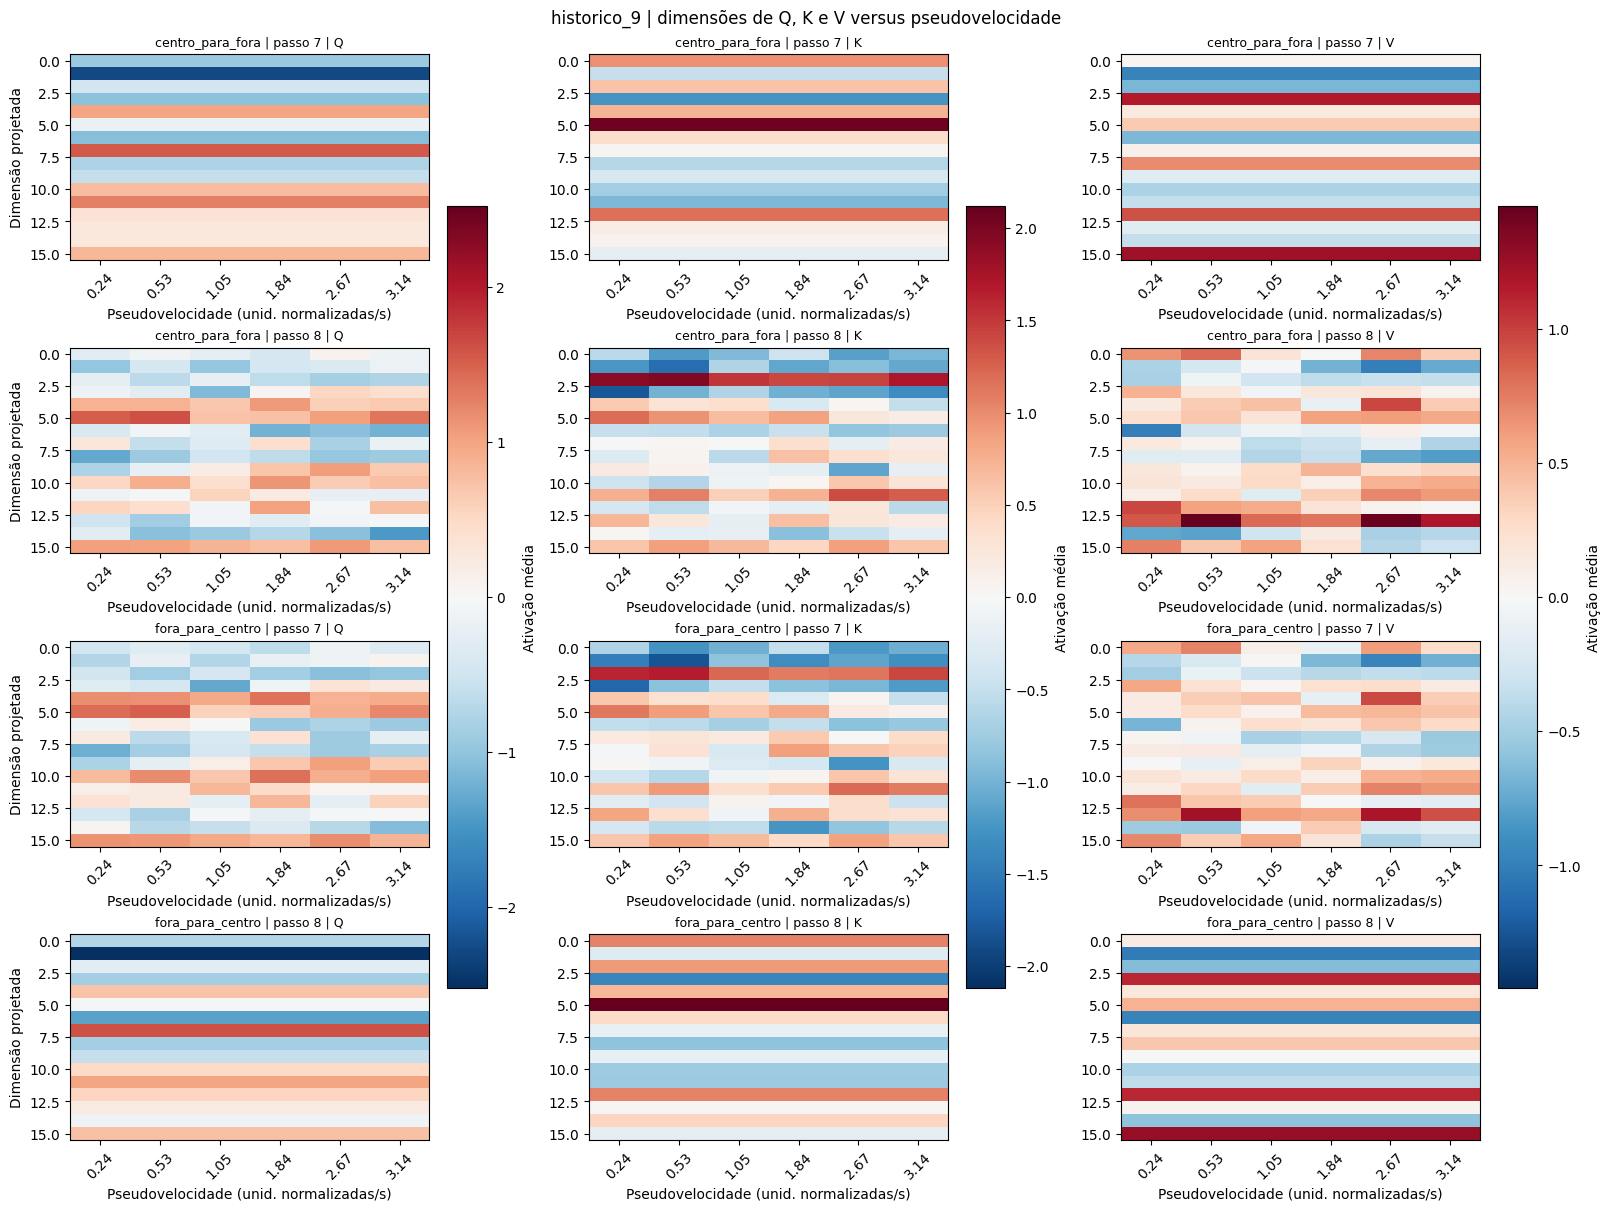

In [18]:
for mode in ['par_curto','historico_9']:
    part=qkv_trace[qkv_trace['mode']==mode]
    fig,axes=plt.subplots(4,3,figsize=(16,12),constrained_layout=True)
    for col,stage in enumerate(qkv_stages):
        cols=[f'{stage}__d{i:02d}' for i in range(16)]
        grouped=part[part.step.isin([7,8])].groupby(['direction','step','ring'])[cols].mean()
        bound=max(1e-9,float(np.abs(grouped.to_numpy()).max()))
        for row,(direction,step) in enumerate([(d,s) for d in order for s in [7,8]]):
            matrix=np.stack([grouped.loc[(direction,step,ring)].to_numpy()
                             for ring in range(len(radii))],axis=1)
            im=axes[row,col].imshow(matrix,aspect='auto',cmap='RdBu_r',
                                    vmin=-bound,vmax=bound)
            axes[row,col].set_title(f'{direction} | passo {step} | {stage}',fontsize=9)
            axes[row,col].set_xticks(range(len(radii)),[f'{v:.2f}' for v in speed_ticks],rotation=45)
            axes[row,col].set_xlabel('Pseudovelocidade (unid. normalizadas/s)')
            if col==0:axes[row,col].set_ylabel('Dimensão projetada')
        fig.colorbar(im,ax=axes[:,col],shrink=.72,label='Ativação média')
    fig.suptitle(mode+' | dimensões de Q, K e V versus pseudovelocidade')
    fig.savefig(root/f'imgs/hardpos_qkv_contexto10_dimensoes_vs_velocidade_{mode}.png',
                dpi=140,bbox_inches='tight')
    display(fig)
    plt.close(fig)

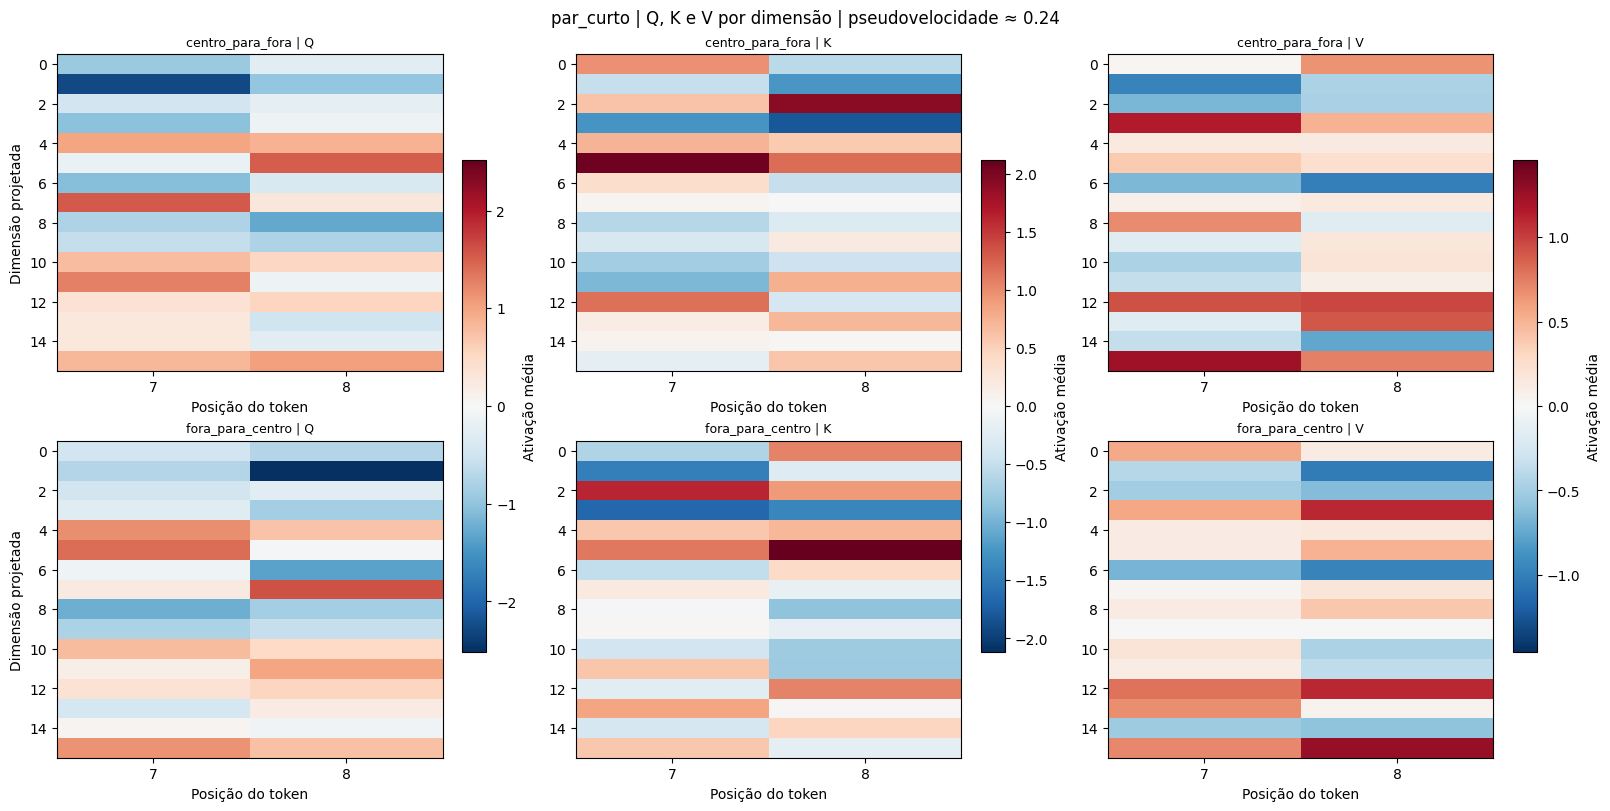

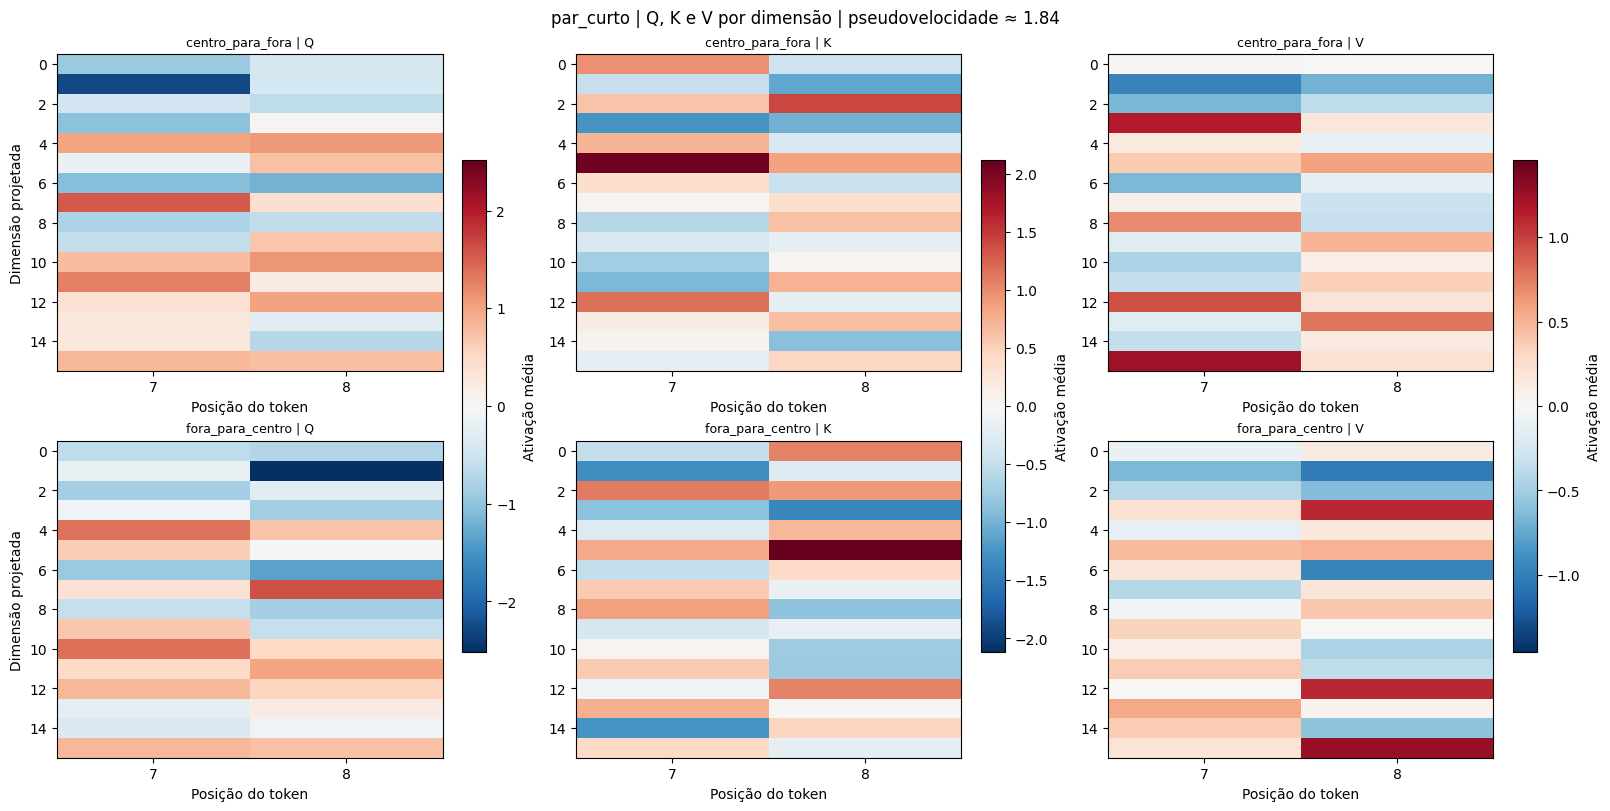

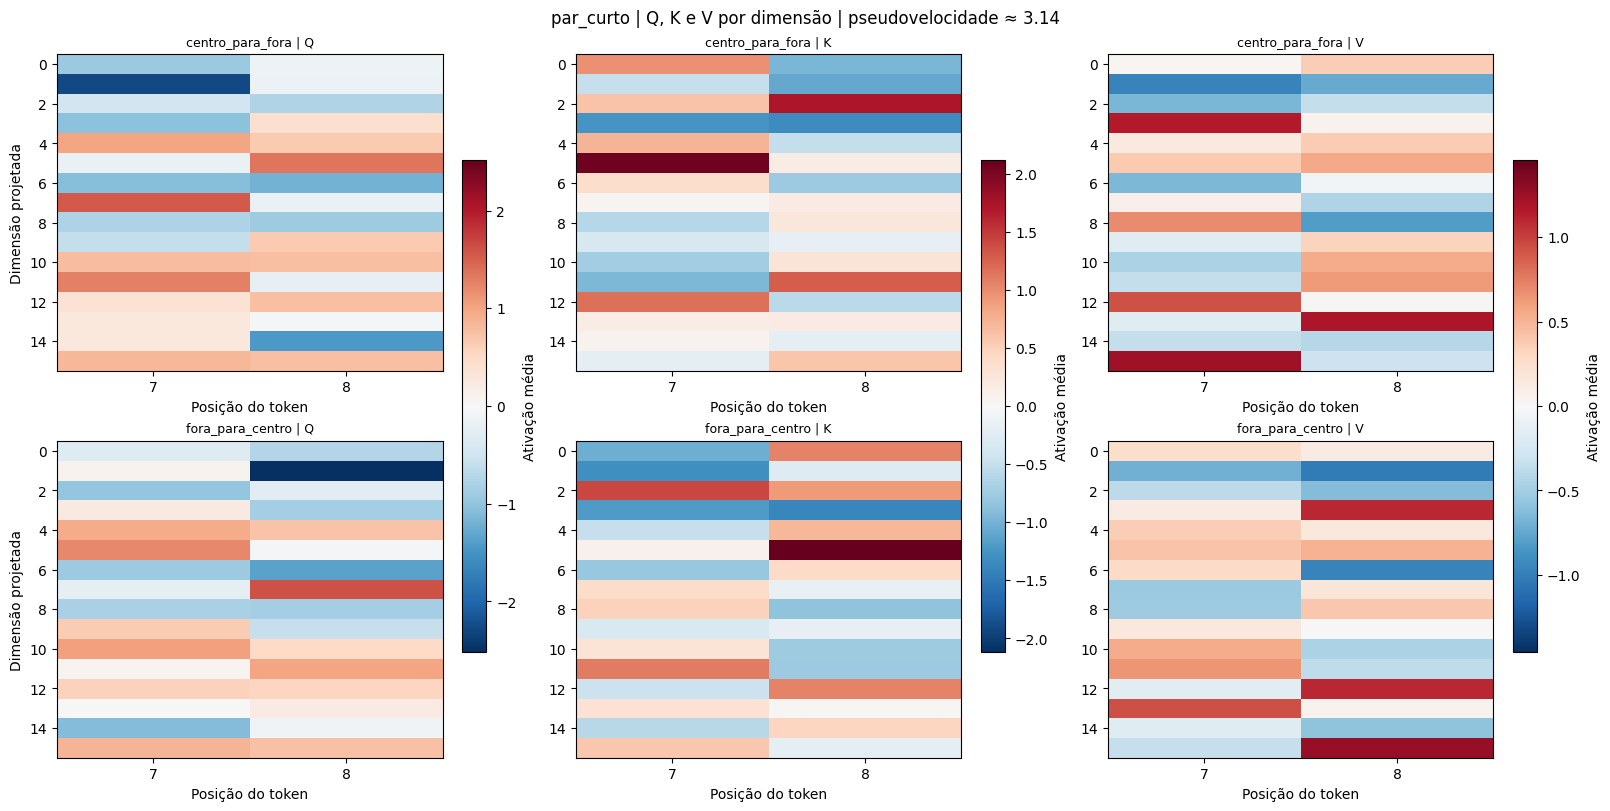

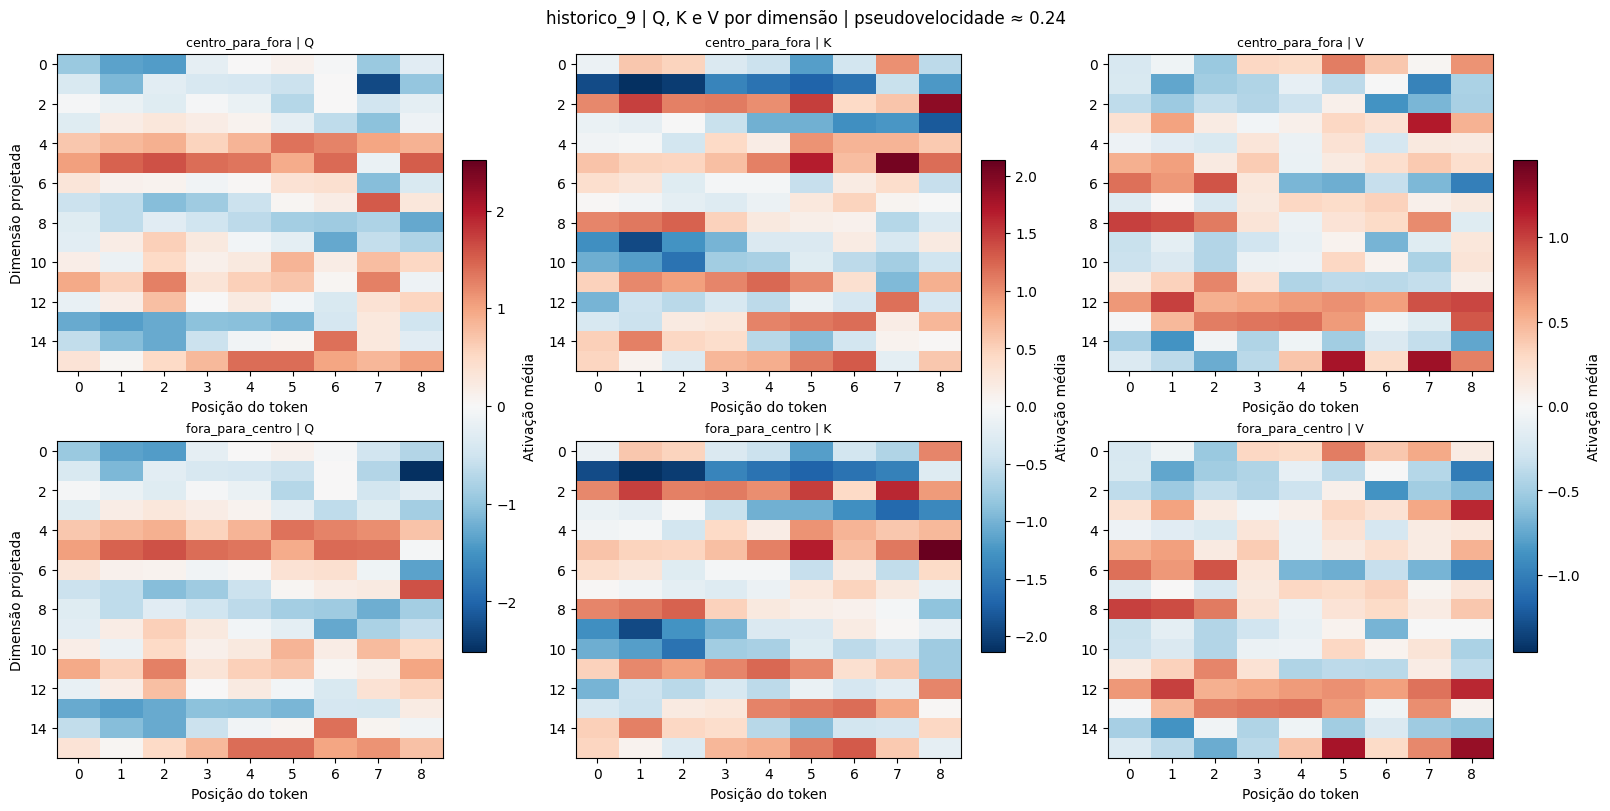

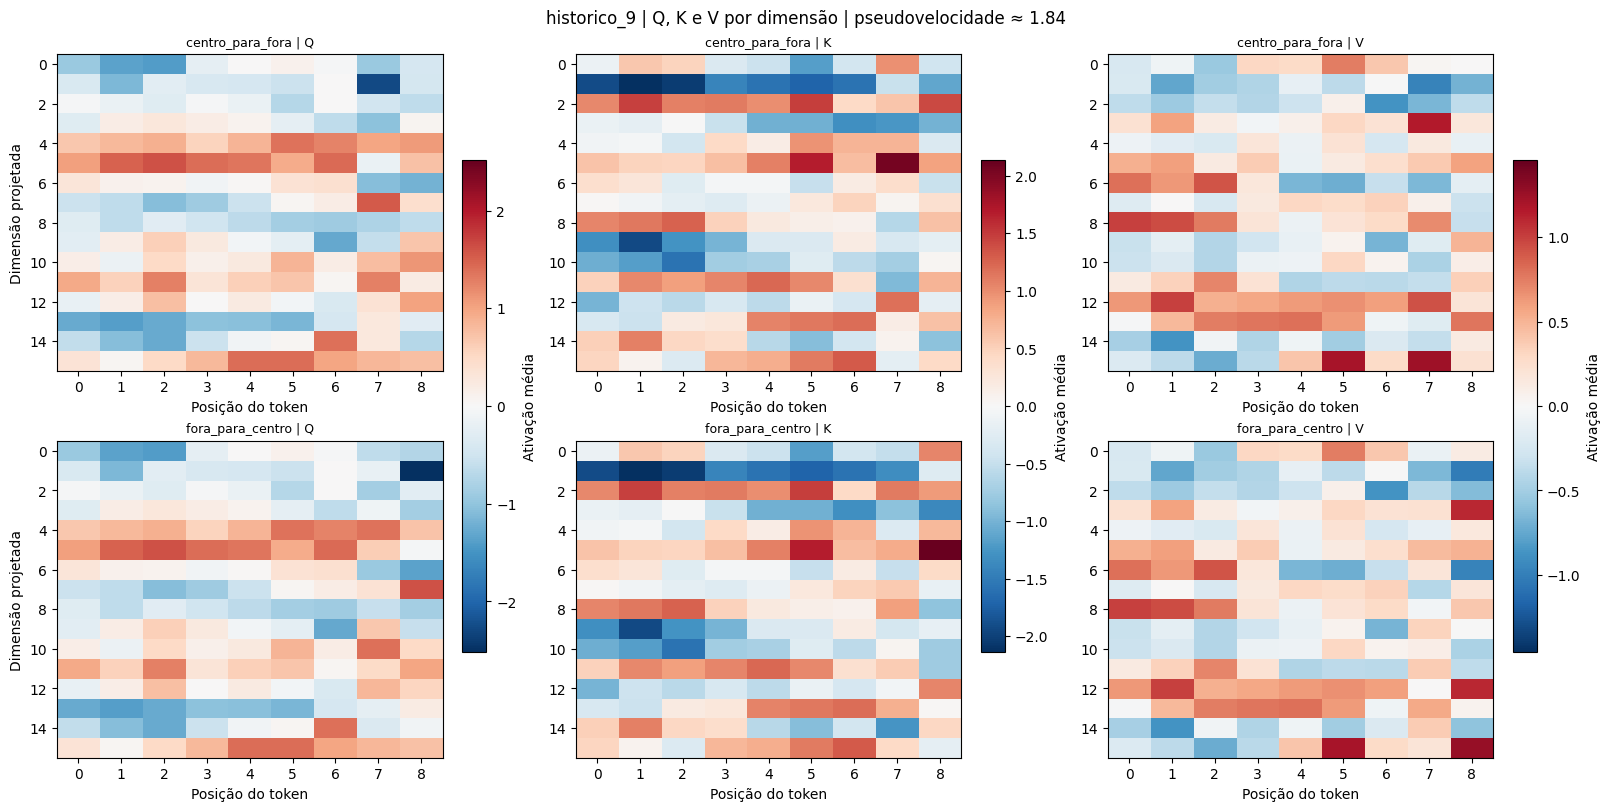

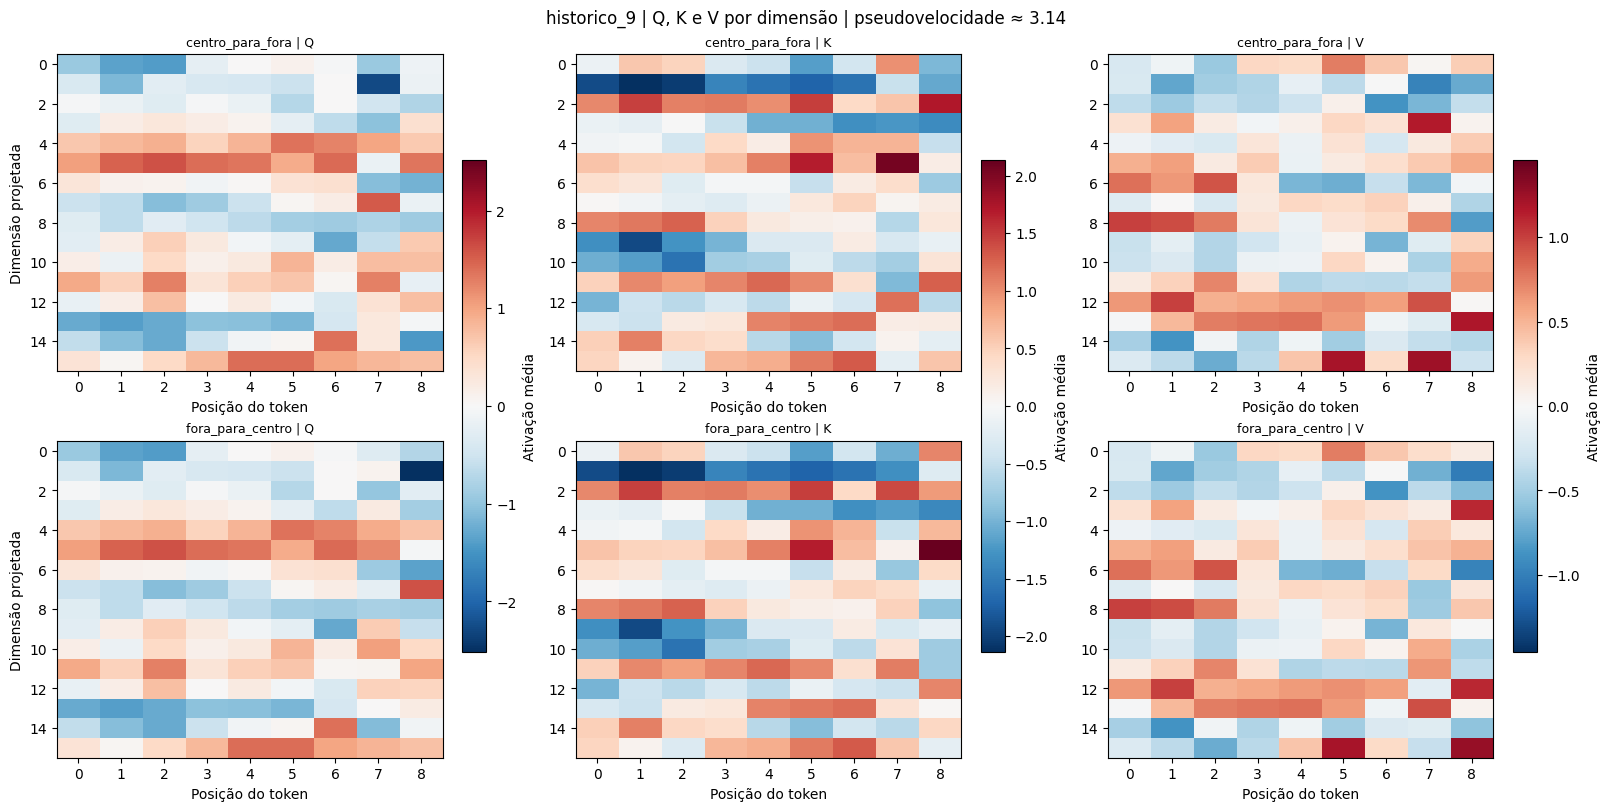

12 mapas de Q/K/V por dimensão e passo salvos.


In [19]:
for mode in ['par_curto','historico_9']:
    part=qkv_trace[qkv_trace['mode']==mode]
    steps=sorted(part.step.unique())
    grouped={stage:part.groupby(['direction','ring','step'])[
        [f'{stage}__d{i:02d}' for i in range(16)]].mean() for stage in qkv_stages}
    bounds={stage:max(1e-9,float(np.abs(frame.to_numpy()).max()))
            for stage,frame in grouped.items()}
    for ring,v in enumerate(speed_ticks):
        fig,axes=plt.subplots(2,3,figsize=(16,8),constrained_layout=True)
        for col,stage in enumerate(qkv_stages):
            for row,direction in enumerate(order):
                matrix=np.stack([grouped[stage].loc[(direction,ring,step)].to_numpy()
                                 for step in steps],axis=1)
                im=axes[row,col].imshow(matrix,aspect='auto',cmap='RdBu_r',
                                        vmin=-bounds[stage],vmax=bounds[stage])
                axes[row,col].set_title(direction+' | '+stage,fontsize=9)
                axes[row,col].set_xticks(range(len(steps)),steps)
                axes[row,col].set_xlabel('Posição do token')
                if col==0:axes[row,col].set_ylabel('Dimensão projetada')
            fig.colorbar(im,ax=axes[:,col],shrink=.7,label='Ativação média')
        fig.suptitle(f'{mode} | Q, K e V por dimensão | pseudovelocidade ≈ {v:.2f}')
        path=root/f'imgs/hardpos_qkv_contexto10_celulas_por_passo_{mode}_velocidade_{ring:02d}.png'
        fig.savefig(path,dpi=140,bbox_inches='tight')
        if ring in [0,3,5]:display(fig)
        plt.close(fig)
print('12 mapas de Q/K/V por dimensão e passo salvos.')

### Contribuição dos pesos de Q, K e V em cada passo

Cada pixel é W_Q, W_K ou W_V multiplicado pela entrada média daquela dimensão no passo indicado. O viés é fixo e não aparece. São seis arquivos por projeção e por modo; cada arquivo contém os dois sentidos e todos os passos para um grupo de pseudovelocidade.

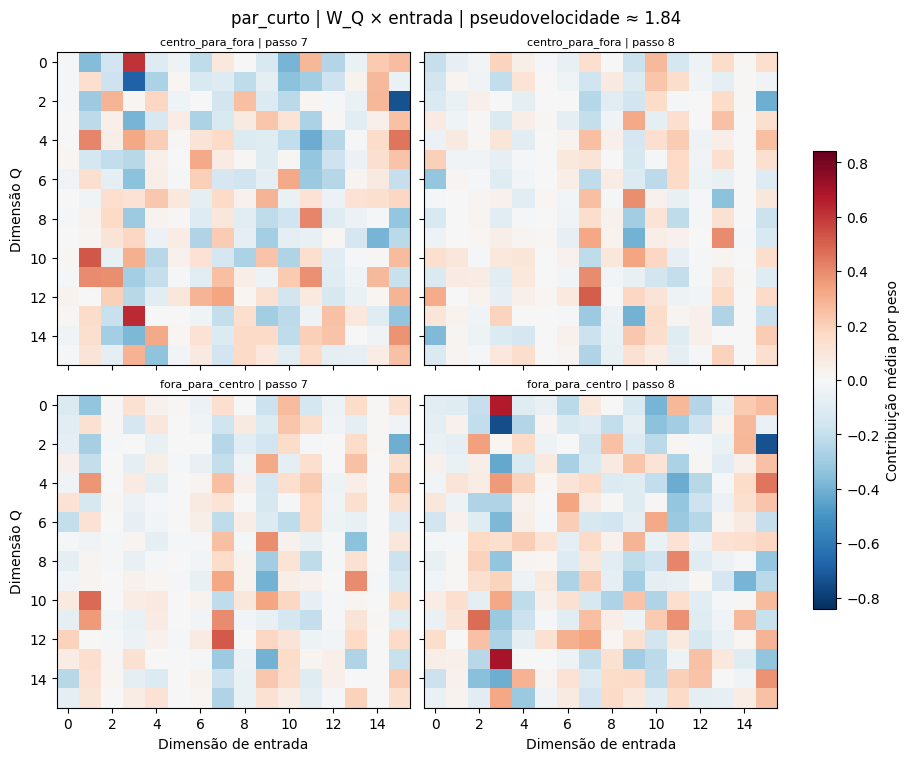

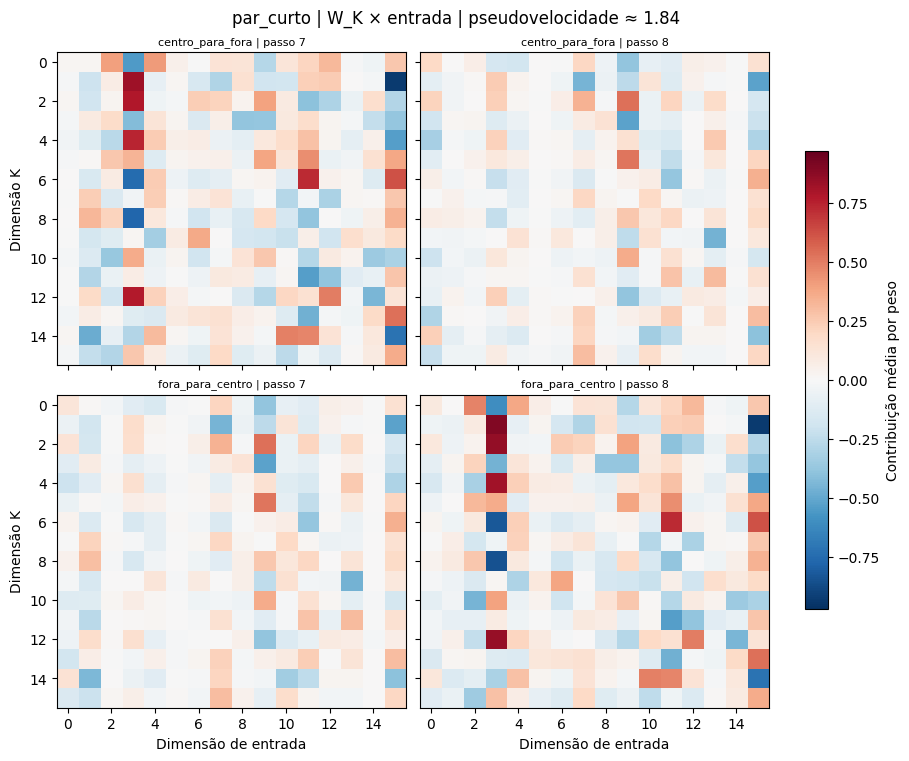

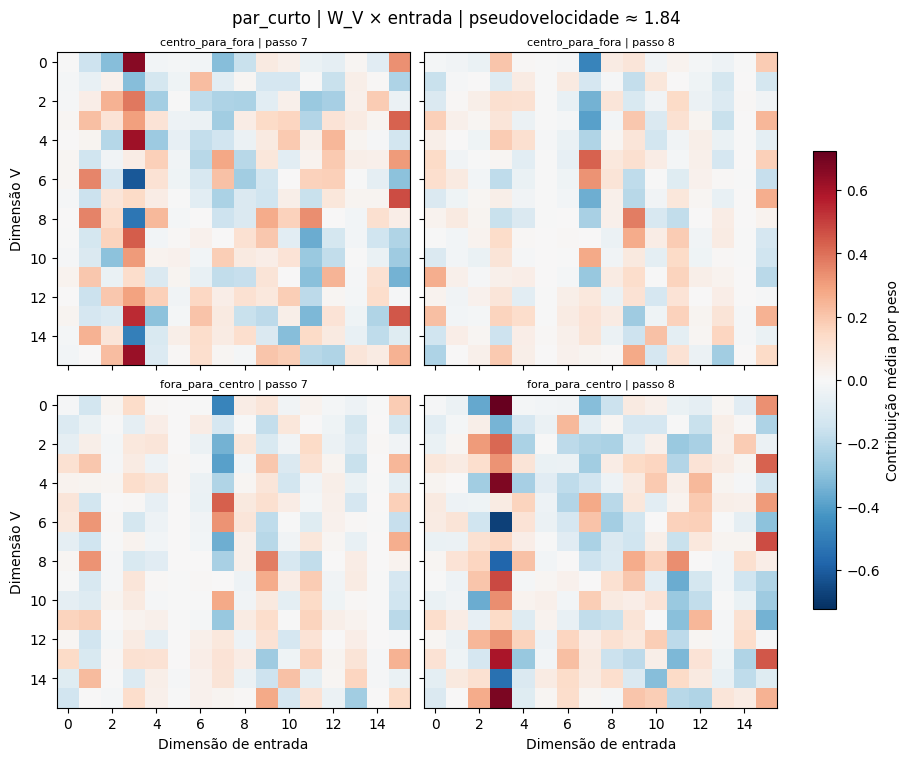

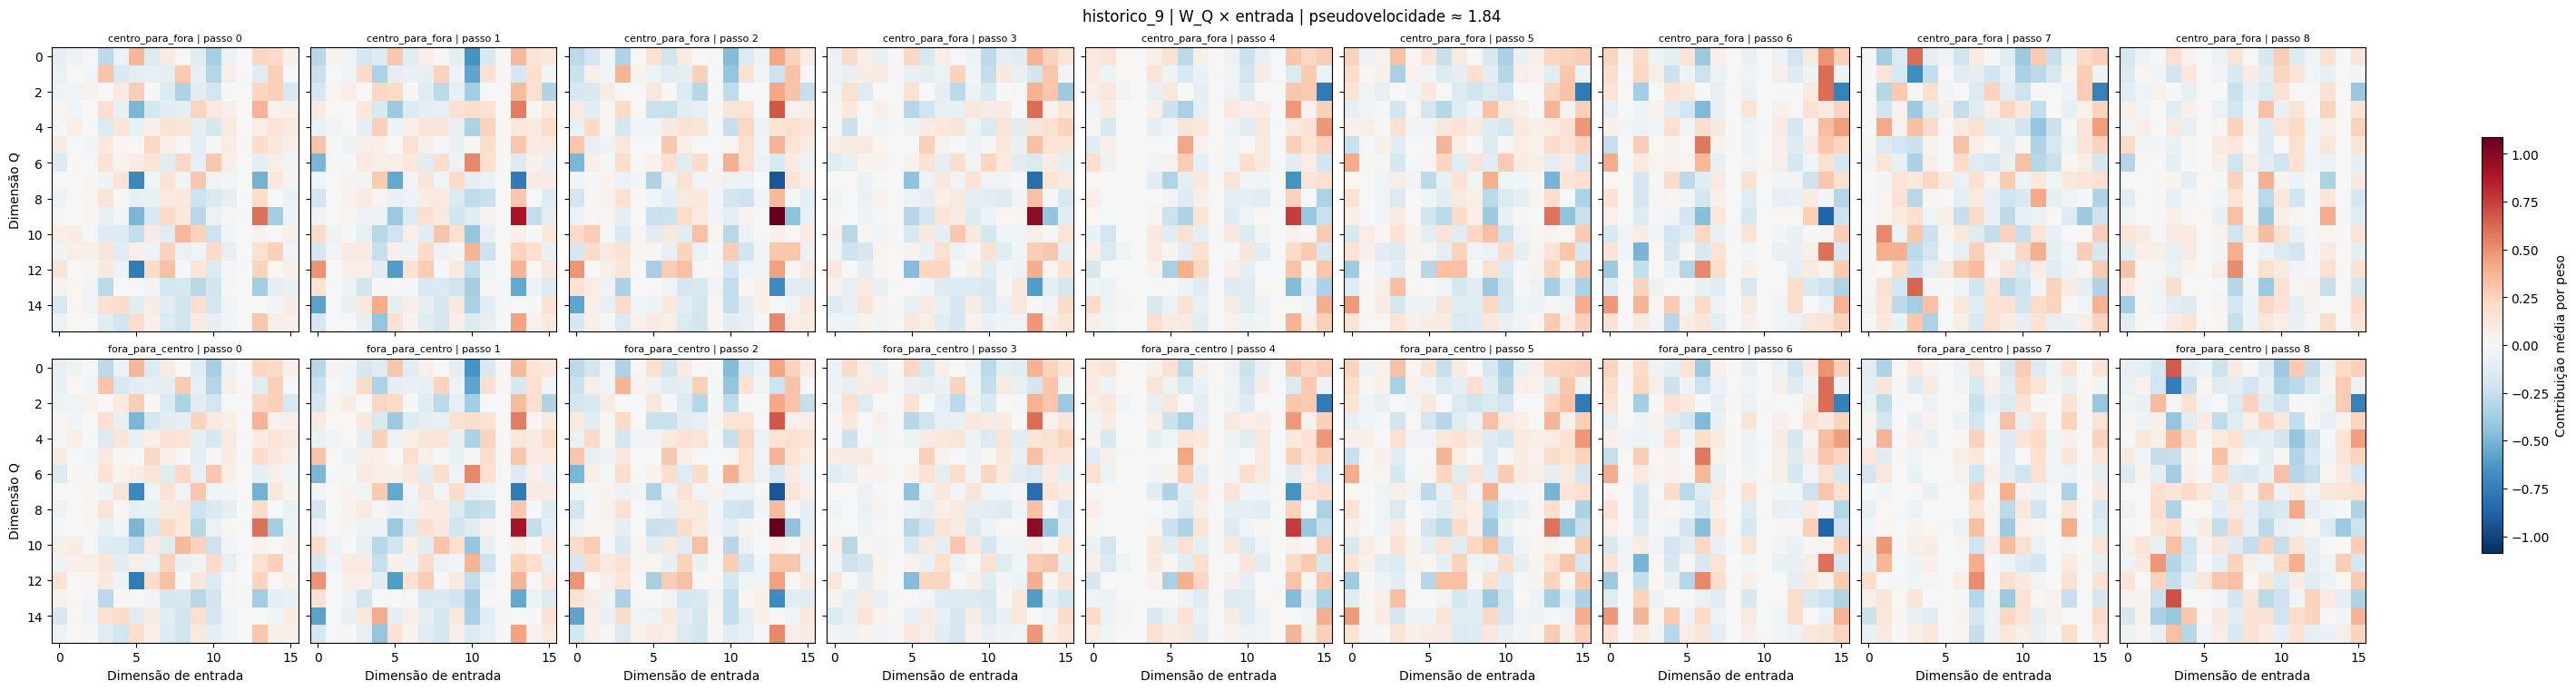

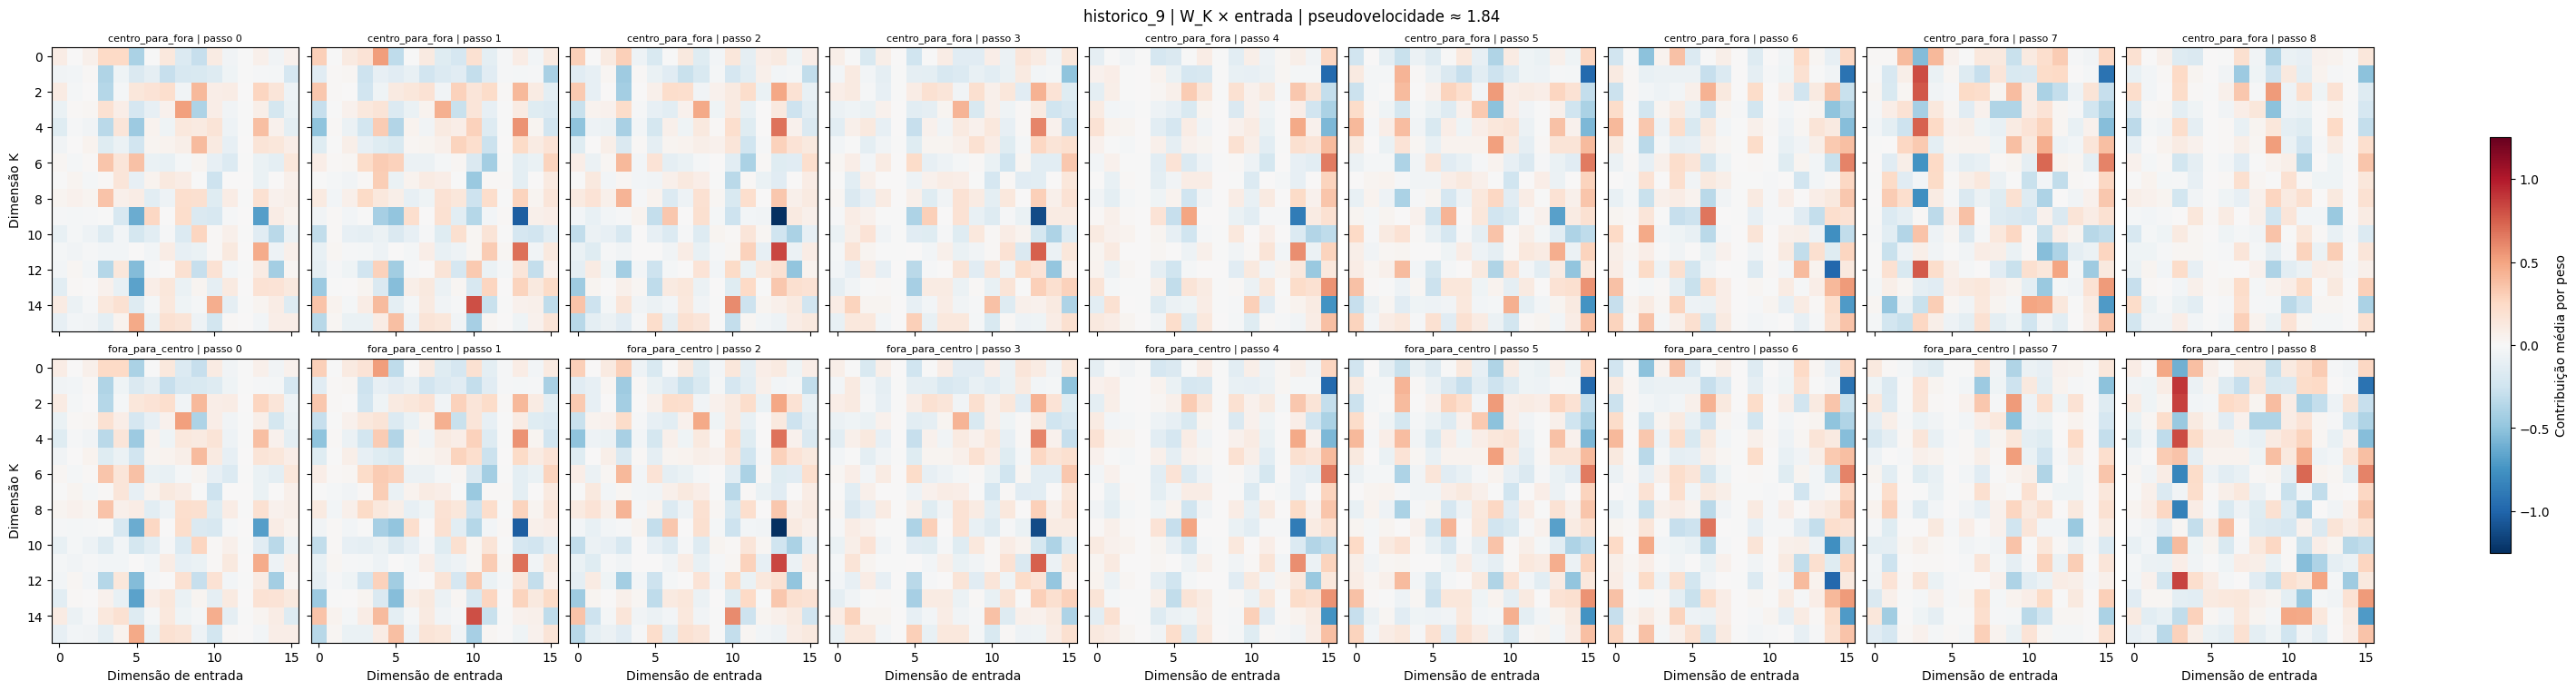

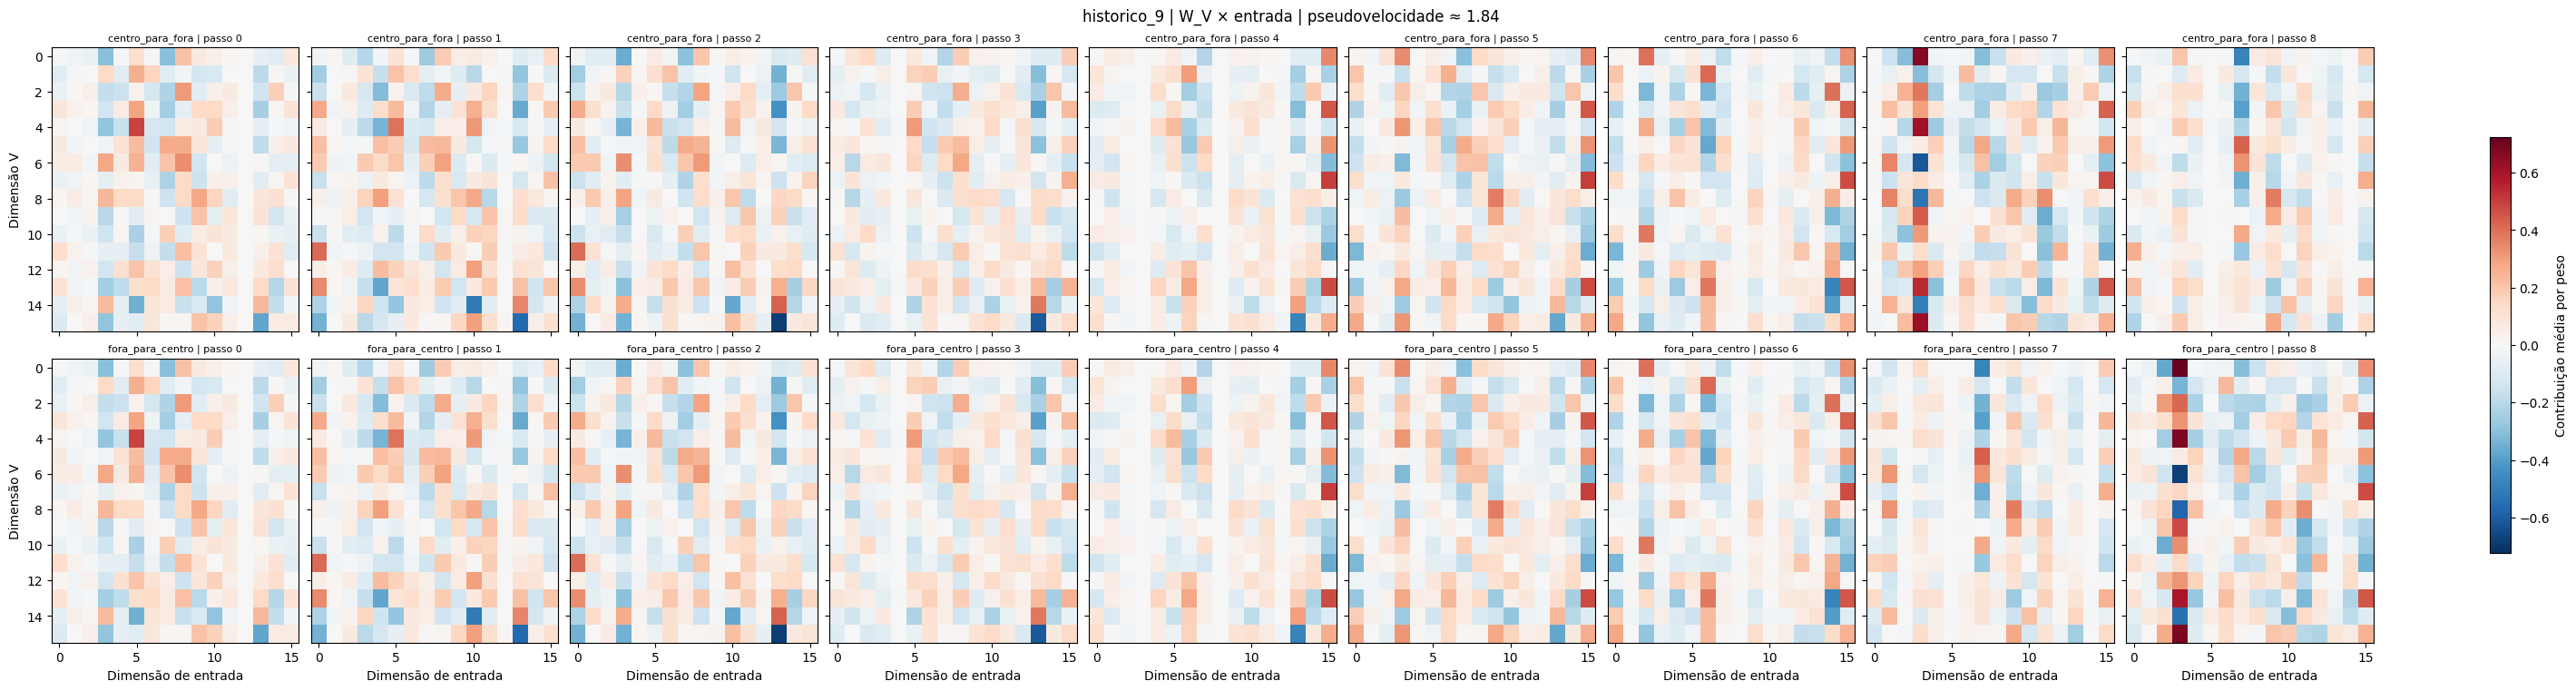

36 mapas de contribuição Q/K/V por passo salvos.


In [20]:
for mode in ['par_curto','historico_9']:
    part=qkv_trace[qkv_trace['mode']==mode]
    steps=sorted(part.step.unique())
    cols=[f'input__d{i:02d}' for i in range(16)]
    grouped=part.groupby(['direction','ring','step'])[cols].mean()
    for stage,w in qkv_weights.items():
        matrices={(direction,ring,step):w*grouped.loc[(direction,ring,step)].to_numpy()[None,:]
                  for direction in order for ring in range(len(radii)) for step in steps}
        bound=max(float(np.abs(a).max()) for a in matrices.values())
        for ring,v in enumerate(speed_ticks):
            fig,axes=plt.subplots(2,len(steps),figsize=(max(9,3.15*len(steps)),7.5),
                                  sharex=True,sharey=True,constrained_layout=True)
            for row,direction in enumerate(order):
                for col,step in enumerate(steps):
                    ax=axes[row,col]
                    im=ax.imshow(matrices[(direction,ring,step)],aspect='auto',
                                 cmap='RdBu_r',vmin=-bound,vmax=bound)
                    ax.set_title(f'{direction} | passo {step}',fontsize=8)
                    if row==1:ax.set_xlabel('Dimensão de entrada')
                    if col==0:ax.set_ylabel(f'Dimensão {stage}')
            fig.colorbar(im,ax=axes,shrink=.7,label='Contribuição média por peso')
            fig.suptitle(f'{mode} | W_{stage} × entrada | pseudovelocidade ≈ {v:.2f}')
            path=root/f'imgs/hardpos_qkv_contexto10_contrib_{stage}_{mode}_velocidade_{ring:02d}.png'
            fig.savefig(path,dpi=130,bbox_inches='tight')
            if ring==3:display(fig)
            plt.close(fig)
print('36 mapas de contribuição Q/K/V por passo salvos.')

### Compatibilidade Q·K e pesos de atenção

Q, K e V de um token dependem de seu PS e posição. O par de PS entra diretamente no produto Q·K entre passos, que determina a atenção. Por isso também medimos o logit do último token para a origem e o peso de atenção correspondente. A coluna V da origem determina o conteúdo transmitido quando essa atenção é aplicada.

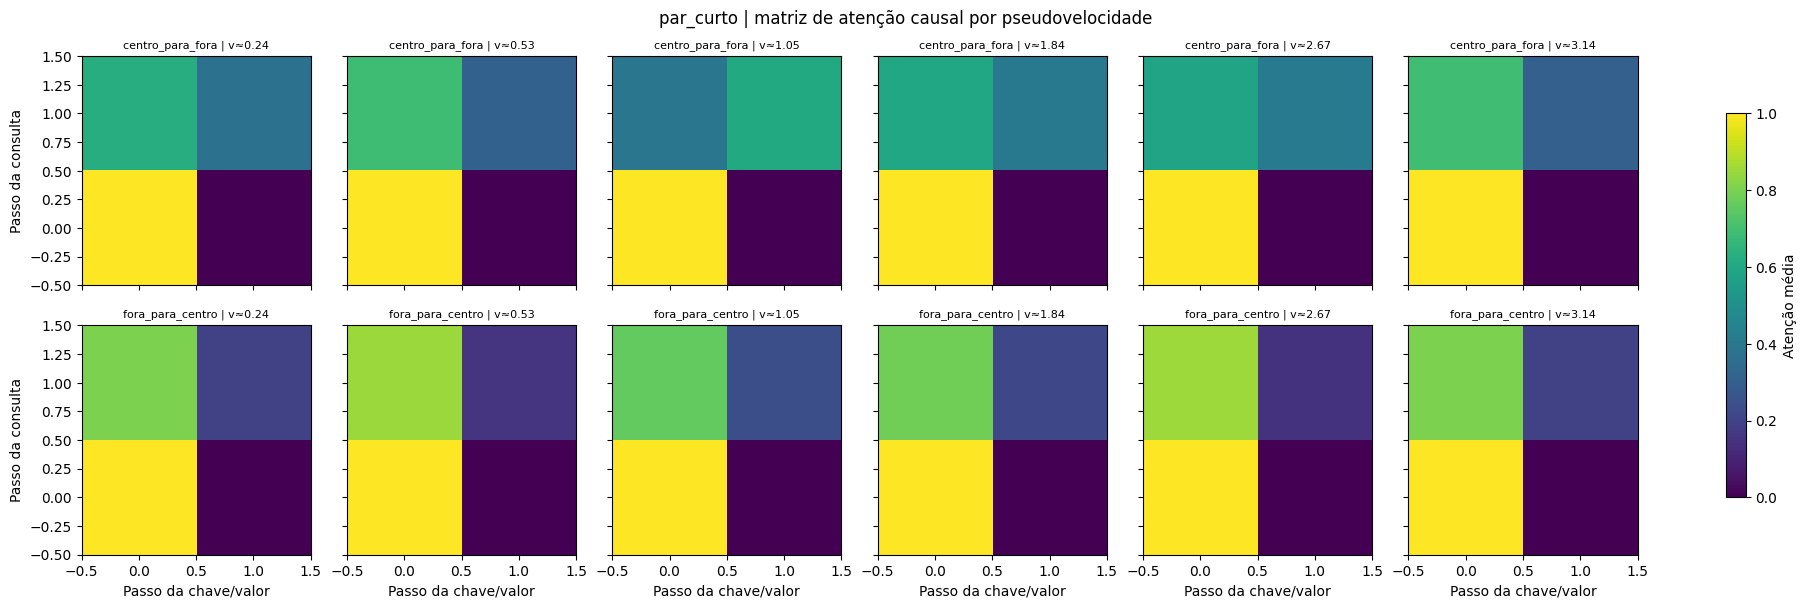

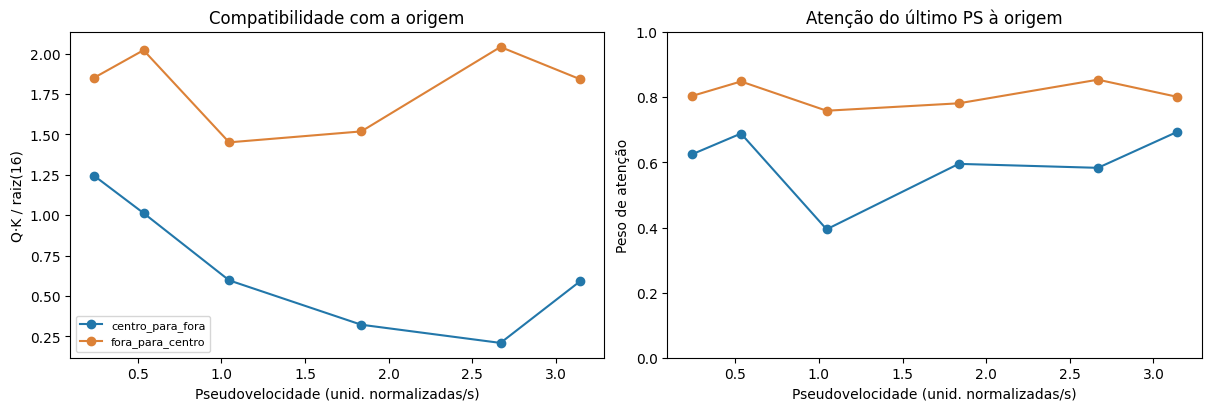

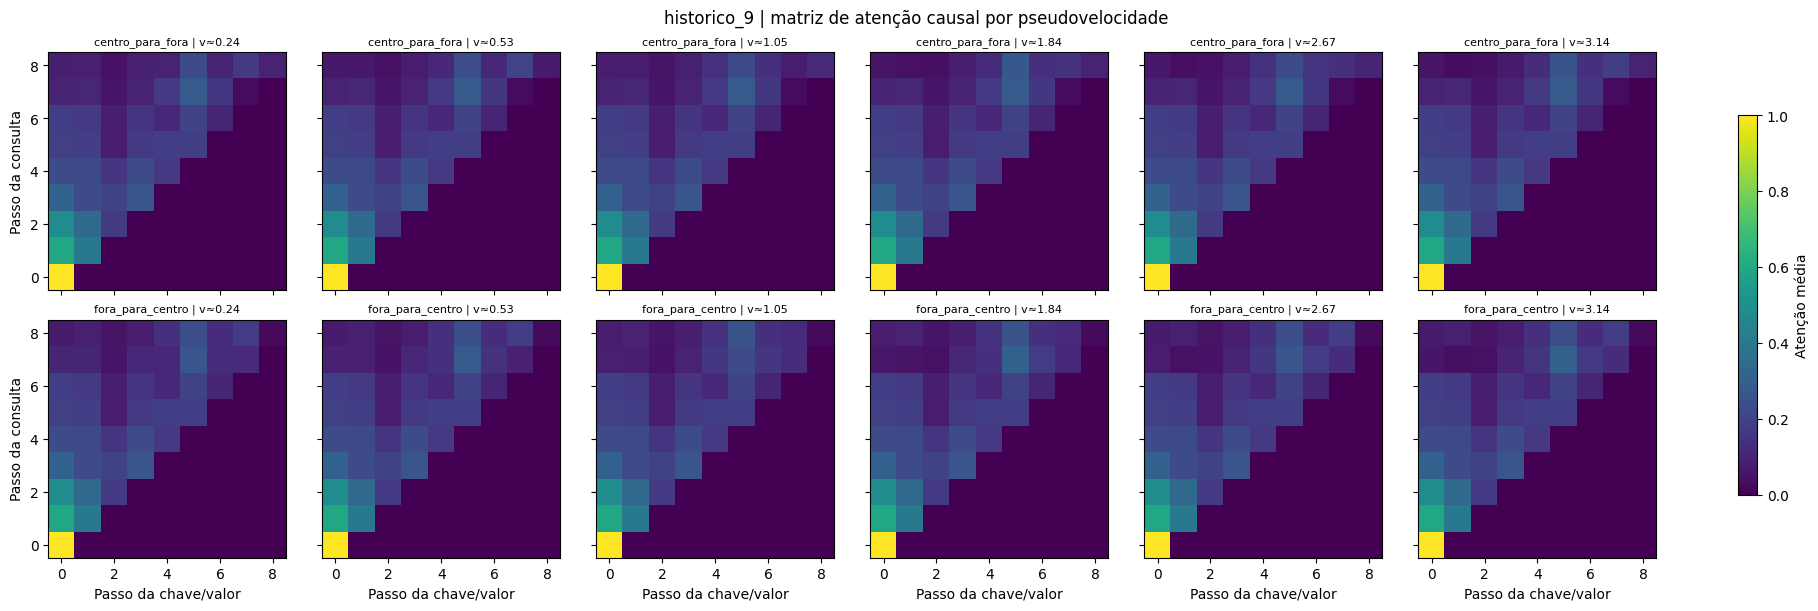

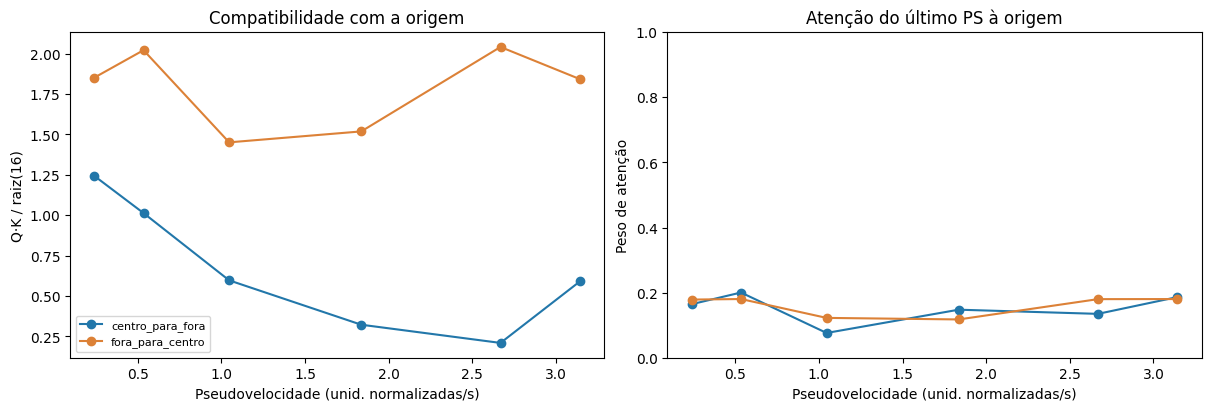

Resultados Q/K/V e atenção salvos em dois arquivos Parquet e em imgs/.


In [21]:
for mode,batches,metadata in [('par_curto',inputs,meta),('historico_9',full_inputs,full_meta)]:
    part=qkv_attention[qkv_attention['mode']==mode]
    matrices={}
    array=attention_arrays[mode]
    for direction in order:
        for ring in range(len(radii)):
            rows=np.flatnonzero((metadata.direction==direction).to_numpy() &
                                (metadata.ring==ring).to_numpy())
            matrices[(direction,ring)]=array[rows].mean(axis=0)
    fig,axes=plt.subplots(2,len(radii),figsize=(18,6),sharex=True,sharey=True,constrained_layout=True)
    for row,direction in enumerate(order):
        for ring,v in enumerate(speed_ticks):
            ax=axes[row,ring]
            im=ax.imshow(matrices[(direction,ring)],origin='lower',cmap='viridis',vmin=0,vmax=1)
            ax.set_title(f'{direction} | v≈{v:.2f}',fontsize=8)
            if row==1:ax.set_xlabel('Passo da chave/valor')
            if ring==0:ax.set_ylabel('Passo da consulta')
    fig.colorbar(im,ax=axes,shrink=.75,label='Atenção média')
    fig.suptitle(mode+' | matriz de atenção causal por pseudovelocidade')
    fig.savefig(root/f'imgs/hardpos_qkv_contexto10_atencao_{mode}.png',dpi=140,bbox_inches='tight')
    display(fig)
    plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    for direction,color in zip(order,['#2277aa','#dc8137']):
        g=part[part.direction==direction].groupby('ring').agg(
            speed=('speed_proxy','mean'),score=('qk_source_logit','mean'),
            attention=('attention_to_source','mean'))
        axes[0].plot(g.speed,g.score,marker='o',color=color,label=direction)
        axes[1].plot(g.speed,g.attention,marker='o',color=color,label=direction)
    axes[0].set(xlabel='Pseudovelocidade (unid. normalizadas/s)',ylabel='Q·K / raiz(16)',
                title='Compatibilidade com a origem')
    axes[1].set(xlabel='Pseudovelocidade (unid. normalizadas/s)',ylabel='Peso de atenção',
                ylim=(0,1),title='Atenção do último PS à origem')
    axes[0].legend(fontsize=8)
    fig.savefig(root/f'imgs/hardpos_qkv_contexto10_qk_origem_{mode}.png',dpi=150,bbox_inches='tight')
    display(fig)
    plt.close(fig)
print('Resultados Q/K/V e atenção salvos em dois arquivos Parquet e em imgs/.')

**Leitura causal:** no sentido centro → fora, o PS da posição 7 é fixo, e Q/K/V dessa posição não variam com a pseudovelocidade; a posição 8 muda. No sentido fora → centro, a posição 7 muda e a posição 8 contém sempre o mesmo PS central, portanto Q/K/V da posição 8 são fixos. Uma variação da saída de atenção no último passo desse segundo sentido vem da interação entre a consulta fixa e as chaves/valores anteriores. Uma associação com a pseudovelocidade sintética ainda pode refletir identidade ou posição do PS, não velocidade biológica.

Nos dados executados, a variação de qualquer dimensão de Q/K/V entre os seis grupos é exatamente zero no passo com PS fixo: passo 7 em centro → fora e passo 8 em fora → centro. No passo com PS variável, as projeções mudam. O peso médio de atenção à origem no contexto completo variou de 0,076 a 0,200 em centro → fora e de 0,118 a 0,180 em fora → centro, sem crescimento regular com a pseudovelocidade. Esse padrão, por si só, não caracteriza uma speed cell.

## Interpretação

Se a mesma unidade variar com a distância ao manter o destino central fixo, sua resposta não pode ser explicada apenas pelo embedding do PS final. Para chamar essa resposta de velocidade, ainda é preciso mostrar relação com deslocamento por unidade de tempo em trajetórias realistas e intervalos conhecidos. Os pares distantes deste notebook testam uma intervenção fora das transições habituais e podem ativar respostas a entradas improváveis.

O teste com histórico real permite observar se a resposta dos pares isolados muda quando o modelo recebe a escala de contexto usada no treino.